# **Import required libraries**

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

# **Import dataset**

In [3]:
df=pd.read_csv("DATA_Levels_Fyi_Salary_Data.csv")
display(df)

,timestamp,company,level,title,totalyearlycompensation,location,yearsofexperience,yearsatcompany,tag,basesalary,...,Doctorate_Degree,Highschool,Some_College,Race_Asian,Race_White,Race_Two_Or_More,Race_Black,Race_Hispanic,Race,Education
0,6/7/17 11:33,Oracle,L3,Product Manager,127000,"Redwood City, CA",1.5,1.5,NaN,107000,...,0,0,0,0,0,0,0,0,NaN,NaN
1,6/10/17 17:11,eBay,SE 2,Software Engineer,100000,"San Francisco, CA",5.0,3.0,NaN,0,...,0,0,0,0,0,0,0,0,NaN,NaN
2,6/11/17 14:53,Amazon,L7,Product Manager,310000,"Seattle, WA",8.0,0.0,NaN,155000,...,0,0,0,0,0,0,0,0,NaN,NaN
3,6/17/17 0:23,Apple,M1,Software Engineering Manager,372000,"Sunnyvale, CA",7.0,5.0,NaN,157000,...,0,0,0,0,0,0,0,0,NaN,NaN
4,6/20/17 10:58,Microsoft,60,Software Engineer,157000,"Mountain View, CA",5.0,3.0,NaN,0,...,0,0,0,0,0,0,0,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62637,9/9/18 11:52,Google,T4,Software Engineer,327000,"Seattle, WA",10.0,1.0,Distributed Systems (Back-End),155000,...,0,0,0,0,0,0,0,0,NaN,NaN
62638,9/13/18 8:23,Microsoft,62,Software Engineer,237000,"Redmond, WA",2.0,2.0,Full Stack,146900,...,0,0,0,0,0,0,0,0,NaN,NaN
62639,9/13/18 14:35,MSFT,63,Software Engineer,220000,"Seattle, WA",14.0,12.0,Full Stack,157000,...,0,0,0,0,0,0,0,0,NaN,NaN
62640,9/16/18 16:10,Salesforce,Lead MTS,Software Engineer,280000,"San Francisco, CA",8.0,4.0,iOS,194688,...,0,0,0,0,0,0,0,0,NaN,NaN


# Data Cleaning (Round 2) Creates dfc the cleaned data frame
Clean the dataframe `df` loaded from "DATA_Levels_Fyi_Salary_Data.csv" to create a new dataframe `dfc`. The cleaning should address missing values (including 'Unknown' values in 'company', 'level', and 'tag'), inconsistent data formats, spacing, abbreviations, and ensure numerical fields contain only numerical data. Keep the original dataframe `df`.

## Clean dataset


In [18]:
dfc = df.copy()

# Drop the 'otherdetails' column
dfc = dfc.drop('otherdetails', axis=1)

# Drop the 'dmaid' column
dfc = dfc.drop('dmaid', axis=1)


# Impute missing values in the 'Education' column with the mode
if not dfc['Education'].isnull().all():
    dfc['Education'].fillna(dfc['Education'].mode()[0], inplace=True)
else:
    dfc['Education'].fillna('Unknown', inplace=True)

# Impute missing values in the 'gender' column with 'Not Specified'
dfc['gender'].fillna('Not Specified', inplace=True)


# Remove salary outliers using IQR
Q1 = dfc['totalyearlycompensation'].quantile(0.25)
Q3 = dfc['totalyearlycompensation'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

dfc = dfc[(dfc['totalyearlycompensation'] >= lower_bound) & (dfc['totalyearlycompensation'] <= upper_bound)]

# Also remove totalyearlycompensation under 20K
dfc = dfc[dfc['totalyearlycompensation'] >= 20000]


# Impute missing values in the 'Race' column with the mode
if not dfc['Race'].isnull().all():
    dfc['Race'].fillna(dfc['Race'].mode()[0], inplace=True)
else:
    dfc['Race'].fillna('Unknown', inplace=True)


# Impute missing values in the 'company', 'level', and 'tag' columns
dfc['company'].fillna('Unknown Company', inplace=True)
dfc['level'].fillna('Unknown Level', inplace=True)
dfc['tag'].fillna('Unknown Tag', inplace=True)

# Filter out companies that occur less than 5 times
company_counts = dfc['company'].value_counts()
companies_to_keep = company_counts[company_counts >= 30].index
dfc = dfc[dfc['company'].isin(companies_to_keep)]

#company clean up --
dfc['company'] = dfc['company'].replace(['Ama', 'Amazon web', 'Amazon Web', 'Amazon.com', 'Amzon', 'AWS'], 'Amazon')
dfc['company'] = dfc['company'].replace('Apple Inc.', 'Apple')
dfc['company'] = dfc['company'].replace("Macy's,", "Macy's")
dfc['company'] = dfc['company'].replace(["Microsoft Corporation", "Msft"], "Microsoft")
dfc['company'] = dfc['company'].str.replace('Deloitte.*', 'Deloitte', regex=True)
dfc['company'] = dfc['company'].str.replace('Google.*', 'Google', regex=True)


#Level clean up --
dfc.loc[(dfc['company'] == 'Amazon') & (dfc['level'].astype(str).str.match(r'^[1-7]$')), 'level'] = 'L' + dfc['level'].astype(str)

# # Impute 0 values in compensation and bonus columns with their mean
# compensation_cols = ['basesalary', 'totalyearlycompensation', 'bonus', 'stockgrantvalue']
# for col in compensation_cols:
#     mean_val = dfc[dfc[col] != 0][col].mean()
#     dfc[col] = dfc[col].replace(0, mean_val)

# Impute 0 values in years of experience with 1
dfc['yearsofexperience'] = dfc['yearsofexperience'].replace(0, 1)

# Impute 0 values in years at company with 1
dfc['yearsatcompany'] = dfc['yearsatcompany'].replace(0, 1)

# Impute values less than 1 in yearsatcompany with 1
dfc.loc[dfc['yearsatcompany'] < 1, 'yearsatcompany'] = 1


# Handle inconsistent data formats, spacing, and abbreviations
# Clean 'gender' column - replace the inconsistent value with 'Other'
dfc['gender'] = dfc['gender'].replace('Title: Senior Software Engineer', 'Other')

# Clean 'company', 'level', 'title', 'location', and 'tag' columns - convert to lowercase and strip whitespace
for col in ['company', 'level', 'title', 'location', 'tag']:
    dfc[col] = dfc[col].astype(str).str.lower().str.strip()

# Clean 'Education' column - strip leading/trailing whitespace
dfc['Education'] = dfc['Education'].astype(str).str.strip()

# Display data types after standardization
print("Data types after standardization:")
print(dfc.dtypes)

# Iterate through the cleaned categorical columns and print unique value counts and top 5 frequent values
categorical_columns_to_verify = ['company', 'level', 'title', 'location', 'tag', 'gender', 'Education']
for col in categorical_columns_to_verify:
    print(f"\nColumn: '{col}'")
    print(f"Number of unique values: {dfc[col].nunique()}")
    print(f"Top 5 most frequent values:\n{dfc[col].value_counts().head()}")


# Handle inconsistent data formats, spacing, and abbreviations
# Clean 'gender' column - replace the inconsistent value with 'Other'
dfc['gender'] = dfc['gender'].replace('Title: Senior Software Engineer', 'Other')

# Clean 'company', 'level', 'title', 'location', and 'tag' columns - convert to lowercase and strip whitespace
for col in ['company', 'level', 'title', 'location', 'tag']:
    dfc[col] = dfc[col].astype(str).str.lower().str.strip()

# Clean 'Education' column - strip leading/trailing whitespace
dfc['Education'] = dfc['Education'].astype(str).str.strip()

# Display data types after standardization
print("Data types after standardization:")
print(dfc.dtypes)

# Iterate through the cleaned categorical columns and print unique value counts and top 5 frequent values
categorical_columns_to_verify = ['company', 'level', 'title', 'location', 'tag', 'gender', 'Education']
for col in categorical_columns_to_verify:
    print(f"\nColumn: '{col}'")
    print(f"Number of unique values: {dfc[col].nunique()}")
    print(f"Top 5 most frequent values:\n{dfc[col].value_counts().head()}")



# Print the number of remaining rows
print(f"Remaining Rows: {dfc.shape[0]}")

# Check the number of missing values per column
print("\nMissing values after cleaning:")
print(dfc.isnull().sum())

print (dfc.head())

Data types after standardization:
timestamp                   object
company                     object
level                       object
title                       object
totalyearlycompensation      int64
location                    object
yearsofexperience          float64
yearsatcompany             float64
tag                         object
basesalary                   int64
stockgrantvalue            float64
bonus                      float64
gender                      object
cityid                       int64
rowNumber                    int64
Masters_Degree               int64
Bachelors_Degree             int64
Doctorate_Degree             int64
Highschool                   int64
Some_College                 int64
Race_Asian                   int64
Race_White                   int64
Race_Two_Or_More             int64
Race_Black                   int64
Race_Hispanic                int64
Race                        object
Education                   object
dtype: object

Column

In [19]:
count_of_rows = dfc.shape[0]
print(f"Number of rows in the DataFrame: {count_of_rows}")

Number of rows in the DataFrame: 49743


In [20]:
min_year = dfc['yearsatcompany'].min()

min_year

1.0

In [21]:
import numpy as np
import pandas as pd

# Impute 0/low values in years of experience and years at company (keeping existing logic)
dfc['yearsofexperience'] = dfc['yearsofexperience'].replace(0, 1)
dfc['yearsatcompany'] = dfc['yearsatcompany'].replace(0, 1)
dfc.loc[dfc['yearsatcompany'] < 1, 'yearsatcompany'] = 1


# Convert integer columns to Int64
integer_cols = ['totalyearlycompensation', 'basesalary', 'cityid', 'rowNumber',
                'Masters_Degree', 'Bachelors_Degree', 'Doctorate_Degree', 'Highschool',
                'Some_College', 'Race_Asian', 'Race_White', 'Race_Two_Or_More',
                'Race_Black', 'Race_Hispanic']
integer_cols = [col for col in integer_cols if col in dfc.columns]

for col in integer_cols:
    # Handle potential NaNs before converting to Int64
    dfc[col] = dfc[col].round()
    dfc[col] = dfc[col].astype('Int64')

# Ensure remaining numerical columns are float
float_cols = ['yearsofexperience', 'yearsatcompany', 'stockgrantvalue', 'bonus']
float_cols = [col for col in float_cols if col in dfc.columns]

for col in float_cols:
     # Handle potential NaNs in these float columns after summing/imputation
    dfc[col] = dfc[col].astype(float)


# Display data types and check for missing values
print("\nData types after ensuring numerical types and handling compensation:")
print(dfc.dtypes)

print("\nMissing values in numerical columns after type conversion and imputation:")
all_numeric_cols_after = dfc.select_dtypes(include=np.number).columns.tolist()
print(dfc[all_numeric_cols_after].isnull().sum())

min_totalyearlycompensation = dfc['totalyearlycompensation'].min()
print(f"\nMinimum value of totalyearlycompensation after processing: {min_totalyearlycompensation}")


Data types after ensuring numerical types and handling compensation:
timestamp                   object
company                     object
level                       object
title                       object
totalyearlycompensation      Int64
location                    object
yearsofexperience          float64
yearsatcompany             float64
tag                         object
basesalary                   Int64
stockgrantvalue            float64
bonus                      float64
gender                      object
cityid                       Int64
rowNumber                    Int64
Masters_Degree               Int64
Bachelors_Degree             Int64
Doctorate_Degree             Int64
Highschool                   Int64
Some_College                 Int64
Race_Asian                   Int64
Race_White                   Int64
Race_Two_Or_More             Int64
Race_Black                   Int64
Race_Hispanic                Int64
Race                        object
Education           

In [22]:
median_totalyearlycompensation = dfc['totalyearlycompensation'].median()
print(f"Median of totalyearlycompensation: {median_totalyearlycompensation}")

average_totalyearlycompensation = dfc['totalyearlycompensation'].mean()
print(f"Average of totalyearlycompensation: {average_totalyearlycompensation}")

difference = median_totalyearlycompensation - average_totalyearlycompensation
print(f"Difference between median and average: {difference}")

Median of totalyearlycompensation: 191000.0
Average of totalyearlycompensation: 204416.15917817582
Difference between median and average: -13416.159178175818


## "Tag" Refinement

In [23]:
# the tag column is a valuable one but requires extensive cleaning as this was a
# survey. Many of them are associated, for example, anything containing AI or ML
# should be AI / ML. I technically only care about this for the top 20 or so
# companies. Could you review the column, and as an LLM, replace the values so they're related?

## Create cleaned dataframe
#
# ### Subtask: Create a new dataframe `dfc` with the cleaned data while keeping
# the original `df`. %%

In [24]:
# Clean the 'tag' column by grouping similar tags
def clean_tags(tag):
    if pd.isna(tag) or tag is None:
        return 'Unknown Tag'
    tag = str(tag).lower().strip() # Ensure tag is a string and handle potential None/NaN

    if 'ai' in tag or 'ml' in tag or 'machine learning' in tag or 'artificial intelligence' in tag:
        return 'ml / ai'
    elif 'web' in tag or 'frontend' in tag or 'front end' in tag:
        return 'web development (front-end)'
    elif 'backend' in tag or 'back end' in tag or 'distributed systems' in tag or 'api' in tag:
        return 'distributed systems (back-end)'
    elif 'mobile' in tag or 'ios' in tag or 'android' in tag:
        return 'mobile development'
    elif 'data science' in tag or 'data scientist' in tag or 'big data' in tag:
        return 'data science'
    elif 'security' in tag or 'cybersecurity' in tag:
        return 'security'
    elif 'devops' in tag or 'sre' in tag or 'site reliability' in tag:
        return 'Infrastructure'
    elif 'testing' in tag or 'qa' in tag:
        return 'qa / testing'
    elif 'manager' in tag or 'management' in tag:
        return 'management'
    elif 'product' in tag:
        return 'product'
    elif 'design' in tag or 'ux' in tag or 'ui' in tag:
        return 'design / ux'
    elif 'hardware' in tag:
        return 'hardware'
    elif 'consultant' in tag:
        return 'consulting'
    elif 'technical program manager' in tag:
        return 'technical program management'
    elif 'business analyst' in tag:
        return 'business analysis'
    elif 'human resources' in tag or 'hr' in tag:
        return 'human resources'
    elif 'marketing' in tag:
        return 'marketing'
    elif 'sales' in tag:
        return 'sales'
    elif 'recruiter' in tag:
        return 'recruiting'
    elif 'full stack' in tag:
        return 'full stack'
    elif 'embedded' in tag:
        return 'embedded systems'
    elif 'networking' in tag:
        return 'networking'
    elif 'database' in tag:
        return 'database'
    elif 'cloud' in tag or 'aws' in tag or 'azure' in tag or 'gcp' in tag:
        return 'cloud computing'
    elif 'site reliability engineer' in tag:
        return 'Infrastructure'
    elif 'infra' in tag or 'infrastructure' in tag:
        return 'infrastructure'
    elif 'support' in tag:
        return 'support'
    else:
        return 'Other'

# Apply the cleaning function to the 'tag' column
dfc['tag'] = dfc['tag'].apply(clean_tags)

# Identify the top 20 companies (keeping this for potential future use, although not currently filtering by it)
top_companies = dfc['company'].value_counts().nlargest(20).index.tolist()

# The line to group tags into 'other' for non-top companies is removed.

# Display the value counts of the cleaned 'tag' column
print("Value counts after tag cleaning:")
print(dfc['tag'].value_counts().head(50)) # Display top 50 to see more categories

Value counts after tag cleaning:
tag
distributed systems (back-end)    13827
full stack                         8865
Other                              8771
ml / ai                            3621
mobile development                 2446
web development (front-end)        2281
product                            1913
Infrastructure                     1834
design / ux                        1475
security                           1020
networking                          986
qa / testing                        661
cloud computing                     401
embedded systems                    327
hardware                            280
management                          256
sales                               252
infrastructure                      147
marketing                           126
data science                        111
human resources                      83
database                             20
support                              16
consulting                           15
bus

In [25]:
# Perform one-hot encoding on the 'tag' column
tags_encoded = pd.get_dummies(dfc, columns=['tag'], prefix='tag')

# Display the first few rows of the new dataframe with one-hot encoded tags
display(tags_encoded.head())

# Display the columns of the new dataframe to see the new tag columns
print("\nColumns after one-hot encoding:")
print(tags_encoded.columns)

# Select relevant original columns and the one-hot encoded tag columns
tag_columns = [col for col in tags_encoded.columns if col.startswith('tag_')]
columns_to_display = ['company', 'title'] + tag_columns

# Filter rows where at least one one-hot encoded tag column is True, excluding 'tag_Unknown Tag'
# First, create a list of tag columns excluding 'tag_Unknown Tag'
tag_columns_excluding_unknown = [col for col in tag_columns if col != 'tag_Unknown Tag']

# Now, filter rows where any of these selected tag columns are True
rows_with_known_tags = tags_encoded[tags_encoded[tag_columns_excluding_unknown].any(axis=1)]


# Display the first few rows of the filtered dataframe, including original 'company' and 'title'
display(rows_with_known_tags[columns_to_display].head())

,timestamp,company,level,title,totalyearlycompensation,location,yearsofexperience,yearsatcompany,basesalary,stockgrantvalue,...,tag_marketing,tag_ml / ai,tag_mobile development,tag_networking,tag_product,tag_qa / testing,tag_sales,tag_security,tag_support,tag_web development (front-end)
0,6/7/17 11:33,oracle,l3,product manager,127000,"redwood city, ca",1.5,1.5,107000,20000.0,...,False,False,False,False,False,False,False,False,False,False
1,6/10/17 17:11,ebay,se 2,software engineer,100000,"san francisco, ca",5.0,3.0,0,0.0,...,False,False,False,False,False,False,False,False,False,False
2,6/11/17 14:53,amazon,l7,product manager,310000,"seattle, wa",8.0,1.0,155000,0.0,...,False,False,False,False,False,False,False,False,False,False
3,6/17/17 0:23,apple,m1,software engineering manager,372000,"sunnyvale, ca",7.0,5.0,157000,180000.0,...,False,False,False,False,False,False,False,False,False,False
4,6/20/17 10:58,microsoft,60,software engineer,157000,"mountain view, ca",5.0,3.0,0,0.0,...,False,False,False,False,False,False,False,False,False,False



Columns after one-hot encoding:
Index(['timestamp', 'company', 'level', 'title', 'totalyearlycompensation',
       'location', 'yearsofexperience', 'yearsatcompany', 'basesalary',
       'stockgrantvalue', 'bonus', 'gender', 'cityid', 'rowNumber',
       'Masters_Degree', 'Bachelors_Degree', 'Doctorate_Degree', 'Highschool',
       'Some_College', 'Race_Asian', 'Race_White', 'Race_Two_Or_More',
       'Race_Black', 'Race_Hispanic', 'Race', 'Education',
       'tag_Infrastructure', 'tag_Other', 'tag_business analysis',
       'tag_cloud computing', 'tag_consulting', 'tag_data science',
       'tag_database', 'tag_design / ux', 'tag_distributed systems (back-end)',
       'tag_embedded systems', 'tag_full stack', 'tag_hardware',
       'tag_human resources', 'tag_infrastructure', 'tag_management',
       'tag_marketing', 'tag_ml / ai', 'tag_mobile development',
       'tag_networking', 'tag_product', 'tag_qa / testing', 'tag_sales',
       'tag_security', 'tag_support', 'tag_web develop

,company,title,tag_Infrastructure,tag_Other,tag_business analysis,tag_cloud computing,tag_consulting,tag_data science,tag_database,tag_design / ux,...,tag_marketing,tag_ml / ai,tag_mobile development,tag_networking,tag_product,tag_qa / testing,tag_sales,tag_security,tag_support,tag_web development (front-end)
0,oracle,product manager,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,ebay,software engineer,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,amazon,product manager,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,apple,software engineering manager,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,microsoft,software engineer,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## Create cleaned dataframe

### Subtask:
Create a new dataframe `dfc` with the cleaned data while keeping the original `df`.


In [26]:
dfc = df.copy()

# Evaluating "Tags"

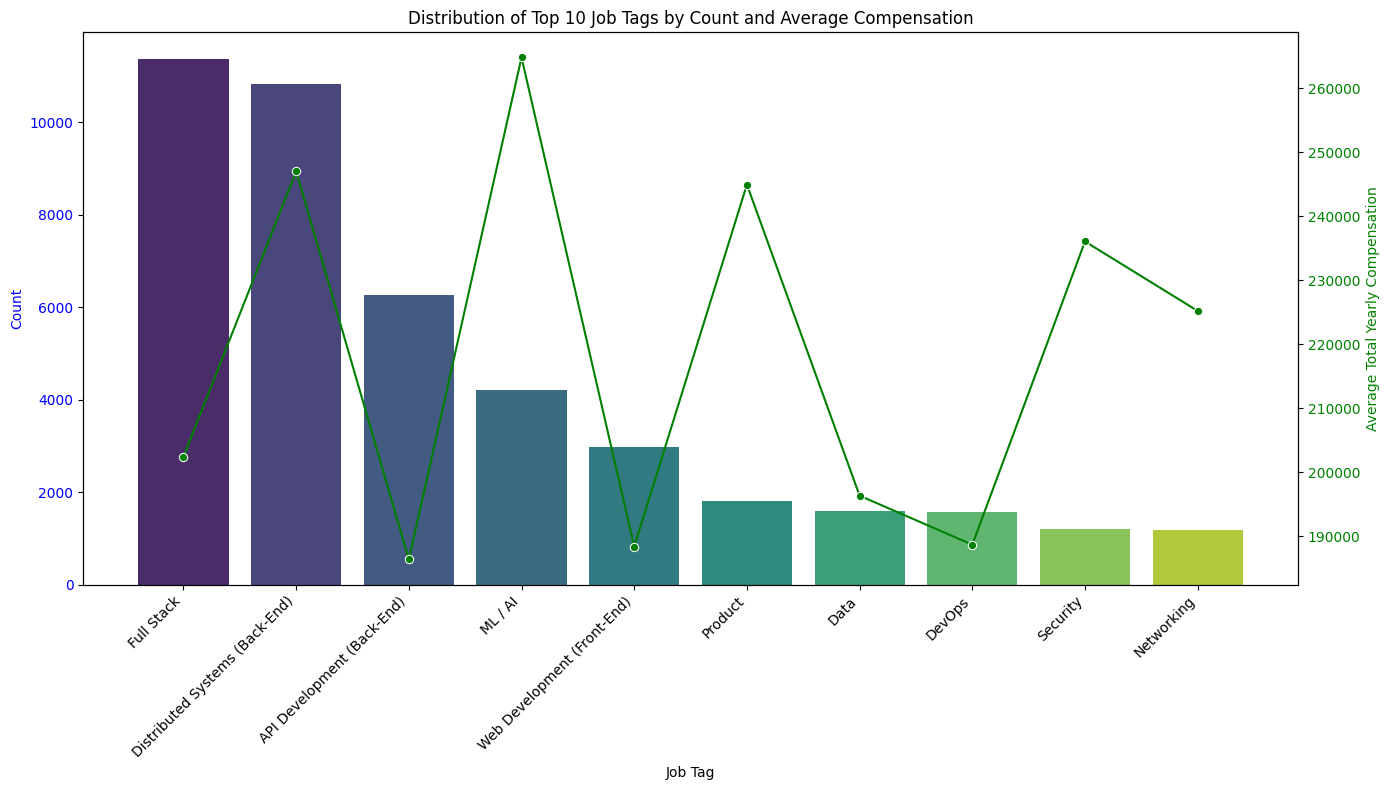


Filtering data for violin plot: Using observations with Total Yearly Compensation between $65,000 (10th percentile) and $457,000 (95th percentile)
Number of observations after filtering: 38516


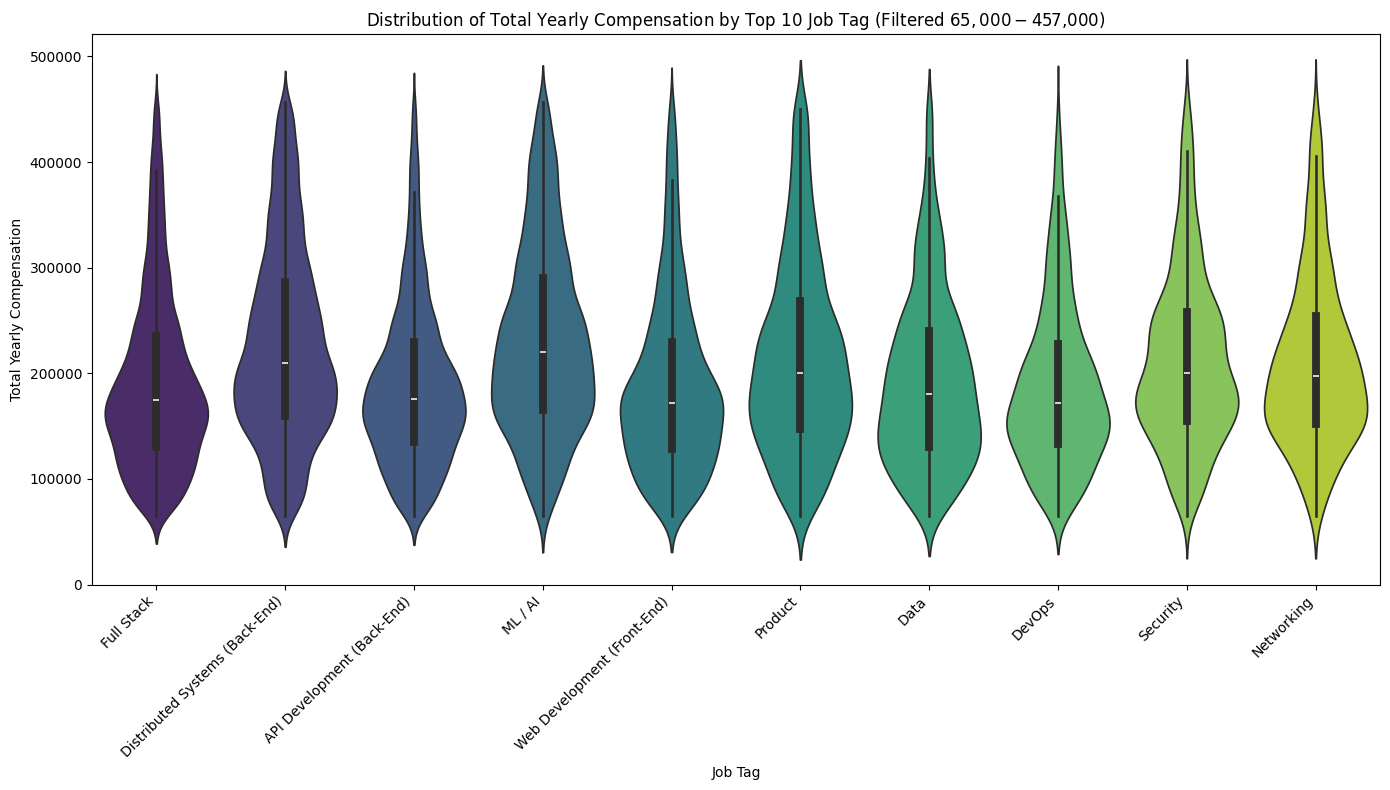

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc is available and cleaned

# Filter out 'Unknown Tag' and 'Other' tags
known_tags_dfc = dfc[~dfc['tag'].isin(['Unknown Tag', 'Other'])].copy()

# Get the value counts of known tags
tag_counts = known_tags_dfc['tag'].value_counts()

# Select the top 10 tags by count
top_10_tags = tag_counts.nlargest(10).index.tolist()

# Filter the dataframe to include only the top 10 tags
known_tags_top_10_dfc = known_tags_dfc[known_tags_dfc['tag'].isin(top_10_tags)].copy()

# Get the value counts of the top 10 tags (to ensure correct order in plot)
tag_counts_top_10 = known_tags_top_10_dfc['tag'].value_counts().reindex(top_10_tags)


# Calculate the average total yearly compensation for the top 10 tags
average_compensation_by_tag_top_10 = known_tags_top_10_dfc.groupby('tag')['totalyearlycompensation'].mean().reindex(top_10_tags)


# Combine the two series into a single DataFrame for easier plotting
combined_data_top_10 = pd.DataFrame({
    'count': tag_counts_top_10,
    'average_compensation': average_compensation_by_tag_top_10
}) # No need to sort again as both series are reindexed to top_10_tags order

# Create a figure and a set of subplots with a shared x-axis
fig, ax1 = plt.subplots(figsize=(14, 8))

# Plot the counts on the first y-axis
sns.barplot(x=combined_data_top_10.index, y=combined_data_top_10['count'], ax=ax1, palette='viridis')
ax1.set_xlabel('Job Tag')
ax1.set_ylabel('Count', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xticklabels(combined_data_top_10.index, rotation=45, ha='right') # Rotate x-axis labels

# Create a second y-axis for the average compensation
ax2 = ax1.twinx()
sns.lineplot(x=combined_data_top_10.index, y=combined_data_top_10['average_compensation'], ax=ax2, color='green', marker='o', sort=False) # Changed color to green
ax2.set_ylabel('Average Total Yearly Compensation', color='green') # Changed color to green
ax2.tick_params(axis='y', labelcolor='green')

plt.title('Distribution of Top 10 Job Tags by Count and Average Compensation')
plt.tight_layout()
plt.show()

# Calculate the 10th and 95th percentiles of total yearly compensation from the *full* dataset
# to define a relevant range for visualization, avoiding extreme outliers on both ends.
comp_threshold_5 = known_tags_dfc['totalyearlycompensation'].quantile(0.05)
comp_threshold_95 = known_tags_dfc['totalyearlycompensation'].quantile(0.95)

# Filter data to include only observations within this range for the violin plot
known_tags_top_10_dfc_filtered = known_tags_top_10_dfc[
    (known_tags_top_10_dfc['totalyearlycompensation'] >= comp_threshold_5) &
    (known_tags_top_10_dfc['totalyearlycompensation'] <= comp_threshold_95)
].copy()

print(f"\nFiltering data for violin plot: Using observations with Total Yearly Compensation between ${comp_threshold_5:,.0f} (10th percentile) and ${comp_threshold_95:,.0f} (95th percentile)")
print(f"Number of observations after filtering: {known_tags_top_10_dfc_filtered.shape[0]}")


# Create a violin plot of total yearly compensation for the top 10 tags with filtered data
plt.figure(figsize=(14, 8))
# Order the violin plots by the counts of the tags (descending) - use the original top_10_tags list for ordering consistency
order = tag_counts[top_10_tags].index
sns.violinplot(data=known_tags_top_10_dfc_filtered, x='tag', y='totalyearlycompensation', order=order, palette='viridis')
plt.title(f'Distribution of Total Yearly Compensation by Top 10 Job Tag (Filtered ${comp_threshold_5:,.0f} - ${comp_threshold_95:,.0f})') # Update title
plt.xlabel('Job Tag')
plt.ylabel('Total Yearly Compensation')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels
plt.tight_layout()
plt.show()

In [24]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Assuming known_tags_top_10_dfc_filtered is available from previous cells
# This DataFrame contains the top 10 tags and filtered compensation data

print("--- Predicting Average Compensation for Top 10 Job Tags ---")

# Calculate the average total yearly compensation for each of the top 10 tags
# Use known_tags_top_10_dfc_filtered which is already filtered and contains only the top 10 tags
average_compensation_by_tag = known_tags_top_10_dfc_filtered.groupby('tag')['totalyearlycompensation'].mean().reset_index()

# Prepare data for modeling
# Features (X): Create dummy variables for each tag
X = pd.get_dummies(average_compensation_by_tag['tag'], prefix='tag')

# Target (y): The average compensation for each tag
y = average_compensation_by_tag['totalyearlycompensation']

# The number of data points here is small (number of top tags), so splitting is not ideal
# We will train on the full dataset to get the predicted values for each tag directly.

print(f"Training models on {X.shape[0]} data points (one for each top tag).")

# 1. Linear Regression Model
print("\nTraining Linear Regression model...")
lr_model = LinearRegression()
lr_model.fit(X, y)

# Predict the average compensation for each tag using the trained model
y_pred_lr = lr_model.predict(X)

# Evaluate the model (optional for this case, as we are training on all data)
mae_lr = mean_absolute_error(y, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y, y_pred_lr))
print(f"  Linear Regression - MAE: {mae_lr:.2f}, RMSE: {rmse_lr:.2f}")

# Get the predicted values with tag names
predicted_comp_lr = pd.DataFrame({'tag': average_compensation_by_tag['tag'], 'Predicted_Comp_LR': y_pred_lr})
print("\nLinear Regression Predicted Average Compensation by Tag:")
display(predicted_comp_lr)


# 2. Gradient Boosting Regressor Model
print("\nTraining Gradient Boosting Regressor model...")
# Adjust n_estimators for small dataset if needed, or keep as is for consistency
gb_model = GradientBoostingRegressor(n_estimators=50, random_state=42) # Reduced estimators
gb_model.fit(X, y)

# Predict the average compensation for each tag
y_pred_gb = gb_model.predict(X)

# Evaluate the model
mae_gb = mean_absolute_error(y, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y, y_pred_gb))
print(f"  Gradient Boosting - MAE: {mae_gb:.2f}, RMSE: {rmse_gb:.2f}")

predicted_comp_gb = pd.DataFrame({'tag': average_compensation_by_tag['tag'], 'Predicted_Comp_GB': y_pred_gb})
print("\nGradient Boosting Predicted Average Compensation by Tag:")
display(predicted_comp_gb)


# 3. Random Forest Regressor Model
print("\nTraining Random Forest Regressor model...")
# Adjust n_estimators for small dataset if needed
rf_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1) # Reduced estimators
rf_model.fit(X, y)

# Predict the average compensation for each tag
y_pred_rf = rf_model.predict(X)

# Evaluate the model
mae_rf = mean_absolute_error(y, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y, y_pred_rf))
print(f"  Random Forest - MAE: {mae_rf:.2f}, RMSE: {rmse_rf:.2f}")


predicted_comp_rf = pd.DataFrame({'tag': average_compensation_by_tag['tag'], 'Predicted_Comp_RF': y_pred_rf})
print("\nRandom Forest Predicted Average Compensation by Tag:")
display(predicted_comp_rf)

print("\nPrediction analysis complete.")

--- Predicting Average Compensation for Top 10 Job Tags ---
Training models on 10 data points (one for each top tag).

Training Linear Regression model...
  Linear Regression - MAE: 0.00, RMSE: 0.00

Linear Regression Predicted Average Compensation by Tag:


,tag,Predicted_Comp_LR
0,API Development (Back-End),189372.021183
1,Data,193352.617080
2,DevOps,188012.379642
3,Distributed Systems (Back-End),227289.919058
4,Full Stack,191373.956918
5,ML / AI,231622.083897
6,Networking,210655.669145
7,Product,214689.956332
8,Security,212623.978202
9,Web Development (Front-End),188715.201811



Training Gradient Boosting Regressor model...
  Gradient Boosting - MAE: 1409.64, RMSE: 1410.96

Gradient Boosting Predicted Average Compensation by Tag:


,tag,Predicted_Comp_GB
0,API Development (Back-End),190824.665300
1,Data,194758.679502
2,DevOps,189392.540958
3,Distributed Systems (Back-End),225877.661699
4,Full Stack,192697.519615
5,ML / AI,230132.046922
6,Networking,209354.230448
7,Product,213230.125314
8,Security,211239.351214
9,Web Development (Front-End),190200.962293



Training Random Forest Regressor model...
  Random Forest - MAE: 5756.40, RMSE: 6732.31

Random Forest Predicted Average Compensation by Tag:


,tag,Predicted_Comp_RF
0,API Development (Back-End),192863.990683
1,Data,197513.002317
2,DevOps,192289.845456
3,Distributed Systems (Back-End),215167.224741
4,Full Stack,195239.587366
5,ML / AI,219433.787287
6,Networking,207979.751367
7,Product,206644.839542
8,Security,209707.126555
9,Web Development (Front-End),192534.912919



Prediction analysis complete.


In [25]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Assuming known_tags_top_10_dfc_filtered is available from previous cells
# This DataFrame contains the top 10 tags and filtered compensation data

print("--- Predicting Increase in Total Compensation per Year of Experience by Tag ---")

# Get the list of top 10 tags from the filtered data
top_10_tags = known_tags_top_10_dfc_filtered['tag'].unique()

# Dictionary to store models and results for each tag
tag_models = {}
tag_predictions = {}
tag_evaluation = {}
estimated_increase_per_year = {}

# Iterate through each top tag and train regression models
for tag in top_10_tags:
    print(f"\nAnalyzing tag: '{tag}'")

    # Filter data for the current tag
    tag_df = known_tags_top_10_dfc_filtered[known_tags_top_10_dfc_filtered['tag'] == tag].copy()

    # Define feature (X) and target (y)
    # Feature: Years of Experience (ensure it's treated as a 2D array for scikit-learn)
    X = tag_df[['yearsofexperience']]
    # Target: Total Yearly Compensation
    y = tag_df['totalyearlycompensation']

    # Ensure there's enough data to train a model
    if len(tag_df) < 2:
        print(f"  Insufficient data for tag '{tag}' to train models.")
        continue

    # Split data into training and testing sets (optional, but good practice for evaluation)
    # For simplicity and to get a coefficient representative of the overall trend for the tag,
    # we will train on the full data for each tag. Evaluation metrics will reflect training performance.
    # If a rigorous test-set evaluation is needed, add train_test_split here.

    # 1. Linear Regression Model
    print(f"  Training Linear Regression model for '{tag}'...")
    lr_model = LinearRegression()
    lr_model.fit(X, y)
    tag_models[f'{tag}_lr'] = lr_model

    # The coefficient for 'yearsofexperience' represents the estimated linear increase per year
    lr_increase = lr_model.coef_[0]
    estimated_increase_per_year[f'{tag}_lr'] = lr_increase

    # Predict on the training data for evaluation
    y_pred_lr = lr_model.predict(X)
    mae_lr = mean_absolute_error(y, y_pred_lr)
    rmse_lr = np.sqrt(mean_squared_error(y, y_pred_lr))
    tag_evaluation[f'{tag}_lr'] = {'MAE': mae_lr, 'RMSE': rmse_lr, 'Estimated_Increase': lr_increase}

    print(f"    Linear Regression - Estimated increase per year: ${lr_increase:,.2f}")
    print(f"    Linear Regression - MAE: {mae_lr:.2f}, RMSE: {rmse_lr:.2f}")

    # 2. Gradient Boosting Regressor Model
    print(f"  Training Gradient Boosting Regressor model for '{tag}'...")
    gb_model = GradientBoostingRegressor(n_estimators=50, random_state=42)
    gb_model.fit(X, y)
    tag_models[f'{tag}_gb'] = gb_model

    # For tree-based models, we can approximate the increase over a range
    experience_range = np.array([[5], [10]]) # Example range
    if experience_range[1, 0] <= tag_df['yearsofexperience'].max() and experience_range[0, 0] >= tag_df['yearsofexperience'].min():
        predicted_comp_gb_range = gb_model.predict(experience_range)
        gb_increase = (predicted_comp_gb_range[1] - predicted_comp_gb_range[0]) / (experience_range[1, 0] - experience_range[0, 0])
        estimated_increase_per_year[f'{tag}_gb'] = gb_increase
        print(f"    Gradient Boosting - Approx. increase per year (5-10 yrs): ${gb_increase:,.2f}")
    else:
         print("    Gradient Boosting - Cannot approximate increase over 5-10 yrs (outside data range).")
         estimated_increase_per_year[f'{tag}_gb'] = np.nan


    # Predict on the training data for evaluation
    y_pred_gb = gb_model.predict(X)
    mae_gb = mean_absolute_error(y, y_pred_gb)
    rmse_gb = np.sqrt(mean_squared_error(y, y_pred_gb))
    tag_evaluation[f'{tag}_gb'] = {'MAE': mae_gb, 'RMSE': rmse_gb} # Note: Estimated_Increase stored separately


    print(f"    Gradient Boosting - MAE: {mae_gb:.2f}, RMSE: {rmse_gb:.2f}")


    # 3. Random Forest Regressor Model
    print(f"  Training Random Forest Regressor model for '{tag}'...")
    rf_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    rf_model.fit(X, y)
    tag_models[f'{tag}_rf'] = rf_model

    # For tree-based models, we can approximate the increase over a range
    if experience_range[1, 0] <= tag_df['yearsofexperience'].max() and experience_range[0, 0] >= tag_df['yearsofexperience'].min():
        predicted_comp_rf_range = rf_model.predict(experience_range)
        rf_increase = (predicted_comp_rf_range[1] - predicted_comp_rf_range[0]) / (experience_range[1, 0] - experience_range[0, 0])
        estimated_increase_per_year[f'{tag}_rf'] = rf_increase
        print(f"    Random Forest - Approx. increase per year (5-10 yrs): ${rf_increase:,.2f}")
    else:
        print("    Random Forest - Cannot approximate increase over 5-10 yrs (outside data range).")
        estimated_increase_per_year[f'{tag}_rf'] = np.nan

    # Predict on the training data for evaluation
    y_pred_rf = rf_model.predict(X)
    mae_rf = mean_absolute_error(y, y_pred_rf)
    rmse_rf = np.sqrt(mean_squared_error(y, y_pred_rf))
    tag_evaluation[f'{tag}_rf'] = {'MAE': mae_rf, 'RMSE': rmse_rf} # Note: Estimated_Increase stored separately

    print(f"    Random Forest - MAE: {mae_rf:.2f}, RMSE: {rmse_rf:.2f}")


print("\n--- Summary of Estimated Annual Increase in Total Compensation per Tag ---")
# Convert the estimated increases into a DataFrame for easier viewing
increase_summary_lr = {tag: data['Estimated_Increase'] for tag, data in tag_evaluation.items() if tag.endswith('_lr')}
increase_summary_gb = {tag.replace('_gb', ''): estimated_increase_per_year[tag] for tag in estimated_increase_per_year if tag.endswith('_gb')}
increase_summary_rf = {tag.replace('_rf', ''): estimated_increase_per_year[tag] for tag in estimated_increase_per_year if tag.endswith('_rf')}


summary_df = pd.DataFrame({
    'Linear Regression': pd.Series(increase_summary_lr).rename(index=lambda x: x.replace('_lr', '')),
    'Gradient Boosting (Approx 5-10 yrs)': pd.Series(increase_summary_gb),
    'Random Forest (Approx 5-10 yrs)': pd.Series(increase_summary_rf)
})

display(summary_df)

print("\nPrediction analysis complete.")

--- Predicting Increase in Total Compensation per Year of Experience by Tag ---

Analyzing tag: 'Full Stack'
  Training Linear Regression model for 'Full Stack'...
    Linear Regression - Estimated increase per year: $6,211.75
    Linear Regression - MAE: 58855.58, RMSE: 75659.86
  Training Gradient Boosting Regressor model for 'Full Stack'...
    Gradient Boosting - Approx. increase per year (5-10 yrs): $5,850.02
    Gradient Boosting - MAE: 58399.23, RMSE: 74408.47
  Training Random Forest Regressor model for 'Full Stack'...
    Random Forest - Approx. increase per year (5-10 yrs): $5,792.35
    Random Forest - MAE: 58365.25, RMSE: 74379.65

Analyzing tag: 'Distributed Systems (Back-End)'
  Training Linear Regression model for 'Distributed Systems (Back-End)'...
    Linear Regression - Estimated increase per year: $5,730.57
    Linear Regression - MAE: 67978.30, RMSE: 85433.45
  Training Gradient Boosting Regressor model for 'Distributed Systems (Back-End)'...
    Gradient Boosting -

,Linear Regression,Gradient Boosting (Approx 5-10 yrs),Random Forest (Approx 5-10 yrs)
Full Stack,6211.747749,5850.021185,5792.352200
Distributed Systems (Back-End),5730.565597,4962.211509,5215.160513
API Development (Back-End),5446.326351,4350.361406,4366.939327
DevOps,5314.442327,5987.974379,7036.144796
Web Development (Front-End),6744.790046,7420.319334,7079.484901
ML / AI,6645.465390,4931.100671,5588.910012
Security,5328.605195,6692.691111,6983.673705
Networking,5310.364839,8521.743132,8721.154571
Product,6601.446035,8736.832700,8928.158143
Data,5564.112253,5645.126048,6079.284942



Prediction analysis complete.


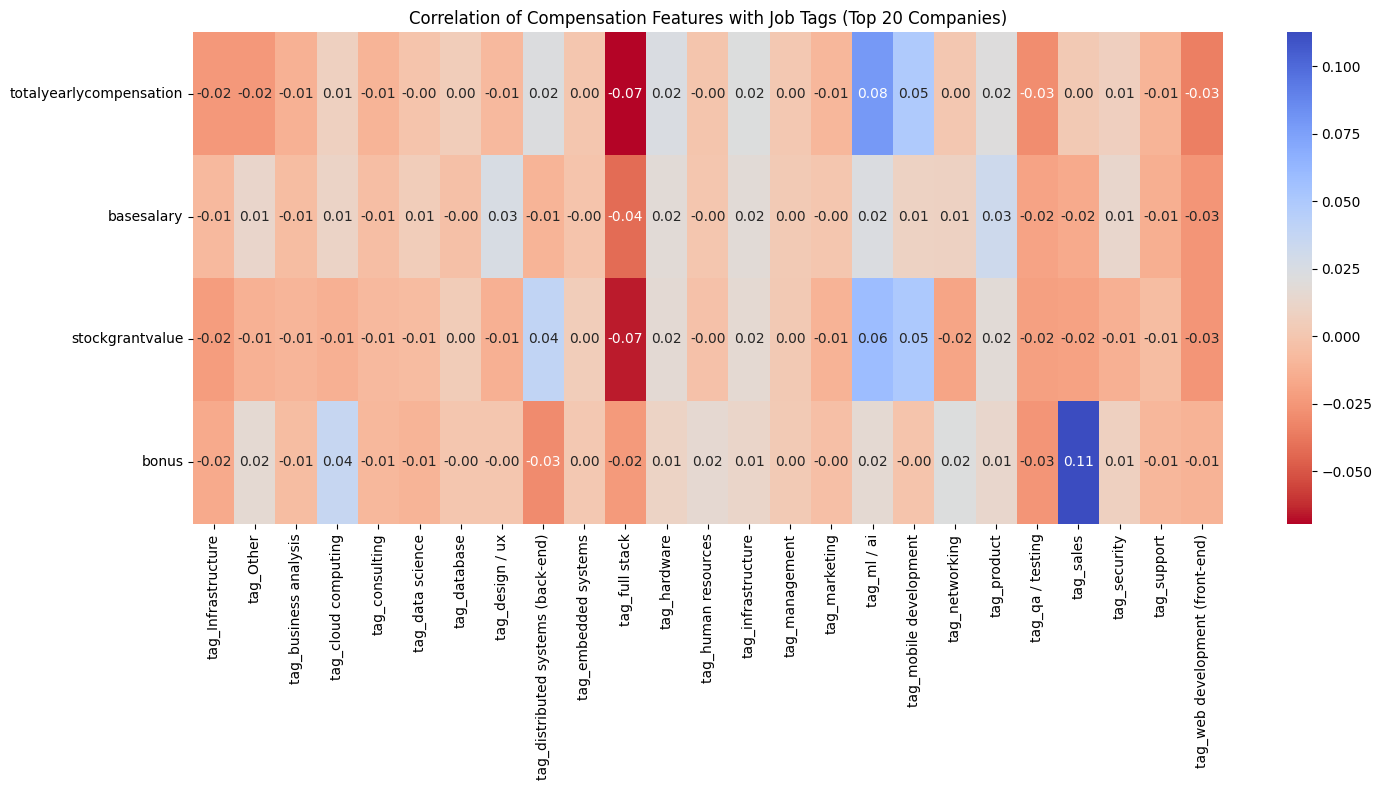

In [28]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Assuming tags_encoded contains the one-hot encoded tags and original compensation columns
# Assuming top_companies variable from a previous cell is available and contains the list of top company names.

# Filter dfc_encoded to include only rows from the top 20 companies
dfc_top_companies = tags_encoded[tags_encoded['company'].isin(top_companies)].copy()

# Identify the compensation features
compensation_features = ['totalyearlycompensation', 'basesalary', 'stockgrantvalue', 'bonus']

# Identify the one-hot encoded tag columns, excluding 'tag_Unknown Tag'
tag_columns_encoded = [col for col in dfc_top_companies.columns if col.startswith('tag_') and col != 'tag_Unknown Tag']

# Select the relevant columns from dfc_top_companies
columns_for_correlation = compensation_features + tag_columns_encoded

# Ensure all selected columns are in dfc_top_companies and are numeric types for correlation
numeric_columns_for_correlation = [col for col in columns_for_correlation if col in dfc_top_companies.columns and pd.api.types.is_numeric_dtype(dfc_top_companies[col])]

# Calculate the correlation matrix
correlation_matrix = dfc_top_companies[numeric_columns_for_correlation].corr()

# To focus on the correlation of compensation features with the new tag features,
# we can select the relevant part of the matrix.
correlation_with_tags = correlation_matrix.loc[compensation_features, tag_columns_encoded]

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(15, 8))
sns.heatmap(correlation_with_tags, annot=True, cmap='coolwarm_r', fmt=".2f") # annot=True to show coefficients
plt.title('Correlation of Compensation Features with Job Tags (Top 20 Companies)')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Assuming dfc_top_companies contains the filtered data for top companies with one-hot encoded tags

# Identify the features (one-hot encoded tags)
feature_cols = [col for col in dfc_top_companies.columns if col.startswith('tag_')]
X = dfc_top_companies[feature_cols]

# Identify the target variables (compensation components)
target_cols = ['totalyearlycompensation', 'basesalary', 'stockgrantvalue', 'bonus']
y = dfc_top_companies[target_cols]

# Split the data into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Create and train a Random Forest Regressor model
# We will train a separate model for each compensation component
regression_models = {}
predictions = {}
evaluation_metrics = {}

for target_col in target_cols:
    print(f"Training model for: {target_col}")
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1) # Using 100 estimators and all available cores
    model.fit(X_train, y_train[target_col])
    regression_models[target_col] = model

    # Make predictions on the test set
    y_pred = model.predict(X_test)
    predictions[target_col] = y_pred

    # Evaluate the model
    mae = mean_absolute_error(y_test[target_col], y_pred)
    rmse = np.sqrt(mean_squared_error(y_test[target_col], y_pred))

    evaluation_metrics[target_col] = {'MAE': mae, 'RMSE': rmse}

    print(f"  {target_col} - MAE: {mae:.2f}, RMSE: {rmse:.2f}")

print("\nTraining and evaluation complete.")

# Display the evaluation metrics
print("\nEvaluation Metrics:")
for target_col, metrics in evaluation_metrics.items():
    print(f"  {target_col}: MAE={metrics['MAE']:.2f}, RMSE={metrics['RMSE']:.2f}")

Training model for: totalyearlycompensation
  totalyearlycompensation - MAE: 68406.69, RMSE: 86418.43
Training model for: basesalary
  basesalary - MAE: 36111.33, RMSE: 49567.75
Training model for: stockgrantvalue
  stockgrantvalue - MAE: 39490.53, RMSE: 52978.02
Training model for: bonus
  bonus - MAE: 14274.80, RMSE: 20825.63

Training and evaluation complete.

Evaluation Metrics:
  totalyearlycompensation: MAE=68406.69, RMSE=86418.43
  basesalary: MAE=36111.33, RMSE=49567.75
  stockgrantvalue: MAE=39490.53, RMSE=52978.02
  bonus: MAE=14274.80, RMSE=20825.63


# Evaluating Employment

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd # Import pandas to use quantile

# Calculate the average years of experience and total yearly compensation
average_experience = dfc['yearsofexperience'].mean()
average_total_compensation = dfc['totalyearlycompensation'].mean()

# Print the initial results
print(f"Average years of experience: {average_experience:.2f}")
print(f"Average total yearly compensation: ${average_total_compensation:,.2f}")

# Filter data to include only observations with total yearly compensation below the 95th percentile
comp_threshold = dfc['totalyearlycompensation'].quantile(0.95)
dfc_filtered_comp = dfc[dfc['totalyearlycompensation'] <= comp_threshold].copy()

print(f"\nFiltering data: Using observations with Total Yearly Compensation below ${comp_threshold:,.0f} (95th percentile)")
print(f"Number of observations after filtering: {dfc_filtered_comp.shape[0]}")

# Define feature (X) and target (y) using the filtered data
X = dfc_filtered_comp[['yearsofexperience']].dropna() # Feature: Years of Experience, handle potential NaNs
y = dfc_filtered_comp['totalyearlycompensation'].loc[X.index].dropna() # Target: Total Yearly Compensation, align with X and handle NaNs

# Ensure there's data to train on after dropping NaNs
if not X.empty and not y.empty:
    # --- Linear Regression Model ---
    print("\nTraining Linear Regression model...")
    lr_model = LinearRegression()
    lr_model.fit(X, y)

    # The coefficient represents the estimated average linear increase in total yearly compensation per year of experience
    lr_experience_value = lr_model.coef_[0]

    # Make predictions on the training data to evaluate
    y_pred_lr = lr_model.predict(X)

    # Calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)
    mae_lr = mean_absolute_error(y, y_pred_lr)
    rmse_lr = np.sqrt(mean_squared_error(y, y_pred_lr))

    print(f"  Linear Regression - Estimated average linear increase per year: ${lr_experience_value:,.2f}")
    print(f"  Linear Regression - MAE: {mae_lr:,.2f}, RMSE: {rmse_lr:,.2f}")

    # --- Gradient Boosting Regressor Model ---
    print("\nTraining Gradient Boosting Regressor model...")
    gb_model = GradientBoostingRegressor(random_state=42)
    gb_model.fit(X, y)

    # Make predictions on the training data to evaluate
    y_pred_gb = gb_model.predict(X)

    # Calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)
    mae_gb = mean_absolute_error(y, y_pred_gb)
    rmse_gb = np.sqrt(mean_squared_error(y, y_pred_gb))

    # For tree-based models like Gradient Boosting and Random Forest, there isn't a single coefficient
    # representing the linear increase per year of experience. The relationship is non-linear.
    # We can't directly get an "estimated average increase" in the same way as linear regression.
    # However, we can approximate the rate of increase by looking at the change over a specific range of experience.
    # Let's estimate the average rate of increase between 5 and 10 years of experience.
    experience_range = np.array([[5], [10]])
    predicted_comp_gb = gb_model.predict(experience_range)
    # Calculate the average increase per year within this range
    gb_estimated_increase_per_year_in_range = (predicted_comp_gb[1] - predicted_comp_gb[0]) / (10 - 5)

    print(f"  Gradient Boosting - Estimated average increase per year (approximated over 5-10 yrs): ${gb_estimated_increase_per_year_in_range:,.2f}")
    print(f"  Gradient Boosting - MAE: {mae_gb:,.2f}, RMSE: {rmse_gb:,.2f}")


    # --- Random Forest Regressor Model ---
    print("\nTraining Random Forest Regressor model...")
    rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)
    rf_model.fit(X, y)

    # Make predictions on the training data to evaluate
    y_pred_rf = rf_model.predict(X)

    # Calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE)
    mae_rf = mean_absolute_error(y, y_pred_rf)
    rmse_rf = np.sqrt(mean_squared_error(y, y_pred_rf))

    # Estimate the average rate of increase between 5 and 10 years of experience for Random Forest
    predicted_comp_rf = rf_model.predict(experience_range)
    # Calculate the average increase per year within this range
    rf_estimated_increase_per_year_in_range = (predicted_comp_rf[1] - predicted_comp_rf[0]) / (10 - 5)


    print(f"  Random Forest - Estimated average increase per year (approximated over 5-10 yrs): ${rf_estimated_increase_per_year_in_range:,.2f}")
    print(f"  Random Forest - MAE: {mae_rf:,.2f}, RMSE: {rmse_rf:,.2f}")


    print("\nModel Comparison:")
    print(f"  Linear Regression - MAE: {mae_lr:,.2f}, RMSE: {rmse_lr:,.2f}")
    print(f"  Gradient Boosting - MAE: {mae_gb:,.2f}, RMSE: {rmse_gb:,.2f}")
    print(f"  Random Forest - MAE: {mae_rf:,.2f}, RMSE: {rmse_rf:,.2f}")

else:
    print("\nInsufficient data after handling missing values to perform regression on filtered data.")

Average years of experience: 7.20
Average total yearly compensation: $216,300.37

Filtering data: Using observations with Total Yearly Compensation below $457,950 (95th percentile)
Number of observations after filtering: 59509

Training Linear Regression model...
  Linear Regression - Estimated average linear increase per year: $6,303.61
  Linear Regression - MAE: 65,976.29, RMSE: 84,204.22

Training Gradient Boosting Regressor model...
  Gradient Boosting - Estimated average increase per year (approximated over 5-10 yrs): $7,014.88
  Gradient Boosting - MAE: 65,581.33, RMSE: 83,130.42

Training Random Forest Regressor model...
  Random Forest - Estimated average increase per year (approximated over 5-10 yrs): $7,040.74
  Random Forest - MAE: 65,579.72, RMSE: 83,125.07

Model Comparison:
  Linear Regression - MAE: 65,976.29, RMSE: 84,204.22
  Gradient Boosting - MAE: 65,581.33, RMSE: 83,130.42
  Random Forest - MAE: 65,579.72, RMSE: 83,125.07


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Assuming dfc is available and cleaned
# Assuming dfc_filtered_comp is available (filtered by 95th percentile totalyearlycompensation)

print("--- Predicting Total Yearly Compensation with Degree Levels ---")

# Define the degree columns to use as features
# We will use Masters_Degree and Doctorate_Degree as features, with Bachelors_Degree as the implicit baseline.
degree_features = ['Masters_Degree', 'Doctorate_Degree']
target = 'totalyearlycompensation'

# Filter the data to include the filtered compensation data (already done in dfc_filtered_comp)
# We also need to filter to include only rows where Bachelors_Degree is True, as this is our baseline.
# However, the interpretation should be that having a Masters or Doctorate implies having a Bachelors.
# So, we'll use the full filtered data and interpret coefficients relative to the 'Bachelors_Degree = 1, Masters_Degree = 0, Doctorate_Degree = 0' case.

# Define features (X) and target (y) using the relevant degree columns from the filtered data
# Use the one-hot encoded columns directly from dfc_filtered_comp
X = dfc_filtered_comp[degree_features].dropna() # Features: Masters and Doctorate indicators
y = dfc_filtered_comp[target].loc[X.index].dropna() # Target: Total Yearly Compensation, align with X and handle NaNs

# Ensure there's data to train on after dropping NaNs
if not X.empty and not y.empty:
    # Split data into training and testing sets for model evaluation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    print("\nTraining Linear Regression model...")
    # Train Linear Regression model
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    # The coefficients now represent the *additional* estimated increase in compensation
    # for having a Masters Degree (beyond a Bachelors) and a Doctorate Degree (beyond a Masters/Bachelors).

    print("\nLinear Regression Model Results (Baseline: Bachelor's Degree):")
    print(f"  Intercept (Estimated compensation for Bachelor's Degree): ${lr_model.intercept_:,.2f}")
    print(f"  Coefficient 'Masters_Degree': ${lr_model.coef_[degree_features.index('Masters_Degree')]:,.2f}")
    print(f"  Coefficient 'Doctorate_Degree': ${lr_model.coef_[degree_features.index('Doctorate_Degree')]:,.2f}")

    # Calculate estimated compensation for each degree level based on the progressive assumption
    estimated_comp_bachelors = lr_model.intercept_
    estimated_comp_masters = estimated_comp_bachelors + lr_model.coef_[degree_features.index('Masters_Degree')]
    estimated_comp_phd = estimated_comp_masters + lr_model.coef_[degree_features.index('Doctorate_Degree')] # Assuming PhD adds to Masters

    print("\nEstimated Compensation by Degree Level (Progressive):")
    print(f"  Bachelor's Degree: ${estimated_comp_bachelors:,.2f}")
    print(f"  Master's Degree: ${estimated_comp_masters:,.2f}")
    print(f"  Doctorate Degree: ${estimated_comp_phd:,.2f}")


    # Make predictions on the test data to evaluate Linear Regression
    y_pred_lr = lr_model.predict(X_test)

    # Calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) for Linear Regression
    mae_lr = mean_absolute_error(y_test, y_pred_lr)
    rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

    print(f"\nLinear Regression Evaluation - MAE: {mae_lr:,.2f}, RMSE: {rmse_lr:,.2f}")


    # --- Gradient Boosting Regressor Model ---
    print("\nTraining Gradient Boosting Regressor model...")
    gb_model = GradientBoostingRegressor(random_state=42)
    gb_model.fit(X_train, y_train)

    # Make predictions on the test data to evaluate Gradient Boosting
    y_pred_gb = gb_model.predict(X_test)

    # Calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) for Gradient Boosting
    mae_gb = mean_absolute_error(y_test, y_pred_gb)
    rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))

    print(f"Gradient Boosting Evaluation - MAE: {mae_gb:,.2f}, RMSE: {rmse_gb:,.2f}")


    # --- Random Forest Regressor Model ---
    print("\nTraining Random Forest Regressor model...")
    rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)
    rf_model.fit(X_train, y_train)

    # Make predictions on the test data to evaluate Random Forest
    y_pred_rf = rf_model.predict(X_test)

    # Calculate Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) for Random Forest
    mae_rf = mean_absolute_error(y_test, y_pred_rf)
    rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

    print(f"Random Forest Evaluation - MAE: {mae_rf:,.2f}, RMSE: {rmse_rf:,.2f}")


    print("\nModel Comparison (Evaluation on Test Set):")
    print(f"  Linear Regression - MAE: {mae_lr:,.2f}, RMSE: {rmse_lr:,.2f}")
    print(f"  Gradient Boosting - MAE: {mae_gb:,.2f}, RMSE: {rmse_gb:,.2f}")
    print(f"  Random Forest - MAE: {mae_rf:,.2f}, RMSE: {rmse_rf:,.2f}")


else:
    print("\nInsufficient data after filtering and handling missing values to perform regression.")

print("\nAnalysis complete.")

--- Predicting Total Yearly Compensation with Degree Levels ---

Training Linear Regression model...

Linear Regression Model Results (Baseline: Bachelor's Degree):
  Intercept (Estimated compensation for Bachelor's Degree): $191,293.16
  Coefficient 'Masters_Degree': $9,194.87
  Coefficient 'Doctorate_Degree': $58,049.84

Estimated Compensation by Degree Level (Progressive):
  Bachelor's Degree: $191,293.16
  Master's Degree: $200,488.03
  Doctorate Degree: $258,537.87

Linear Regression Evaluation - MAE: 71,232.42, RMSE: 90,296.15

Training Gradient Boosting Regressor model...
Gradient Boosting Evaluation - MAE: 71,232.66, RMSE: 90,296.33

Training Random Forest Regressor model...
Random Forest Evaluation - MAE: 71,238.05, RMSE: 90,296.46

Model Comparison (Evaluation on Test Set):
  Linear Regression - MAE: 71,232.42, RMSE: 90,296.15
  Gradient Boosting - MAE: 71,232.66, RMSE: 90,296.33
  Random Forest - MAE: 71,238.05, RMSE: 90,296.46

Analysis complete.


Distribution of Degree Levels (Percentages - Individual Counts):
Bachelor's Degree    20.122282
Master's Degree      24.569777
Doctorate Degree      2.878261
dtype: float64


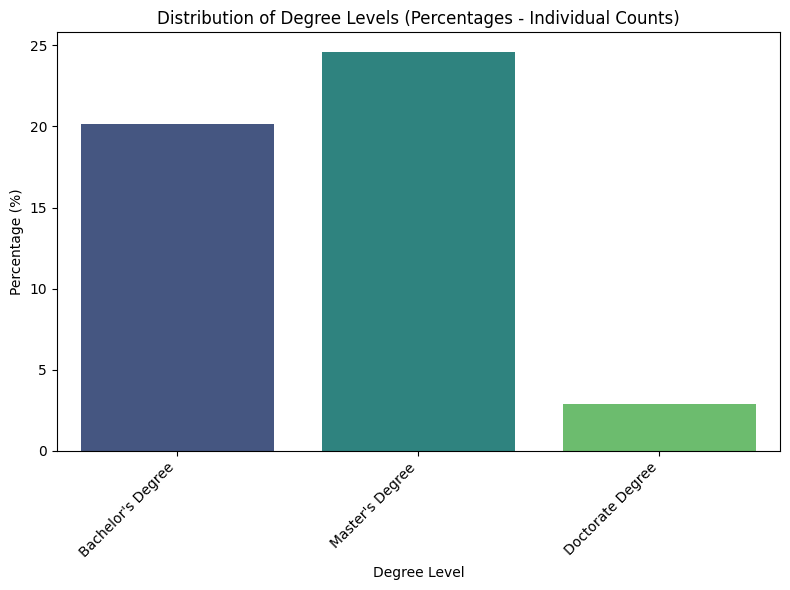


--- Distribution of Progressive Degree Levels (Pie Chart) ---


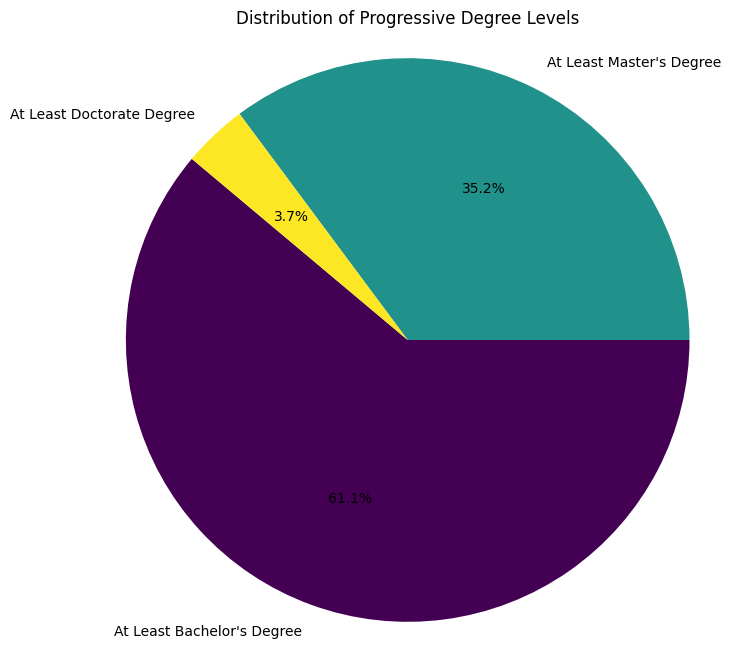


Counts for each progressive degree level:
At Least Bachelor's Degree    29695
At Least Master's Degree      17094
At Least Doctorate Degree      1803
dtype: int64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Import numpy for linspace

# Assuming dfc is available and cleaned

# Calculate the counts of each degree type being True
degree_counts_onehot = dfc[['Bachelors_Degree', 'Masters_Degree', 'Doctorate_Degree']].sum()

# Calculate percentages
total_observations = len(dfc)
degree_percentages = (degree_counts_onehot / total_observations) * 100

# Rename the index for better readability
degree_percentages.index = ['Bachelor\'s Degree', 'Master\'s Degree', 'Doctorate Degree']

print("Distribution of Degree Levels (Percentages - Individual Counts):")
print(degree_percentages)

# Visualize the distribution as a bar plot (showing individual counts)
plt.figure(figsize=(8, 6))
sns.barplot(x=degree_percentages.index, y=degree_percentages.values, palette='viridis')
plt.title('Distribution of Degree Levels (Percentages - Individual Counts)')
plt.xlabel('Degree Level')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# --- Add Pie Chart for Progressive Degree Level Distribution ---

print("\n--- Distribution of Progressive Degree Levels (Pie Chart) ---")

# Calculate the number of people with at least a Bachelor's, Master's, and Doctorate
# Based on the progressive assumption:
# At least Bachelor's: Anyone with Bachelors_Degree=True OR Masters_Degree=True OR Doctorate_Degree=True
# At least Master's: Anyone with Masters_Degree=True OR Doctorate_Degree=True
# At least Doctorate: Anyone with Doctorate_Degree=True

at_least_bachelors_count = dfc[(dfc['Bachelors_Degree'] == 1) | (dfc['Masters_Degree'] == 1) | (dfc['Doctorate_Degree'] == 1)].shape[0]
at_least_masters_count = dfc[(dfc['Masters_Degree'] == 1) | (dfc['Doctorate_Degree'] == 1)].shape[0]
at_least_doctorate_count = dfc[dfc['Doctorate_Degree'] == 1].shape[0]

# Create a Series for the pie chart data
progressive_degree_counts = pd.Series({
    'At Least Bachelor\'s Degree': at_least_bachelors_count,
    'At Least Master\'s Degree': at_least_masters_count,
    'At Least Doctorate Degree': at_least_doctorate_count
})

# Filter out categories with 0 counts if any (optional, but good practice for pie charts)
progressive_degree_counts = progressive_degree_counts[progressive_degree_counts > 0]


# Create a pie chart for progressive degrees
plt.figure(figsize=(8, 8))
plt.pie(progressive_degree_counts, labels=progressive_degree_counts.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.viridis(np.linspace(0, 1, len(progressive_degree_counts))))
plt.title('Distribution of Progressive Degree Levels')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

print("\nCounts for each progressive degree level:")
print(progressive_degree_counts)

# Note: A KDE plot is typically used for continuous data.
# For categorical data like degree levels, a bar plot is more appropriate to show distribution.
# However, if you intended to visualize the distribution of a continuous variable
# conditioned on degree level, please specify which variable.
# For now, I will add a comment explaining why KDE is not directly applicable here.

# If you meant to see the distribution of a continuous variable (e.g., compensation)
# for each degree level using KDE, you would use something like:
# plt.figure(figsize=(10, 6))
# sns.kdeplot(data=dfc, x='totalyearlycompensation', hue='Education', fill=True, palette='viridis')
# plt.title('Distribution of Total Yearly Compensation by Education Level (KDE)')
# plt.xlabel('Total Yearly Compensation')
# plt.ylabel('Density')
# plt.tight_layout()
# plt.show()

Creating lmplot for 5000 data points...


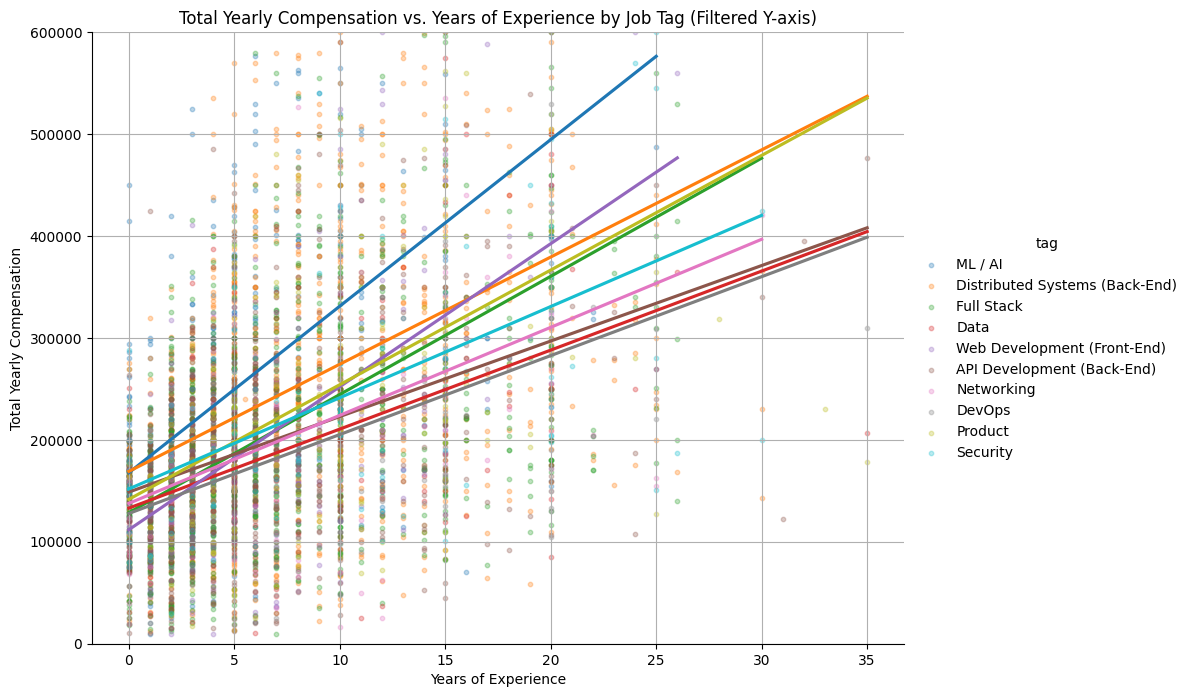

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc is available and cleaned

# Get the top 10 most frequent tags (excluding 'Unknown Tag' if it exists)
top_tags = dfc[dfc['tag'] != 'Unknown Tag']['tag'].value_counts().nlargest(10).index.tolist()

# Filter the dataframe to include only data for these top tags
df_top_tags = dfc[dfc['tag'].isin(top_tags)].copy()

# Create an lmplot to visualize the relationship between totalyearlycompensation and yearsofexperience
# for each of the top tags.
# Use a subset of the data for lmplot for potentially faster rendering and clearer visualization.
# Let's sample the data if it's too large.
if len(df_top_tags) > 5000: # Arbitrary threshold for sampling
    df_plot_sample = df_top_tags.sample(n=5000, random_state=42).copy()
else:
    df_plot_sample = df_top_tags.copy()

# Ensure the relevant columns are numeric
df_plot_sample['totalyearlycompensation'] = pd.to_numeric(df_plot_sample['totalyearlycompensation'], errors='coerce')
df_plot_sample['yearsofexperience'] = pd.to_numeric(df_plot_sample['yearsofexperience'], errors='coerce')

# Drop rows with NaN in the columns used for plotting
df_plot_sample.dropna(subset=['totalyearlycompensation', 'yearsofexperience', 'tag'], inplace=True)


print(f"Creating lmplot for {len(df_plot_sample)} data points...")

# Create the lmplot
g = sns.lmplot(data=df_plot_sample,
           x='yearsofexperience',
           y='totalyearlycompensation',
           hue='tag',
           height=7, aspect=1.3, ci=None, scatter_kws={'alpha': 0.3, 's': 10})

# Set the y-axis limit for better resolution
g.set(ylim=(0, 600000))


plt.title('Total Yearly Compensation vs. Years of Experience by Job Tag (Filtered Y-axis)')
plt.xlabel('Years of Experience')
plt.ylabel('Total Yearly Compensation')
plt.grid(True)
plt.show()

In [32]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Assuming dfc is available and cleaned

print("--- Comparing Regression Models for Total Compensation Prediction vs. Years of Experience by Education and Tag (Top 20 Companies, Total Comp <= $500k) ---")

# Define the education levels and tags to analyze
education_levels = ['bachelor\'s degree', 'master\'s degree', 'phd']
tags_to_analyze = ['ml / ai', 'distributed systems (back-end)', 'mobile development']

# Dictionary to store evaluation results for each category and model
evaluation_results = {}

# --- Filter data for Top 20 Companies and Total Compensation <= $500k ---
# Assuming top_companies variable is available from previous cells.
# If not, you might need to add code here to define it, e.g.:
# company_counts = dfc['company'].value_counts()
# top_companies = company_counts.nlargest(20).index.tolist()

# Filter dfc to include only the top 20 companies
try:
    # Ensure top_companies is available
    company_counts = dfc['company'].value_counts()
    top_companies = company_counts.nlargest(20).index.tolist()
    dfc_top_companies = dfc[dfc['company'].isin(top_companies)].copy()
    print(f"\n✅ Filtered data for Top 20 Companies. Remaining observations: {dfc_top_companies.shape[0]}")
except NameError:
    print("\n❌ ERROR: The 'top_companies' variable is not defined. Please ensure the code to identify top companies has been run.")
    exit()

# Filter out total yearly compensation above $500k
dfc_filtered_comp = dfc_top_companies[dfc_top_companies['totalyearlycompensation'] <= 500000].copy()
print(f"✅ Further filtered data to exclude total yearly compensation > $500k. Remaining observations: {dfc_filtered_comp.shape[0]}")


# Analyze by Education Level (using the filtered data)
print("\n--- Analyzing by Education Level ---")
for edu_level in education_levels:
    print(f"\nAnalyzing Education Level: '{edu_level.capitalize()}'")

    # Filter data for the current education level from the filtered data
    # Ensure comparison is case-insensitive and strip whitespace for robust matching
    edu_filtered_df = dfc_filtered_comp[dfc_filtered_comp['Education'].str.lower().str.strip() == edu_level.lower()].copy()

    if edu_filtered_df.shape[0] < 2:
        print(f"  Insufficient data ({edu_filtered_df.shape[0]} observations) for education level '{edu_level.capitalize()}' to train models.")
        continue

    # Define feature (X) and target (y) - using 'yearsofexperience'
    X = edu_filtered_df[['yearsofexperience']].dropna()
    y = edu_filtered_df['totalyearlycompensation'].loc[X.index].dropna() # Align y with X

    if X.empty or y.empty:
        print(f"  No valid data points after dropping NaNs for education level '{edu_level.capitalize()}'.")
        continue


    # --- Train and Evaluate Models ---

    # 1. Linear Regression Model
    print("  Training Linear Regression model...")
    lr_model = LinearRegression()
    lr_model.fit(X, y)
    y_pred_lr = lr_model.predict(X) # Predict on training data for evaluation here
    mae_lr = mean_absolute_error(y, y_pred_lr)
    rmse_lr = np.sqrt(mean_squared_error(y, y_pred_lr))
    print(f"    Linear Regression - MAE: {mae_lr:,.2f}, RMSE: {rmse_lr:,.2f}")
    evaluation_results[f'{edu_level}_lr'] = {'MAE': mae_lr, 'RMSE': rmse_lr}


    # 2. Gradient Boosting Regressor Model
    print("  Training Gradient Boosting Regressor model...")
    gb_model = GradientBoostingRegressor(random_state=42)
    gb_model.fit(X, y)
    y_pred_gb = gb_model.predict(X)
    mae_gb = mean_absolute_error(y, y_pred_gb)
    rmse_gb = np.sqrt(mean_squared_error(y, y_pred_gb))
    print(f"    Gradient Boosting - MAE: {mae_gb:,.2f}, RMSE: {rmse_gb:,.2f}")
    evaluation_results[f'{edu_level}_gb'] = {'MAE': mae_gb, 'RMSE': rmse_gb}


    # 3. Random Forest Regressor Model
    print("  Training Random Forest Regressor model...")
    rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)
    rf_model.fit(X, y)
    y_pred_rf = rf_model.predict(X)
    mae_rf = mean_absolute_error(y, y_pred_rf)
    rmse_rf = np.sqrt(mean_squared_error(y, y_pred_rf))
    print(f"    Random Forest - MAE: {mae_rf:,.2f}, RMSE: {rmse_rf:,.2f}")
    evaluation_results[f'{edu_level}_rf'] = {'MAE': mae_rf, 'RMSE': rmse_rf}


# Analyze by Job Tag (using the filtered data)
print("\n--- Analyzing by Job Tag ---")
for tag in tags_to_analyze:
    print(f"\nAnalyzing Job Tag: '{tag.capitalize()}'")

    # Filter data for the current tag from the filtered data
    # Ensure comparison is case-insensitive and strip whitespace for robust matching
    tag_filtered_df = dfc_filtered_comp[dfc_filtered_comp['tag'].str.lower().str.strip() == tag.lower()].copy()

    if tag_filtered_df.shape[0] < 2:
         print(f"  Insufficient data ({tag_filtered_df.shape[0]} observations) for tag '{tag.capitalize()}' to train models.")
         continue

    # Define feature (X) and target (y) - using 'yearsofexperience'
    X = tag_filtered_df[['yearsofexperience']].dropna()
    y = tag_filtered_df['totalyearlycompensation'].loc[X.index].dropna() # Align y with X

    if X.empty or y.empty:
        print(f"  No valid data points after dropping NaNs for tag '{tag.capitalize()}'.")
        continue

    # --- Train and Evaluate Models ---

    # 1. Linear Regression Model
    print("  Training Linear Regression model...")
    lr_model = LinearRegression()
    lr_model.fit(X, y)
    y_pred_lr = lr_model.predict(X)
    mae_lr = mean_absolute_error(y, y_pred_lr)
    rmse_lr = np.sqrt(mean_squared_error(y, y_pred_lr))
    print(f"    Linear Regression - MAE: {mae_lr:,.2f}, RMSE: {rmse_lr:,.2f}")
    evaluation_results[f'{tag}_lr'] = {'MAE': mae_lr, 'RMSE': rmse_lr}


    # 2. Gradient Boosting Regressor Model
    print("  Training Gradient Boosting Regressor model...")
    gb_model = GradientBoostingRegressor(random_state=42)
    gb_model.fit(X, y)
    y_pred_gb = gb_model.predict(X)
    mae_gb = mean_absolute_error(y, y_pred_gb)
    rmse_gb = np.sqrt(mean_squared_error(y, y_pred_gb))
    print(f"    Gradient Boosting - MAE: {mae_gb:,.2f}, RMSE: {rmse_gb:,.2f}")
    evaluation_results[f'{tag}_gb'] = {'MAE': mae_gb, 'RMSE': rmse_gb}


    # 3. Random Forest Regressor Model
    print("  Training Random Forest Regressor model...")
    rf_model = RandomForestRegressor(random_state=42, n_jobs=-1)
    rf_model.fit(X, y)
    y_pred_rf = rf_model.predict(X)
    mae_rf = mean_absolute_error(y, y_pred_rf)
    rmse_rf = np.sqrt(mean_squared_error(y, y_pred_rf))
    print(f"    Random Forest - MAE: {mae_rf:,.2f}, RMSE: {rmse_rf:,.2f}")
    evaluation_results[f'{tag}_rf'] = {'MAE': mae_rf, 'RMSE': rmse_rf}


# Display Summary of Evaluation Results
print("\n--- Summary of Regression Model Evaluation Results (MAE and RMSE) ---")

# Convert the results dictionary to a DataFrame for better display
summary_list = []
for key, metrics in evaluation_results.items():
    category, model_type = key.rsplit('_', 1)
    summary_list.append({
        'Category': category.capitalize(),
        'Model': model_type.upper(),
        'MAE': metrics['MAE'],
        'RMSE': metrics['RMSE']
    })

summary_df = pd.DataFrame(summary_list)

# Pivot the table to show MAE and RMSE side-by-side for each category and model
summary_mae_pivot = summary_df.pivot_table(index='Category', columns='Model', values='MAE')
summary_rmse_pivot = summary_df.pivot_table(index='Category', columns='Model', values='RMSE')

print("\nMean Absolute Error (MAE) Comparison:")
display(summary_mae_pivot.style.format("{:,.2f}"))

print("\nRoot Mean Squared Error (RMSE) Comparison:")
display(summary_rmse_pivot.style.format("{:,.2f}"))

print("\nAnalysis complete.")

--- Comparing Regression Models for Total Compensation Prediction vs. Years of Experience by Education and Tag (Top 20 Companies, Total Comp <= $500k) ---

✅ Filtered data for Top 20 Companies. Remaining observations: 33640
✅ Further filtered data to exclude total yearly compensation > $500k. Remaining observations: 32204

--- Analyzing by Education Level ---

Analyzing Education Level: 'Bachelor's degree'
  Training Linear Regression model...
    Linear Regression - MAE: 65,817.05, RMSE: 85,190.84
  Training Gradient Boosting Regressor model...
    Gradient Boosting - MAE: 65,400.98, RMSE: 83,782.61
  Training Random Forest Regressor model...
    Random Forest - MAE: 65,422.60, RMSE: 83,786.38

Analyzing Education Level: 'Master's degree'
  Training Linear Regression model...
    Linear Regression - MAE: 62,148.15, RMSE: 81,551.95
  Training Gradient Boosting Regressor model...
    Gradient Boosting - MAE: 61,378.82, RMSE: 80,244.02
  Training Random Forest Regressor model...
    Rand

Model,GB,LR,RF
Category,,,
Bachelor's degree,"65,400.98","65,817.05","65,422.60"
Distributed systems (back-end),"65,104.91","66,826.88","65,119.47"
Master's degree,"61,378.82","62,148.15","61,416.39"
Ml / ai,"65,961.14","67,464.12","65,992.33"
Phd,"64,257.70","66,231.85","64,328.44"



Root Mean Squared Error (RMSE) Comparison:


Model,GB,LR,RF
Category,,,
Bachelor's degree,"83,782.61","85,190.84","83,786.38"
Distributed systems (back-end),"85,350.55","87,335.15","85,350.18"
Master's degree,"80,244.02","81,551.95","80,248.27"
Ml / ai,"83,588.51","86,036.96","83,604.26"
Phd,"80,441.59","82,943.82","80,477.14"



Analysis complete.


--- Visualizing Total Compensation vs. Years of Experience by Education and Tag ---
Creating lmplot for 44737 data points...


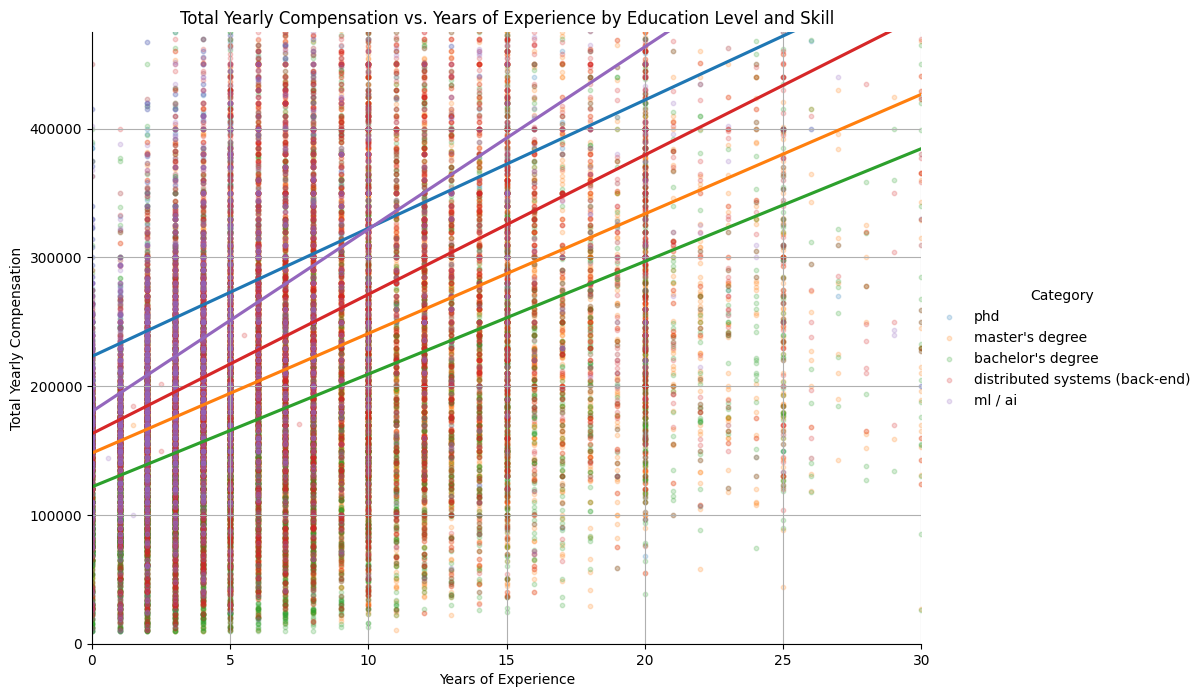


Analysis complete.


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc is available and cleaned

print("--- Visualizing Total Compensation vs. Years of Experience by Education and Tag ---")

# Define the education levels and tags to visualize
education_levels_to_plot = ['bachelor\'s degree', 'master\'s degree', 'phd']
tags_to_plot = ['ml / ai', 'distributed systems (back-end)', 'mobile development']

# Filter the data to include only the specified education levels and tags
# We need to filter for each category separately and then combine the data for plotting

# Filter for education levels
education_filtered_df = dfc[dfc['Education'].str.lower().str.strip().isin(education_levels_to_plot)].copy()
education_filtered_df['Category_Type'] = 'Education' # Add a column to identify the category type
education_filtered_df['Category'] = education_filtered_df['Education'].str.lower().str.strip() # Use the education level as the category name

# Filter for tags
tag_filtered_df = dfc[dfc['tag'].str.lower().str.strip().isin(tags_to_plot)].copy()
tag_filtered_df['Category_Type'] = 'Tag' # Add a column to identify the category type
tag_filtered_df['Category'] = tag_filtered_df['tag'].str.lower().str.strip() # Use the tag as the category name

# Combine the filtered dataframes
# Ensure consistent columns before concatenating
# Select a common subset of columns needed for plotting and identification
common_cols = ['yearsofexperience', 'totalyearlycompensation', 'Category_Type', 'Category']
combined_plot_df = pd.concat([education_filtered_df[common_cols], tag_filtered_df[common_cols]], ignore_index=True)


# Ensure the relevant columns are numeric
combined_plot_df['totalyearlycompensation'] = pd.to_numeric(combined_plot_df['totalyearlycompensation'], errors='coerce')
combined_plot_df['yearsofexperience'] = pd.to_numeric(combined_plot_df['yearsofexperience'], errors='coerce')

# Drop rows with NaN in the columns used for plotting
combined_plot_df.dropna(subset=['totalyearlycompensation', 'yearsofexperience', 'Category'], inplace=True)


print(f"Creating lmplot for {len(combined_plot_df)} data points...")

# Create the lmplot
g = sns.lmplot(data=combined_plot_df,
               x='yearsofexperience',
               y='totalyearlycompensation',
               hue='Category', # Use the combined Category column for hue
               height=7, aspect=1.3, ci=None, scatter_kws={'alpha': 0.2, 's': 10})

# Set the y-axis limit for better resolution (adjust as needed)
g.set(ylim=(0, combined_plot_df['totalyearlycompensation'].quantile(0.95))) # Set y-limit to 95th percentile

plt.title('Total Yearly Compensation vs. Years of Experience by Education Level and Skill')
plt.xlabel('Years of Experience')
plt.ylabel('Total Yearly Compensation')
plt.grid(True)
plt.xlim (0, 30)
plt.show()

print("\nAnalysis complete.")

# Evaluating Retention


In [ ]:
# Compute descriptive statistics for years spent at a company
average_years_at_company = dfc['yearsatcompany'].mean()
max_years_at_company = dfc['yearsatcompany'].max()
min_years_at_company = dfc['yearsatcompany'].min()
std_years_at_company = dfc['yearsatcompany'].std()


# Print the results
print(f"Average years spent at a company: {average_years_at_company:.2f}")
print(f"Maximum years spent at a company: {max_years_at_company:.2f}")
print(f"Minimum years spent at a company: {min_years_at_company:.2f}")
print(f"Standard deviation of years spent at a company: {std_years_at_company:.2f}")

Average years spent at a company: 2.70
Maximum years spent at a company: 69.00
Minimum years spent at a company: 0.00
Standard deviation of years spent at a company: 3.26


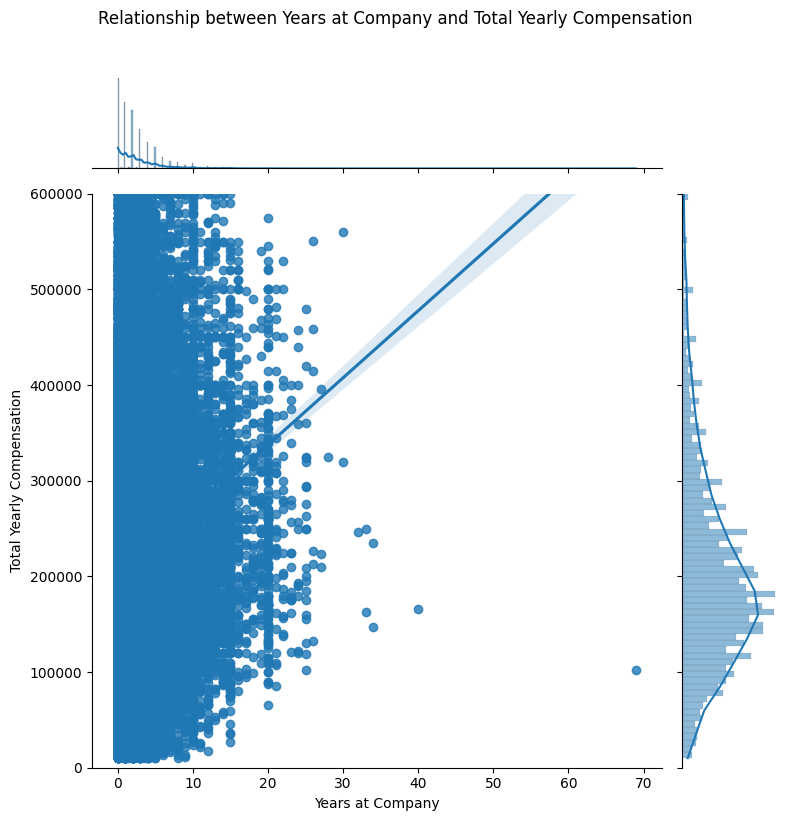

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a joint plot for years at company and total yearly compensation
g = sns.jointplot(data=dfc, x='yearsatcompany', y='totalyearlycompensation', kind='reg', height=8) # Changed kind to 'reg'

# Set y-axis limit for the scatter plot within the jointplot
g.ax_joint.set_ylim(0, 600000)

# Add titles and labels
g.fig.suptitle('Relationship between Years at Company and Total Yearly Compensation', y=1.02) # Add title to the figure
g.set_axis_labels('Years at Company', 'Total Yearly Compensation')

plt.tight_layout()
plt.show()

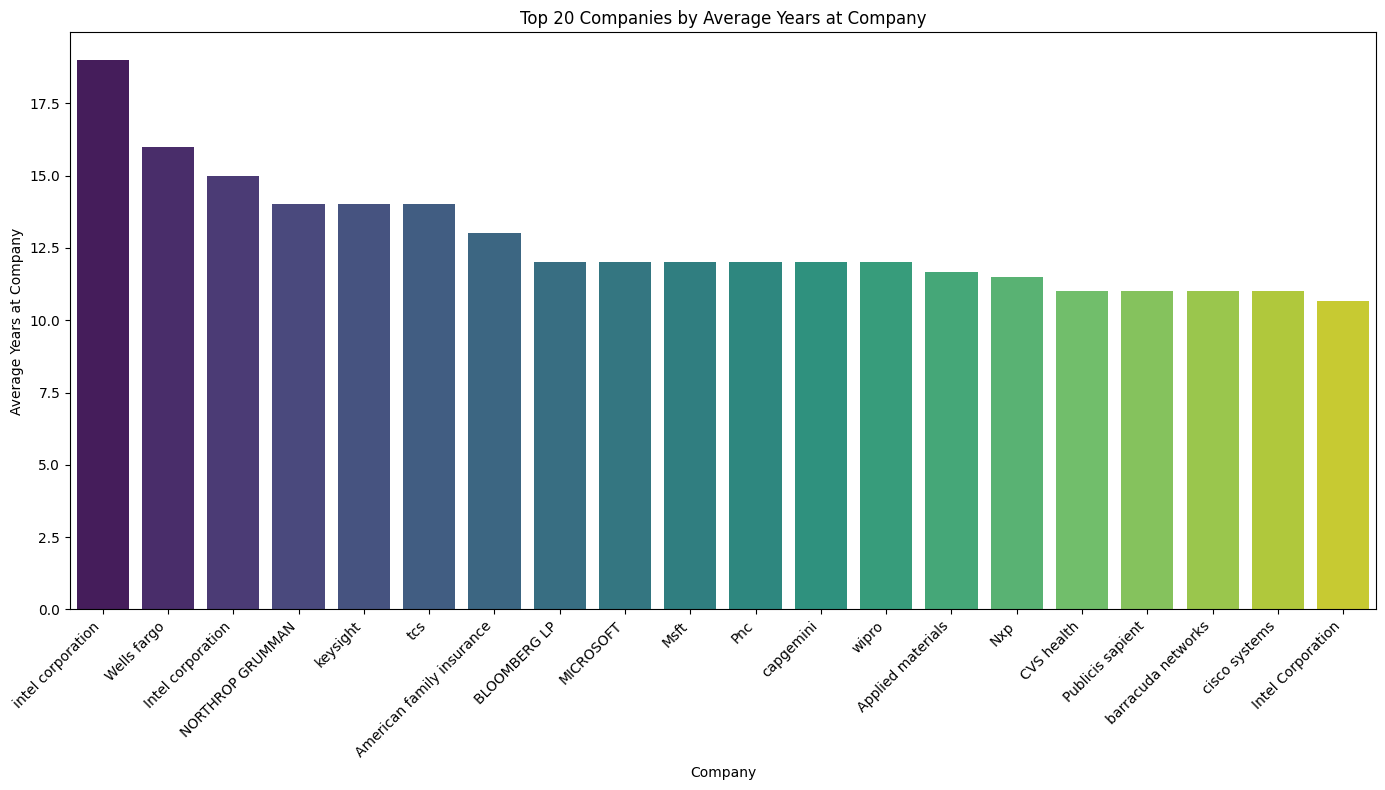

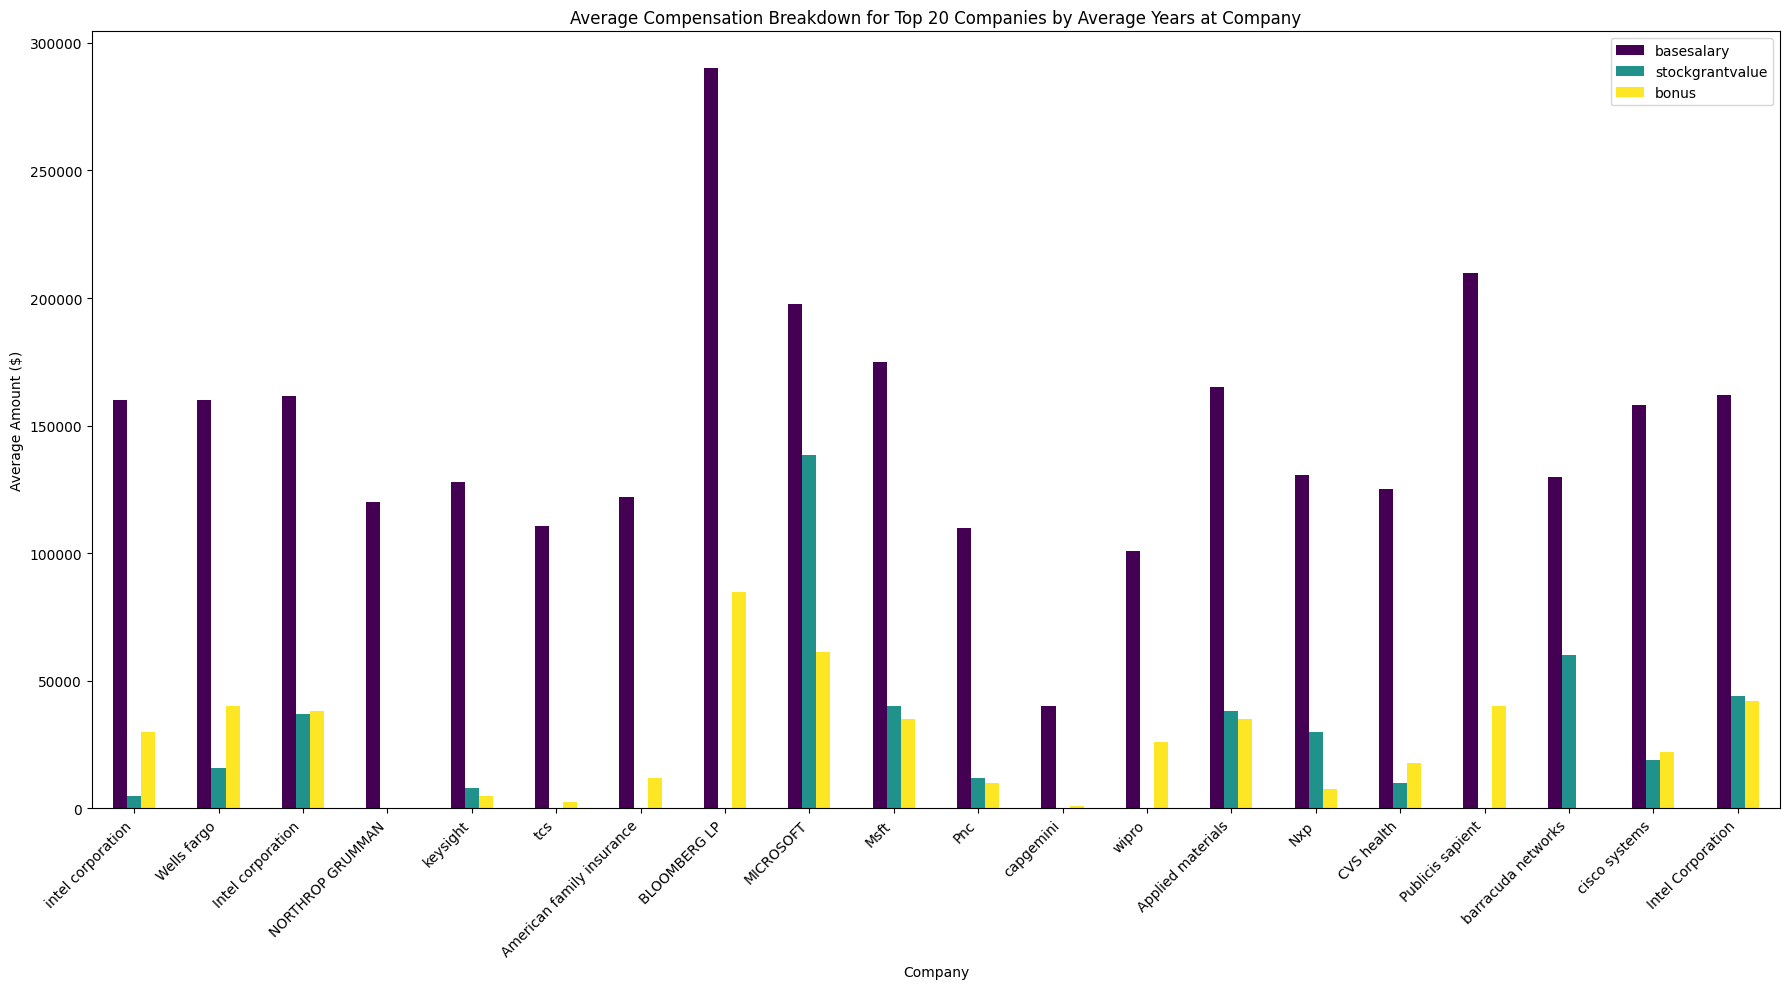

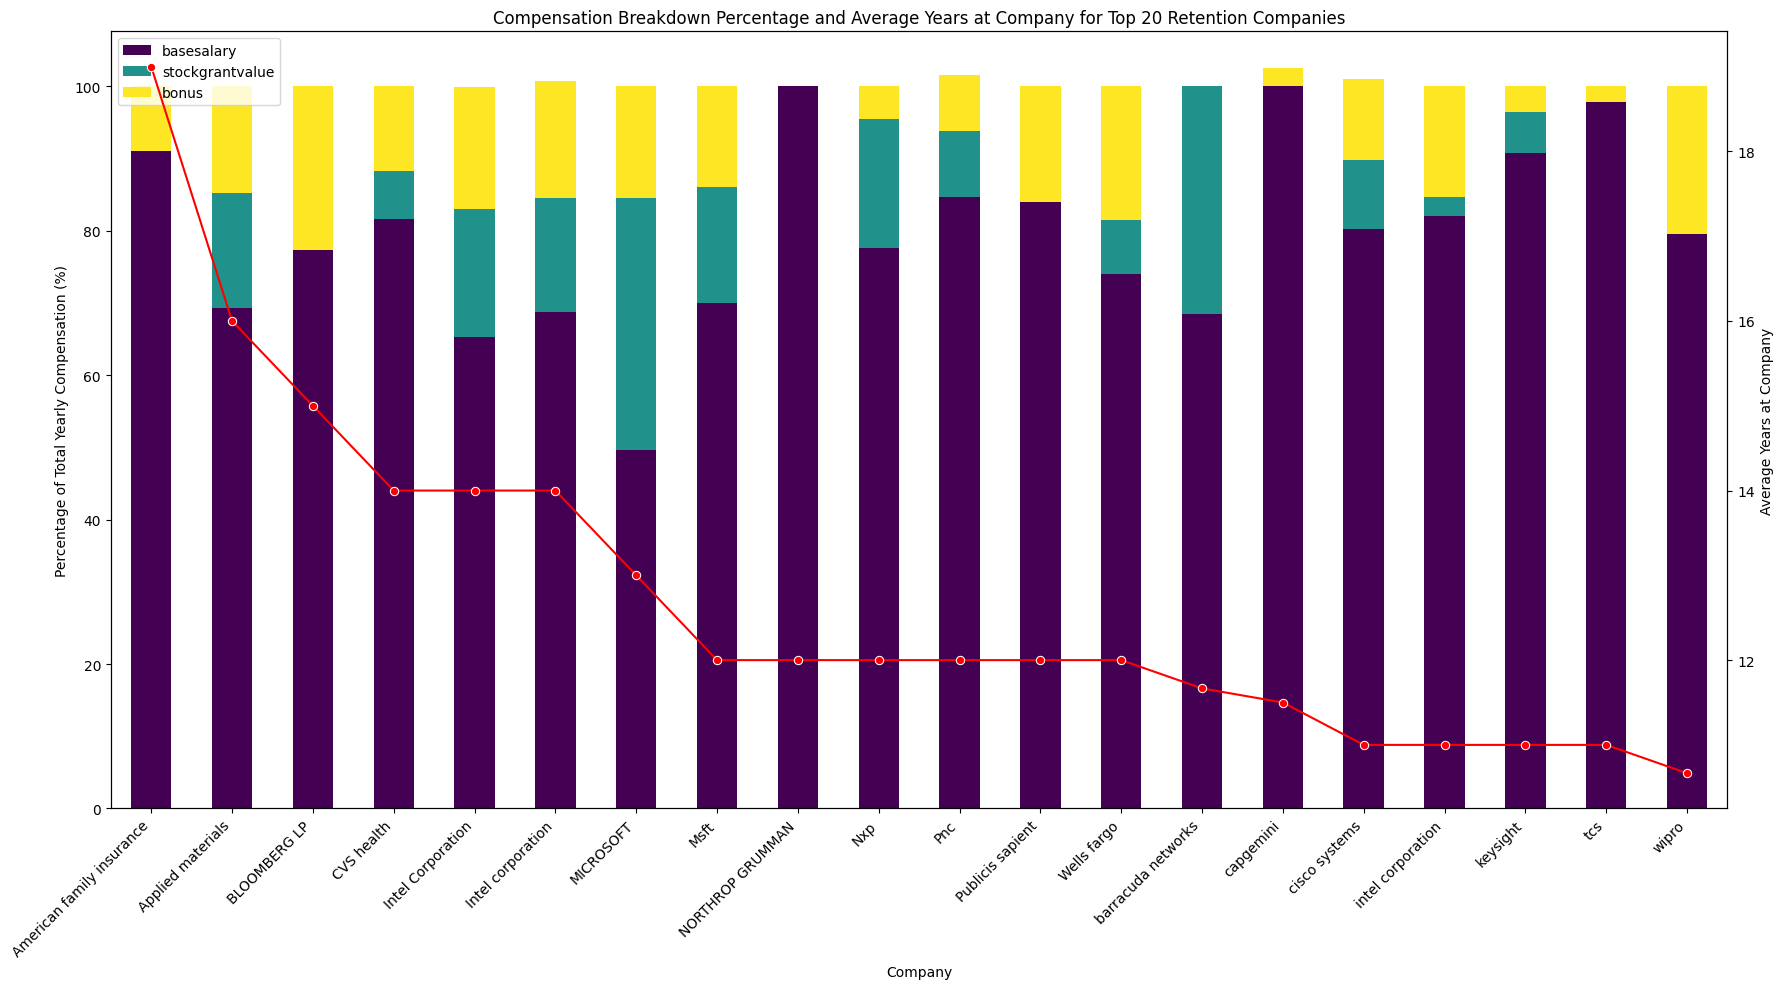

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Calculate the average years at company for each company
average_years_by_company = dfc.groupby('company')['yearsatcompany'].mean()

# Get the top 20 companies with the highest average years at company
top_20_companies_retention = average_years_by_company.nlargest(20)

# Create a bar plot to visualize the top 20 companies by average years at company
plt.figure(figsize=(14, 8)) # Increased figure size for better readability of x-axis labels
sns.barplot(x=top_20_companies_retention.index, y=top_20_companies_retention.values, palette='viridis') # Swapped x and y
plt.title('Top 20 Companies by Average Years at Company')
plt.xlabel('Company') # Changed xlabel
plt.ylabel('Average Years at Company') # Changed ylabel
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for readability
plt.tight_layout()
plt.show()

# Filter the original dataframe to include only the top 20 companies by retention
dfc_top_retention_companies = dfc[dfc['company'].isin(top_20_companies_retention.index)].copy()

# Calculate the average compensation components for these top companies
average_comp_breakdown = dfc_top_retention_companies.groupby('company')[['basesalary', 'stockgrantvalue', 'bonus']].mean()

# Sort the breakdown data to match the order of the retention plot (optional, but good for comparison)
average_comp_breakdown = average_comp_breakdown.reindex(top_20_companies_retention.index)


# Visualize the average compensation breakdown using grouped bar plots
average_comp_breakdown.plot(kind='bar', figsize=(18, 10), colormap='viridis')
plt.title('Average Compensation Breakdown for Top 20 Companies by Average Years at Company')
plt.xlabel('Company')
plt.ylabel('Average Amount ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# To show percentages, we first need to calculate the average total compensation for these companies
average_total_comp = dfc_top_retention_companies.groupby('company')['totalyearlycompensation'].mean()

# Calculate the percentage breakdown
percentage_comp_breakdown = average_comp_breakdown.divide(average_total_comp, axis=0) * 100

# Visualize the percentage breakdown using stacked bar plots
# percentage_comp_breakdown.plot(kind='bar', stacked=True, figsize=(18, 10), colormap='viridis')
# plt.title('Percentage Compensation Breakdown for Top 20 Companies by Average Years at Company')
# plt.xlabel('Company')
# plt.ylabel('Percentage of Total Yearly Compensation (%)')
# plt.xticks(rotation=45, ha='right')
# plt.legend(title='Compensation Component', bbox_to_anchor=(1.05, 1), loc='upper left')
# plt.tight_layout()
# plt.show()

# Create a combined plot with two y-axes to show percentage compensation breakdown and average years at company
fig, ax1 = plt.subplots(figsize=(18, 10))

# Plot the stacked percentage breakdown on the first y-axis
percentage_comp_breakdown.plot(kind='bar', stacked=True, ax=ax1, colormap='viridis')
ax1.set_xlabel('Company')
ax1.set_ylabel('Percentage of Total Yearly Compensation (%)')
ax1.tick_params(axis='y')
ax1.set_xticklabels(percentage_comp_breakdown.index, rotation=45, ha='right')

# Create a second y-axis for the average years at company
ax2 = ax1.twinx()
# Use the top_20_companies_retention series which is already sorted and contains the average years
sns.lineplot(x=top_20_companies_retention.index, y=top_20_companies_retention.values, ax=ax2, color='red', marker='o') # Plotting average years
ax2.set_ylabel('Average Years at Company')
ax2.tick_params(axis='y')

plt.title('Compensation Breakdown Percentage and Average Years at Company for Top 20 Retention Companies')
fig.tight_layout() # Adjust layout to prevent labels overlapping
plt.show()

Creating lmplot for Years at Company vs. basesalary...


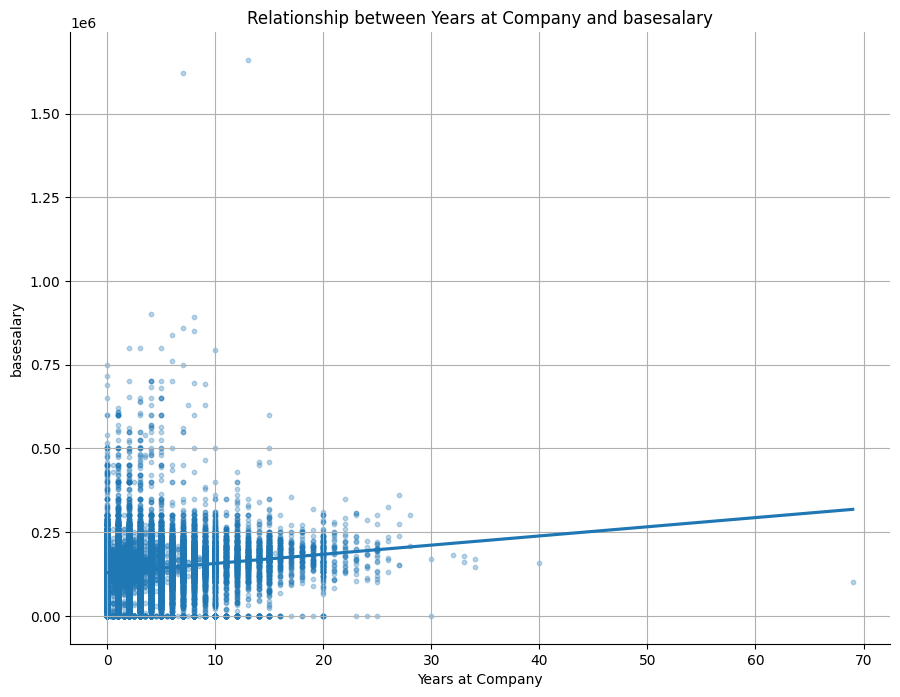

Creating lmplot for Years at Company vs. stockgrantvalue...


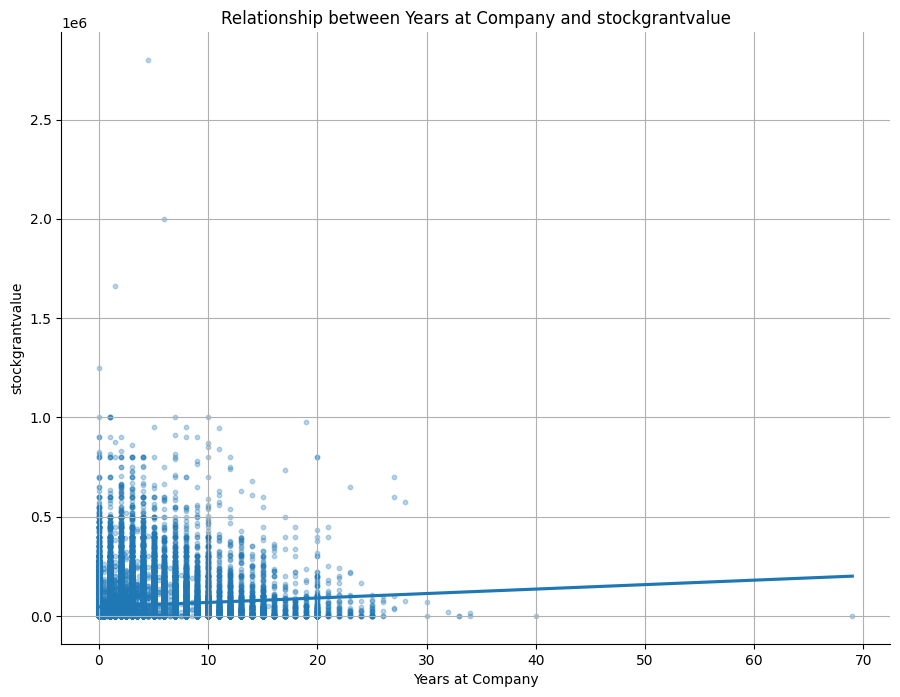

Creating lmplot for Years at Company vs. bonus...


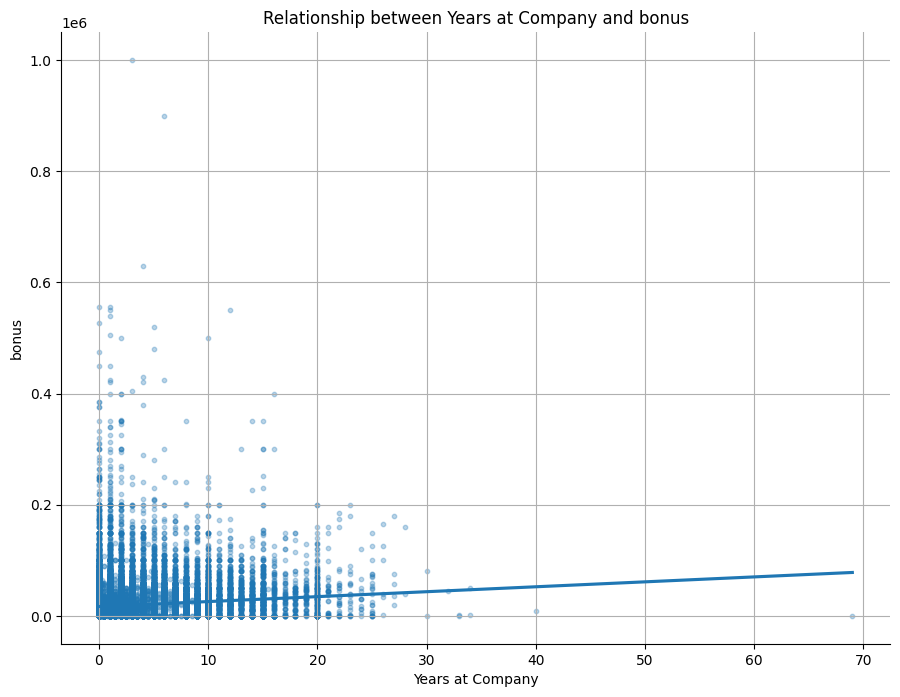

Creating lmplot for Years at Company vs. Total Yearly Compensation...


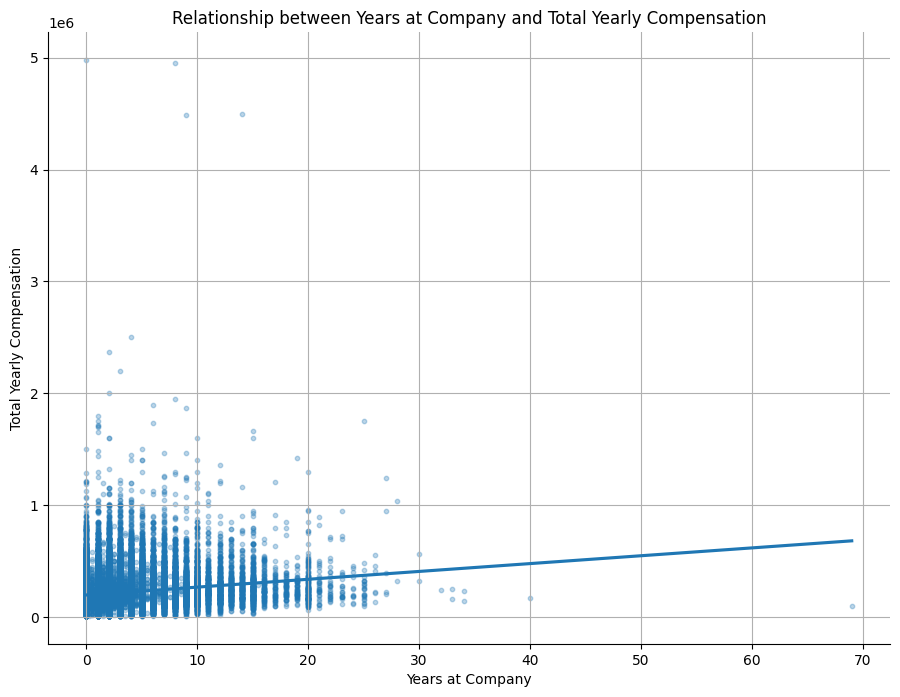

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc is available and cleaned

# List of compensation components to visualize
compensation_components = ['basesalary', 'stockgrantvalue', 'bonus']

# Create an lmplot for yearsatcompany vs. each compensation component
for comp in compensation_components:
    print(f"Creating lmplot for Years at Company vs. {comp}...")
    g = sns.lmplot(data=dfc,
                   x='yearsatcompany',
                   y=comp,
                   height=7, aspect=1.3, ci=None, scatter_kws={'alpha': 0.3, 's': 10})
    plt.title(f'Relationship between Years at Company and {comp}')
    plt.xlabel('Years at Company')
    plt.ylabel(comp)
    plt.grid(True)
    plt.show()

# Optionally, create an lmplot for totalyearlycompensation as well
print("Creating lmplot for Years at Company vs. Total Yearly Compensation...")
g = sns.lmplot(data=dfc,
               x='yearsatcompany',
               y='totalyearlycompensation',
               height=7, aspect=1.3, ci=None, scatter_kws={'alpha': 0.3, 's': 10})
plt.title('Relationship between Years at Company and Total Yearly Compensation')
plt.xlabel('Years at Company')
plt.ylabel('Total Yearly Compensation')
plt.grid(True)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Assuming dfc is available and cleaned

# Define features (X) and target variable (y)
features = ['basesalary', 'stockgrantvalue', 'bonus']
target = 'yearsatcompany'

X = dfc[features]
y = dfc[target]

# Split the data into training and testing sets (e.g., 70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Create and train a Random Forest Regressor model
print(f"Training Random Forest model to predict {target}...")
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1) # Using 100 estimators and all available cores
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
print(f"  Random Forest - MAE: {mae_rf:.2f}, RMSE: {rmse_rf:.2f}")

# Create and train a Gradient Boosting Regressor model
print(f"\nTraining Gradient Boosting model to predict {target}...")
gb_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb = gb_model.predict(X_test)
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
print(f"  Gradient Boosting - MAE: {mae_gb:.2f}, RMSE: {rmse_gb:.2f}")


print("\nTraining and evaluation complete.")

# Compare the results
print("\nModel Comparison:")
print(f"  Random Forest - MAE: {mae_rf:.2f}, RMSE: {rmse_rf:.2f}")
print(f"  Gradient Boosting - MAE: {mae_gb:.2f}, RMSE: {rmse_gb:.2f}")

Training Random Forest model to predict yearsatcompany...
  Random Forest - MAE: 2.15, RMSE: 3.18

Training Gradient Boosting model to predict yearsatcompany...
  Gradient Boosting - MAE: 2.09, RMSE: 3.03

Training and evaluation complete.

Model Comparison:
  Random Forest - MAE: 2.15, RMSE: 3.18
  Gradient Boosting - MAE: 2.09, RMSE: 3.03


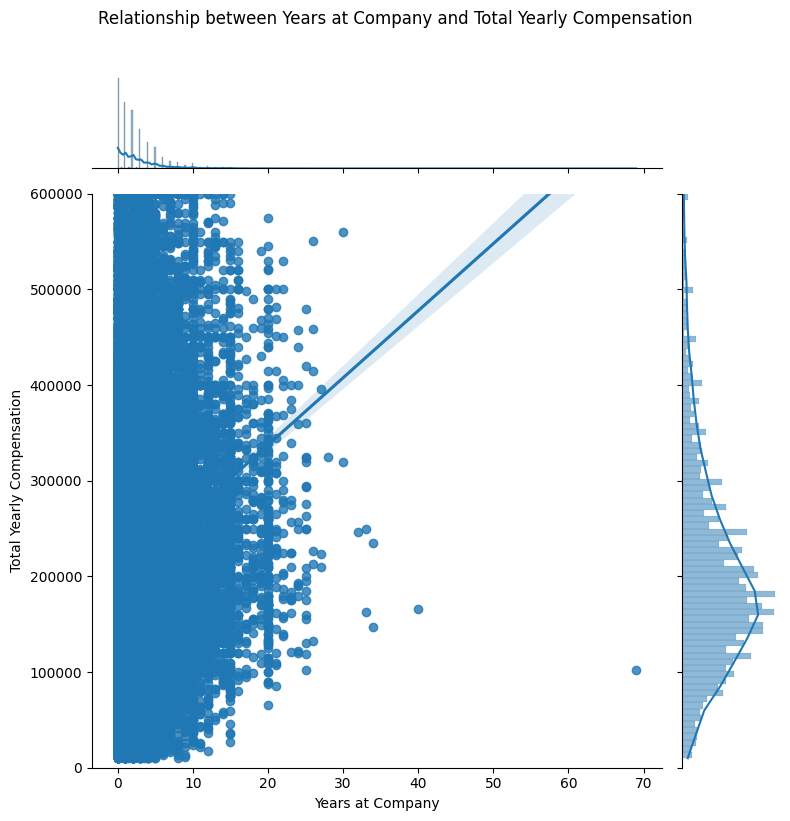

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a joint plot for years at company and total yearly compensation
g = sns.jointplot(data=dfc, x='yearsatcompany', y='totalyearlycompensation', kind='reg', height=8) # Changed kind to 'reg'

# Set y-axis limit for the scatter plot within the jointplot
g.ax_joint.set_ylim(0, 600000)

# Add titles and labels
g.fig.suptitle('Relationship between Years at Company and Total Yearly Compensation', y=1.02) # Add title to the figure
g.set_axis_labels('Years at Company', 'Total Yearly Compensation')

plt.tight_layout()
plt.show()

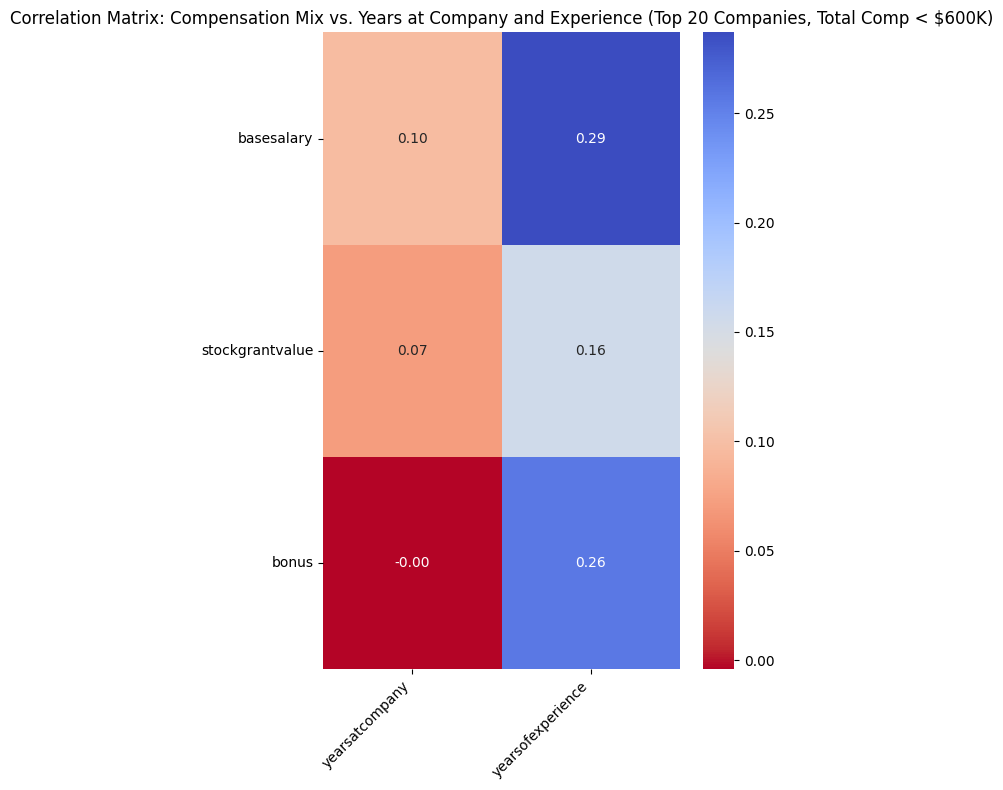

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Assuming dfc is available and cleaned
# Assuming top_companies variable from a previous cell is available

# Filter the data to include only rows from the top companies and where totalyearlycompensation is under 600k
dfc_filtered = dfc[
    (dfc['company'].isin(top_companies)) &
    (dfc['totalyearlycompensation'] < 600000)
].copy()

# Select the relevant numerical columns
correlation_cols = ['basesalary', 'stockgrantvalue', 'bonus', 'yearsatcompany', 'yearsofexperience']

# Calculate the full correlation matrix for the filtered data
full_correlation_matrix = dfc_filtered[correlation_cols].corr()

# Select the correlations between compensation features and years columns
compensation_features = ['basesalary', 'stockgrantvalue', 'bonus']
years_columns = ['yearsatcompany', 'yearsofexperience']

# Extract the relevant sub-matrix
correlation_subset = full_correlation_matrix.loc[compensation_features, years_columns]


# Visualize the correlation subset using a heatmap
plt.figure(figsize=(6, 8)) # Adjust figure size as needed
sns.heatmap(correlation_subset, annot=True, cmap='coolwarm_r', fmt=".2f") # No mask needed for subset
plt.title('Correlation Matrix: Compensation Mix vs. Years at Company and Experience (Top 20 Companies, Total Comp < $600K)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

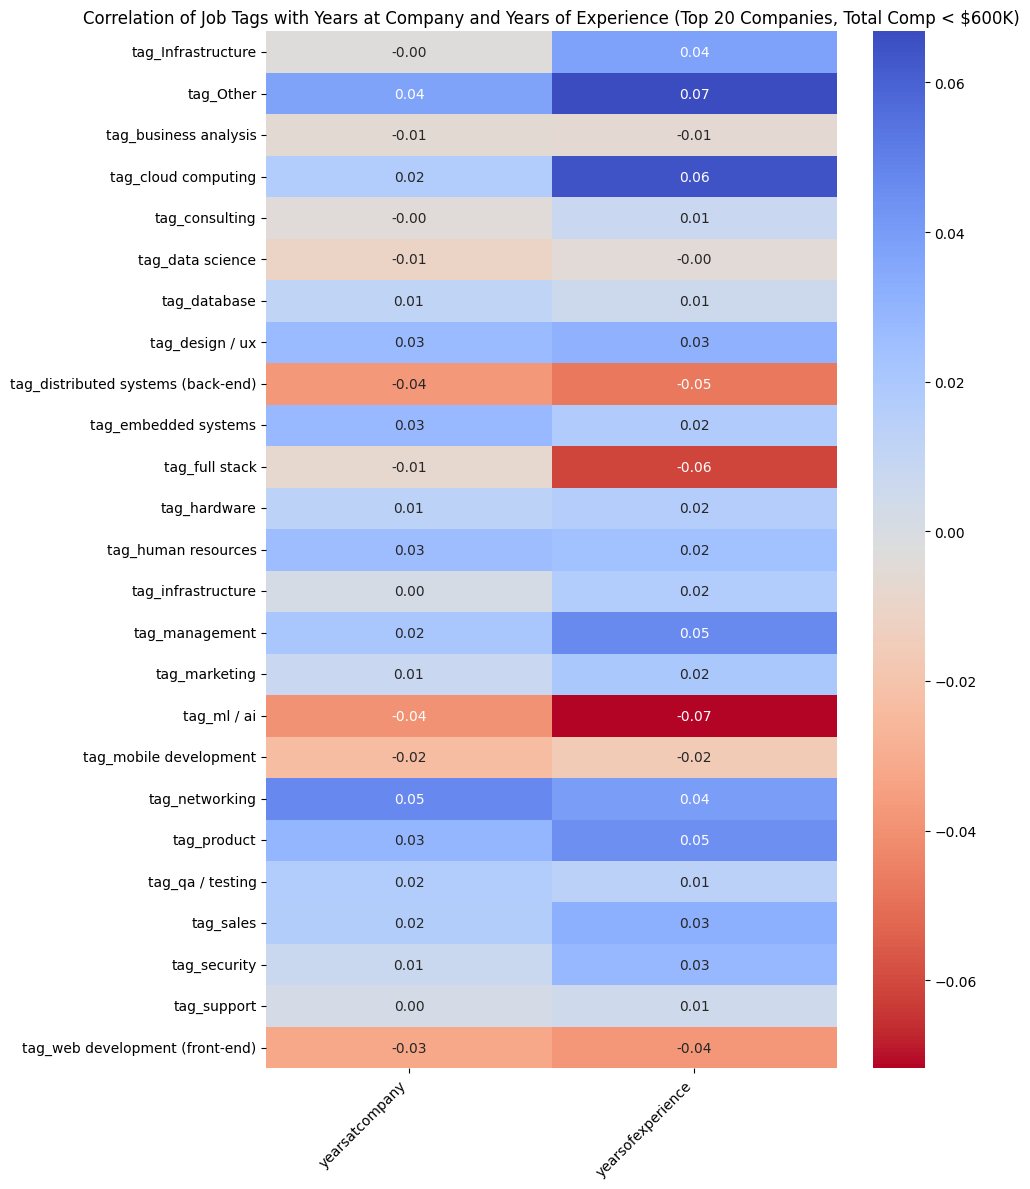

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Assuming tags_encoded contains the one-hot encoded tags and original columns
# Assuming top_companies variable from a previous cell is available

# Filter tags_encoded to include only rows from the top companies
dfc_top_companies = tags_encoded[tags_encoded['company'].isin(top_companies)].copy()

# Also filter to include only rows where totalyearlycompensation is under 600k
dfc_filtered = dfc_top_companies[dfc_top_companies['totalyearlycompensation'] < 600000].copy()

# Identify the one-hot encoded tag columns, excluding 'tag_Unknown Tag'
tag_columns_encoded = [col for col in dfc_filtered.columns if col.startswith('tag_') and col != 'tag_Unknown Tag']

# Select the relevant years columns
years_columns = ['yearsatcompany', 'yearsofexperience']

# Combine the tag columns and years columns
columns_for_correlation = tag_columns_encoded + years_columns

# Ensure all selected columns are in dfc_filtered and are numeric types for correlation
numeric_columns_for_correlation = [col for col in columns_for_correlation if col in dfc_filtered.columns and pd.api.types.is_numeric_dtype(dfc_filtered[col])]

# Calculate the correlation matrix
correlation_matrix = dfc_filtered[numeric_columns_for_correlation].corr()

# To show the correlation between tags and years, select the relevant part of the matrix.
# This will show the correlation of each tag with yearsatcompany and yearsofexperience.
correlation_tags_years = correlation_matrix.loc[tag_columns_encoded, years_columns]

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(10, 12)) # Adjust figure size for readability
sns.heatmap(correlation_tags_years, annot=True, cmap='coolwarm_r', fmt=".2f")
plt.title('Correlation of Job Tags with Years at Company and Years of Experience (Top 20 Companies, Total Comp < $600K)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Assuming dfc is available from previous steps

# Calculate the median years at company from the dataset
median_years_at_company_dataset = dfc['yearsatcompany'].median()

print(f"Median years at company in the dataset: {median_years_at_company_dataset:.2f}")

# Define the classification logic based on the user's proposed definition
# Hoppers: yearsatcompany < years of experience / median years of company in the dataset
# Stayers: otherwise

# Apply the classification to create the 'movement_state' column
# Use .loc to avoid SettingWithCopyWarning
dfc.loc[:, 'movement_state'] = 'Stayer' # Default to Stayer

# Identify hoppers based on the proposed condition
# Ensure yearsofexperience is not 0 to avoid division by zero or infinite values if median is 0
# Also handle potential NaN values in involved columns
hopper_condition = (dfc['yearsatcompany'] < dfc['yearsofexperience'] / median_years_at_company_dataset) & \
                   (dfc['yearsofexperience'] > 0) & \
                   (dfc['yearsatcompany'].notna()) & \
                   (dfc['yearsofexperience'].notna()) & \
                   (pd.notna(median_years_at_company_dataset)) # Ensure median is not NaN

# Apply the 'Hopper' label where the condition is True
dfc.loc[hopper_condition, 'movement_state'] = 'Hopper'

# Display the counts of each movement state
print("\nCounts of 'movement_state':")
print(dfc['movement_state'].value_counts())

# Display the first few rows with the new column
print("\nFirst 5 rows with 'movement_state' column:")
display(dfc.head())

Median years at company in the dataset: 2.00

Counts of 'movement_state':
movement_state
Hopper    33530
Stayer    29112
Name: count, dtype: int64

First 5 rows with 'movement_state' column:


,timestamp,company,level,title,totalyearlycompensation,location,yearsofexperience,yearsatcompany,tag,basesalary,...,Highschool,Some_College,Race_Asian,Race_White,Race_Two_Or_More,Race_Black,Race_Hispanic,Race,Education,movement_state
0,6/7/17 11:33,Oracle,L3,Product Manager,127000,"Redwood City, CA",1.5,1.5,NaN,107000,...,0,0,0,0,0,0,0,NaN,NaN,Stayer
1,6/10/17 17:11,eBay,SE 2,Software Engineer,100000,"San Francisco, CA",5.0,3.0,NaN,0,...,0,0,0,0,0,0,0,NaN,NaN,Stayer
2,6/11/17 14:53,Amazon,L7,Product Manager,310000,"Seattle, WA",8.0,0.0,NaN,155000,...,0,0,0,0,0,0,0,NaN,NaN,Hopper
3,6/17/17 0:23,Apple,M1,Software Engineering Manager,372000,"Sunnyvale, CA",7.0,5.0,NaN,157000,...,0,0,0,0,0,0,0,NaN,NaN,Stayer
4,6/20/17 10:58,Microsoft,60,Software Engineer,157000,"Mountain View, CA",5.0,3.0,NaN,0,...,0,0,0,0,0,0,0,NaN,NaN,Stayer


--- Analysis of Hoppers vs. Stayers (Excluding High Compensation Outliers) ---
Filtering data: Excluding observations with Total Yearly Compensation above $457,950
Number of observations after filtering: 59509

Analyzing Compensation Distribution (Total Yearly Compensation):


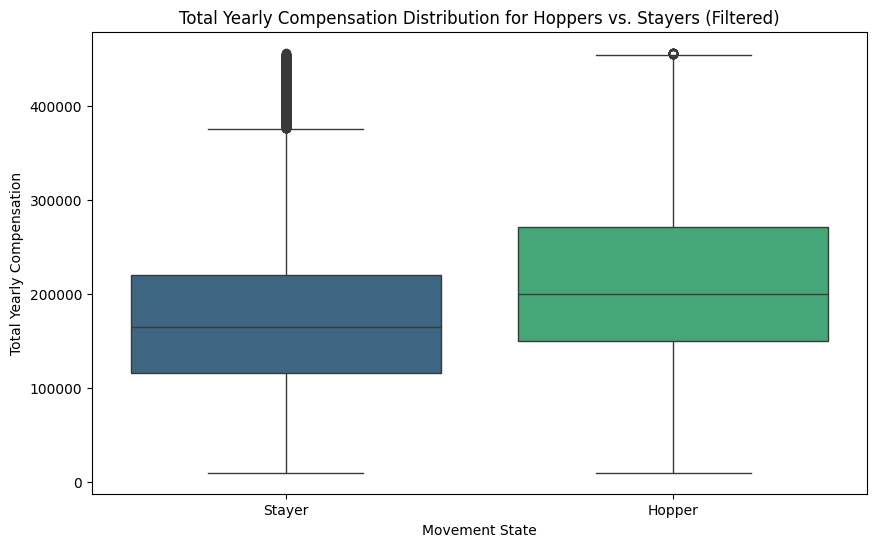

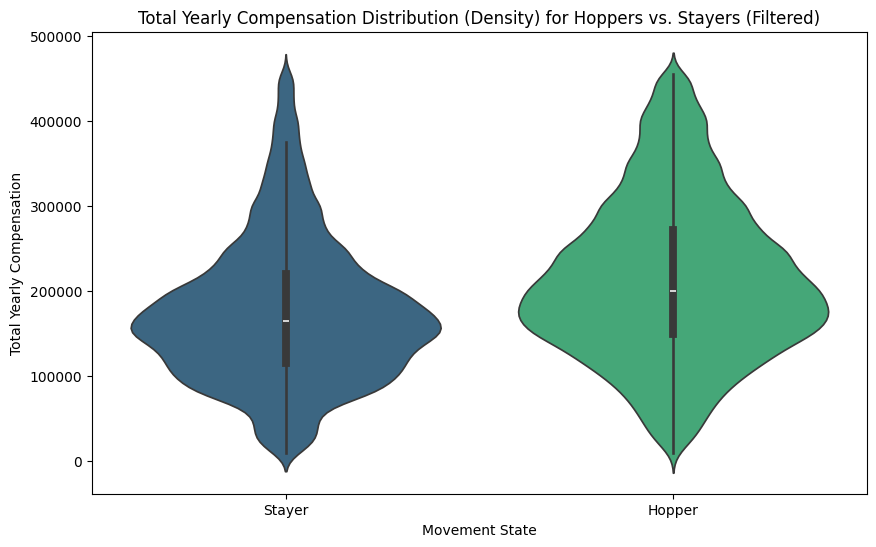


Summary Statistics for Total Yearly Compensation by Movement State (Filtered):


,count,mean,std,min,25%,50%,75%,max
movement_state,,,,,,,,
Hopper,31199.0,213371.842046,93450.470048,10000.0,150000.0,200000.0,272000.0,457000.0
Stayer,28310.0,175427.195549,84687.776583,10000.0,116000.0,165000.0,220000.0,457000.0



Overall Percentage of Hoppers and Stayers (Filtered Dataset):
  Hopper: 52.43%
  Stayer: 47.57%

Analyzing Job Tag Distribution:


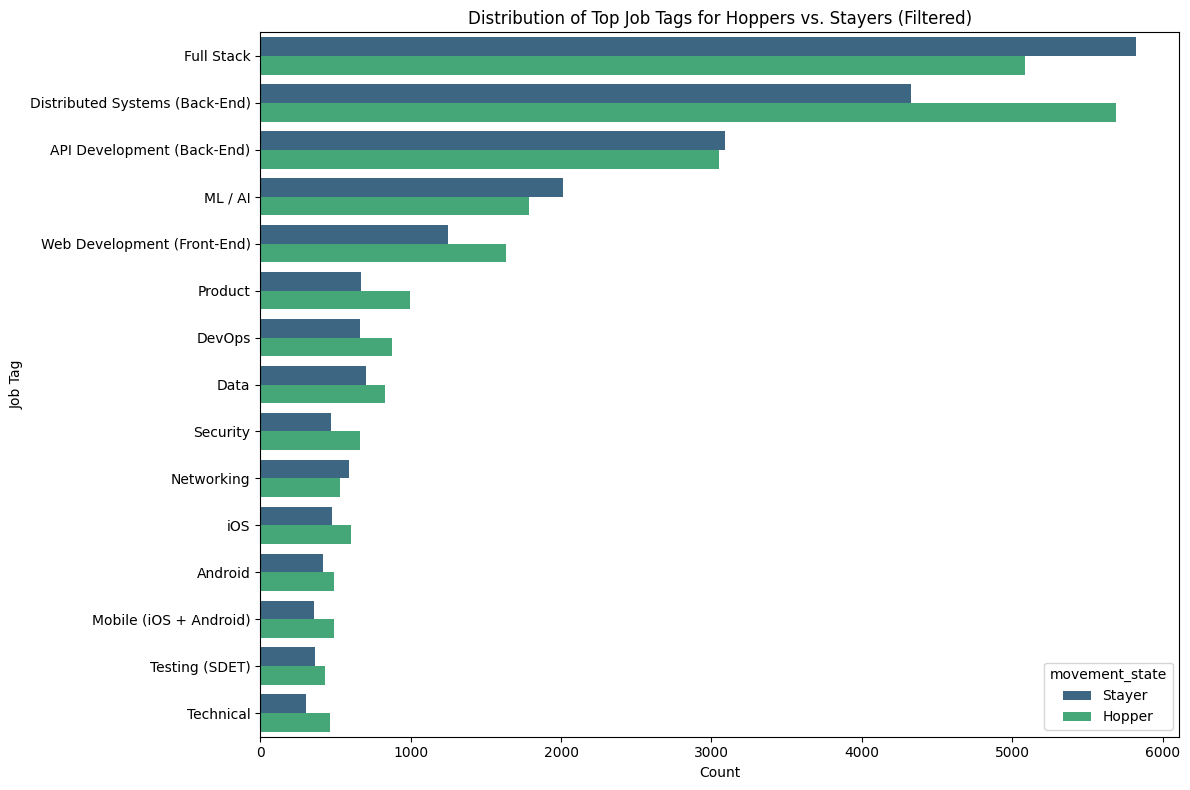


Analyzing Company Distribution (Percentage Stacked Bar Plot):


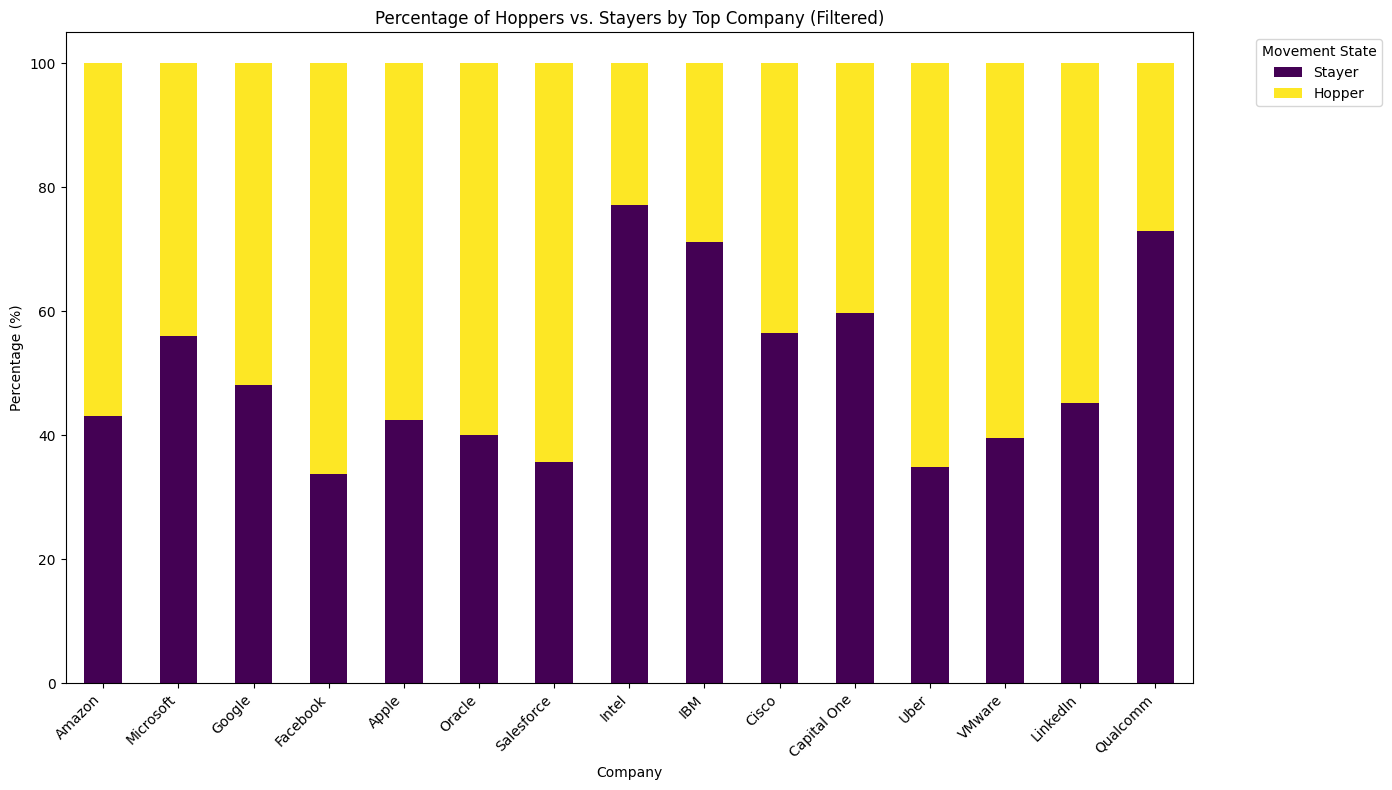


Analysis complete.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc with 'movement_state' column is available

print("--- Analysis of Hoppers vs. Stayers (Excluding High Compensation Outliers) ---")

# Filter out observations with total yearly compensation above the 95th percentile
comp_threshold = dfc['totalyearlycompensation'].quantile(0.95)
dfc_filtered_comp = dfc[dfc['totalyearlycompensation'] <= comp_threshold].copy()

print(f"Filtering data: Excluding observations with Total Yearly Compensation above ${comp_threshold:,.0f}")
print(f"Number of observations after filtering: {dfc_filtered_comp.shape[0]}")

# Calculate the overall percentages of Hoppers and Stayers in the filtered dataset
movement_state_counts = dfc_filtered_comp['movement_state'].value_counts()
total_observations_filtered = dfc_filtered_comp.shape[0]
movement_state_percentages = (movement_state_counts / total_observations_filtered) * 100


# 1. Compensation Analysis
print("\nAnalyzing Compensation Distribution (Total Yearly Compensation):")
plt.figure(figsize=(10, 6))
sns.boxplot(data=dfc_filtered_comp, x='movement_state', y='totalyearlycompensation', palette='viridis')
plt.title('Total Yearly Compensation Distribution for Hoppers vs. Stayers (Filtered)')
plt.xlabel('Movement State')
plt.ylabel('Total Yearly Compensation')
# No need to set ylim here as outliers are excluded from the data
plt.show()

# Optional: Violin plot for density view
plt.figure(figsize=(10, 6))
sns.violinplot(data=dfc_filtered_comp, x='movement_state', y='totalyearlycompensation', palette='viridis')
plt.title('Total Yearly Compensation Distribution (Density) for Hoppers vs. Stayers (Filtered)')
plt.xlabel('Movement State')
plt.ylabel('Total Yearly Compensation')
# No need to set ylim here
plt.show()

# Optional: Summary statistics for compensation
print("\nSummary Statistics for Total Yearly Compensation by Movement State (Filtered):")
display(dfc_filtered_comp.groupby('movement_state')['totalyearlycompensation'].describe())

# Print the overall percentages of Hoppers and Stayers
print("\nOverall Percentage of Hoppers and Stayers (Filtered Dataset):")
for state, percentage in movement_state_percentages.items():
    print(f"  {state}: {percentage:.2f}%")


# 2. Tags Analysis
print("\nAnalyzing Job Tag Distribution:")
# Get top tags from the filtered data
top_tags_overall_filtered = dfc_filtered_comp['tag'].value_counts().nlargest(15).index.tolist() # Top 15 overall tags from filtered data

# Filter data to include only top tags and the two movement states (already filtered by comp)
dfc_top_tags_movement_filtered = dfc_filtered_comp[dfc_filtered_comp['tag'].isin(top_tags_overall_filtered)].copy()

plt.figure(figsize=(12, 8))
sns.countplot(data=dfc_top_tags_movement_filtered, y='tag', hue='movement_state', order=top_tags_overall_filtered, palette='viridis')
plt.title('Distribution of Top Job Tags for Hoppers vs. Stayers (Filtered)')
plt.xlabel('Count')
plt.ylabel('Job Tag')
plt.tight_layout()
plt.show()


# 3. Company Distribution Analysis
print("\nAnalyzing Company Distribution (Percentage Stacked Bar Plot):")
# Calculate counts of Hoppers and Stayers per company from the filtered data
company_movement_counts = dfc_filtered_comp.groupby(['company', 'movement_state']).size().unstack(fill_value=0)

# Calculate the percentage within each company
company_movement_percentages = company_movement_counts.divide(company_movement_counts.sum(axis=1), axis=0) * 100

# Get the top companies based on overall count in the filtered data (for consistency with previous plot)
top_companies_overall_filtered = dfc_filtered_comp['company'].value_counts().nlargest(15).index.tolist()

# Select the percentage data for the top companies and sort to match the order
company_movement_percentages_top = company_movement_percentages.reindex(top_companies_overall_filtered)

# Create a stacked bar plot of the percentages
company_movement_percentages_top[['Stayer', 'Hopper']].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='viridis') # Plot Stayers first then Hoppers
plt.title('Percentage of Hoppers vs. Stayers by Top Company (Filtered)')
plt.xlabel('Company')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Movement State', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


print("\nAnalysis complete.")

--- Analysis of Compensation vs. Years at Company and Years of Experience by Movement State ---

Plotting Total Compensation vs. Years at Company by Movement State...

Evaluating Linear Regression Models for Years at Company:
  Hoppers (Years at Company) - MAE: 74370.08, RMSE: 92749.16
  Stayers (Years at Company) - MAE: 61094.38, RMSE: 79165.03


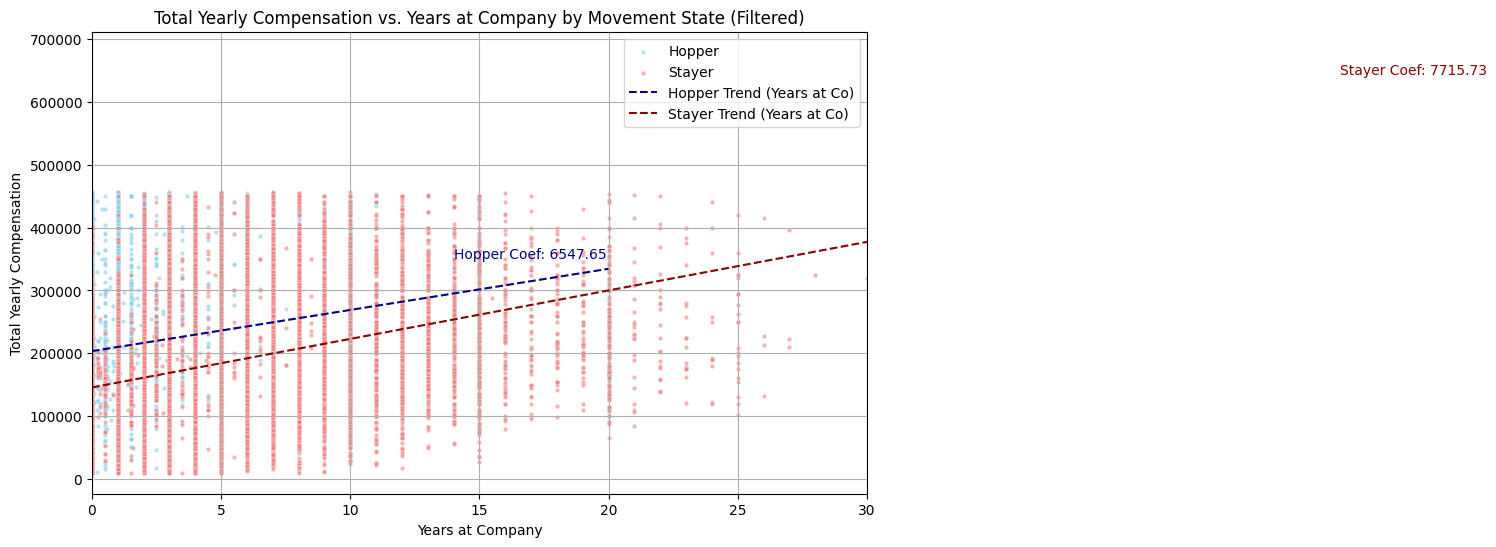


Plotting Total Compensation vs. Years of Experience by Movement State...
Training Linear Regression for Hoppers (Years of Experience)...

Evaluating Linear Regression Models for Years of Experience:
  Hoppers (Years of Experience) - MAE: 70450.52, RMSE: 88620.52
  Stayers (Years of Experience) - MAE: 60463.10, RMSE: 78132.36


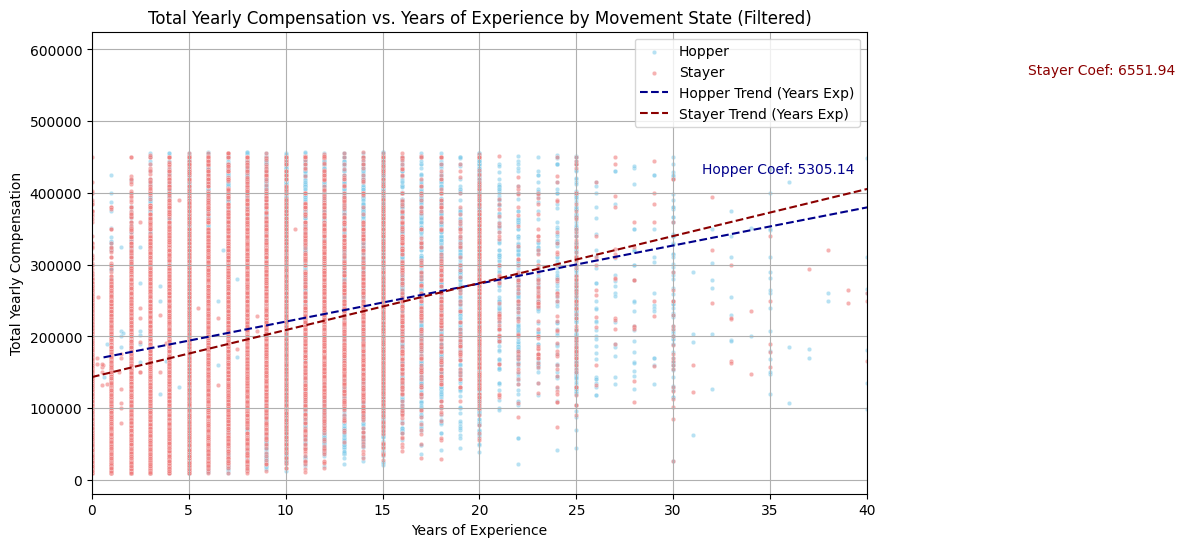


Analysis complete.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Assuming dfc_filtered_comp with 'movement_state' column is available

print("--- Analysis of Compensation vs. Years at Company and Years of Experience by Movement State ---")

# Separate data into Hoppers and Stayers
hoppers_df = dfc_filtered_comp[dfc_filtered_comp['movement_state'] == 'Hopper'].copy()
stayers_df = dfc_filtered_comp[dfc_filtered_comp['movement_state'] == 'Stayer'].copy()

# --- Plot 1: Total Compensation vs. Years at Company ---
print("\nPlotting Total Compensation vs. Years at Company by Movement State...")

# Define features (X) and target (y) for regression (using yearsatcompany as the feature)
feature_at_company = 'yearsatcompany'
target = 'totalyearlycompensation'

X_hoppers_at_co = hoppers_df[[feature_at_company]]
y_hoppers = hoppers_df[target]

X_stayers_at_co = stayers_df[[feature_at_company]]
y_stayers = stayers_df[target]

# Train Linear Regression model for Hoppers (Years at Company)
hopper_model_at_co = LinearRegression()
hopper_model_at_co.fit(X_hoppers_at_co, y_hoppers)

# Train Linear Regression model for Stayers (Years at Company)
stayer_model_at_co = LinearRegression()
stayer_model_at_co.fit(X_stayers_at_co, y_stayers)

# --- Evaluate Models (Years at Company) ---
print("\nEvaluating Linear Regression Models for Years at Company:")
# Predict on the training data
y_pred_hoppers_at_co_train = hopper_model_at_co.predict(X_hoppers_at_co)
y_pred_stayers_at_co_train = stayer_model_at_co.predict(X_stayers_at_co)

# Calculate MAE and RMSE
mae_hoppers_at_co = mean_absolute_error(y_hoppers, y_pred_hoppers_at_co_train)
rmse_hoppers_at_co = np.sqrt(mean_squared_error(y_hoppers, y_pred_hoppers_at_co_train))

mae_stayers_at_co = mean_absolute_error(y_stayers, y_pred_stayers_at_co_train)
rmse_stayers_at_co = np.sqrt(mean_squared_error(y_stayers, y_pred_stayers_at_co_train))

print(f"  Hoppers (Years at Company) - MAE: {mae_hoppers_at_co:.2f}, RMSE: {rmse_hoppers_at_co:.2f}")
print(f"  Stayers (Years at Company) - MAE: {mae_stayers_at_co:.2f}, RMSE: {rmse_stayers_at_co:.2f}")


# --- Plotting (Years at Company) ---
plt.figure(figsize=(10, 6))

# Plot data points for Hoppers
sns.scatterplot(data=hoppers_df, x=feature_at_company, y=target, label='Hopper', color='skyblue', alpha=0.6, s=10)

# Plot data points for Stayers
sns.scatterplot(data=stayers_df, x=feature_at_company, y=target, label='Stayer', color='lightcoral', alpha=0.6, s=10)

# Plot the regression line for Hoppers
x_range_hoppers_at_co = np.linspace(X_hoppers_at_co[feature_at_company].min(), X_hoppers_at_co[feature_at_company].max(), 100).reshape(-1, 1)
y_pred_hoppers_at_co = hopper_model_at_co.predict(x_range_hoppers_at_co)
plt.plot(x_range_hoppers_at_co, y_pred_hoppers_at_co, color='darkblue', linestyle='--', label='Hopper Trend (Years at Co)')

# Plot the regression line for Stayers
x_range_stayers_at_co = np.linspace(X_stayers_at_co[feature_at_company].min(), X_stayers_at_co[feature_at_company].max(), 100).reshape(-1, 1)
y_pred_stayers_at_co = stayer_model_at_co.predict(x_range_stayers_at_co)
plt.plot(x_range_stayers_at_co, y_pred_stayers_at_co, color='darkred', linestyle='--', label='Stayer Trend (Years at Co)')

# Add coefficient annotations for Years at Company plot
plt.text(X_hoppers_at_co[feature_at_company].max() * 0.7, y_pred_hoppers_at_co[-1] * 1.05, f'Hopper Coef: {hopper_model_at_co.coef_[0]:.2f}', color='darkblue', fontsize=10)
plt.text(X_stayers_at_co[feature_at_company].max() * 0.7, y_pred_stayers_at_co[-1] * 0.95, f'Stayer Coef: {stayer_model_at_co.coef_[0]:.2f}', color='darkred', fontsize=10)


plt.title('Total Yearly Compensation vs. Years at Company by Movement State (Filtered)')
plt.xlabel('Years at Company')
plt.ylabel('Total Yearly Compensation')
plt.legend()
plt.grid(True)
plt.xlim(0, 30) # Set x-axis limit for Years at Company plot
plt.show()


# --- Plot 2: Total Compensation vs. Years of Experience ---
print("\nPlotting Total Compensation vs. Years of Experience by Movement State...")

# Define features (X) and target (y) for regression (using yearsofexperience as the feature)
feature_experience = 'yearsofexperience'

# Ensure yearsofexperience is treated as a feature column for training
X_hoppers_exp = hoppers_df[[feature_experience]]
y_hoppers = hoppers_df[target] # Target is the same

X_stayers_exp = stayers_df[[feature_experience]]
y_stayers = stayers_df[target] # Target is the same

# Train Linear Regression model for Hoppers (Years of Experience)
print("Training Linear Regression for Hoppers (Years of Experience)...")
hopper_model_exp = LinearRegression()
hopper_model_exp.fit(X_hoppers_exp, y_hoppers)

# Train Linear Regression model for Stayers (Years of Experience)
stayer_model_exp = LinearRegression()
stayer_model_exp.fit(X_stayers_exp, y_stayers)

# --- Evaluate Models (Years of Experience) ---
print("\nEvaluating Linear Regression Models for Years of Experience:")
# Predict on the training data
y_pred_hoppers_exp_train = hopper_model_exp.predict(X_hoppers_exp)
y_pred_stayers_exp_train = stayer_model_exp.predict(X_stayers_exp)

# Calculate MAE and RMSE
mae_hoppers_exp = mean_absolute_error(y_hoppers, y_pred_hoppers_exp_train)
rmse_hoppers_exp = np.sqrt(mean_squared_error(y_hoppers, y_pred_hoppers_exp_train))

mae_stayers_exp = mean_absolute_error(y_stayers, y_pred_stayers_exp_train)
rmse_stayers_exp = np.sqrt(mean_squared_error(y_stayers, y_pred_stayers_exp_train))

print(f"  Hoppers (Years of Experience) - MAE: {mae_hoppers_exp:.2f}, RMSE: {rmse_hoppers_exp:.2f}")
print(f"  Stayers (Years of Experience) - MAE: {mae_stayers_exp:.2f}, RMSE: {rmse_stayers_exp:.2f}")


# --- Plotting (Years of Experience) ---
plt.figure(figsize=(10, 6))

# Plot data points for Hoppers
sns.scatterplot(data=hoppers_df, x=feature_experience, y=target, label='Hopper', color='skyblue', alpha=0.6, s=10)

# Plot data points for Stayers
sns.scatterplot(data=stayers_df, x=feature_experience, y=target, label='Stayer', color='lightcoral', alpha=0.6, s=10)

# Plot the regression line for Hoppers
x_range_hoppers_exp = np.linspace(X_hoppers_exp[feature_experience].min(), X_hoppers_exp[feature_experience].max(), 100).reshape(-1, 1)
y_pred_hoppers_exp = hopper_model_exp.predict(x_range_hoppers_exp)
plt.plot(x_range_hoppers_exp, y_pred_hoppers_exp, color='darkblue', linestyle='--', label='Hopper Trend (Years Exp)')

# Plot the regression line for Stayers
x_range_stayers_exp = np.linspace(X_stayers_exp[feature_experience].min(), X_stayers_exp[feature_experience].max(), 100).reshape(-1, 1)
y_pred_stayers_exp = stayer_model_exp.predict(x_range_stayers_exp)
plt.plot(x_range_stayers_exp, y_pred_stayers_exp, color='darkred', linestyle='--', label='Stayer Trend (Years Exp)')

# Add coefficient annotations for Years of Experience plot
plt.text(X_hoppers_exp[feature_experience].max() * 0.7, y_pred_hoppers_exp[-1] * 1.05, f'Hopper Coef: {hopper_model_exp.coef_[0]:.2f}', color='darkblue', fontsize=10)
plt.text(X_stayers_exp[feature_experience].max() * 0.7, y_pred_stayers_exp[-1] * 0.95, f'Stayer Coef: {stayer_model_exp.coef_[0]:.2f}', color='darkred', fontsize=10)


plt.title('Total Yearly Compensation vs. Years of Experience by Movement State (Filtered)')
plt.xlabel('Years of Experience')
plt.ylabel('Total Yearly Compensation')
plt.legend()
plt.grid(True)
plt.xlim(0, 40) # Set x-axis limit for Years of Experience plot
plt.show()

print("\nAnalysis complete.")

--- Distribution of Hoppers and Stayers by Binned Years of Experience ---


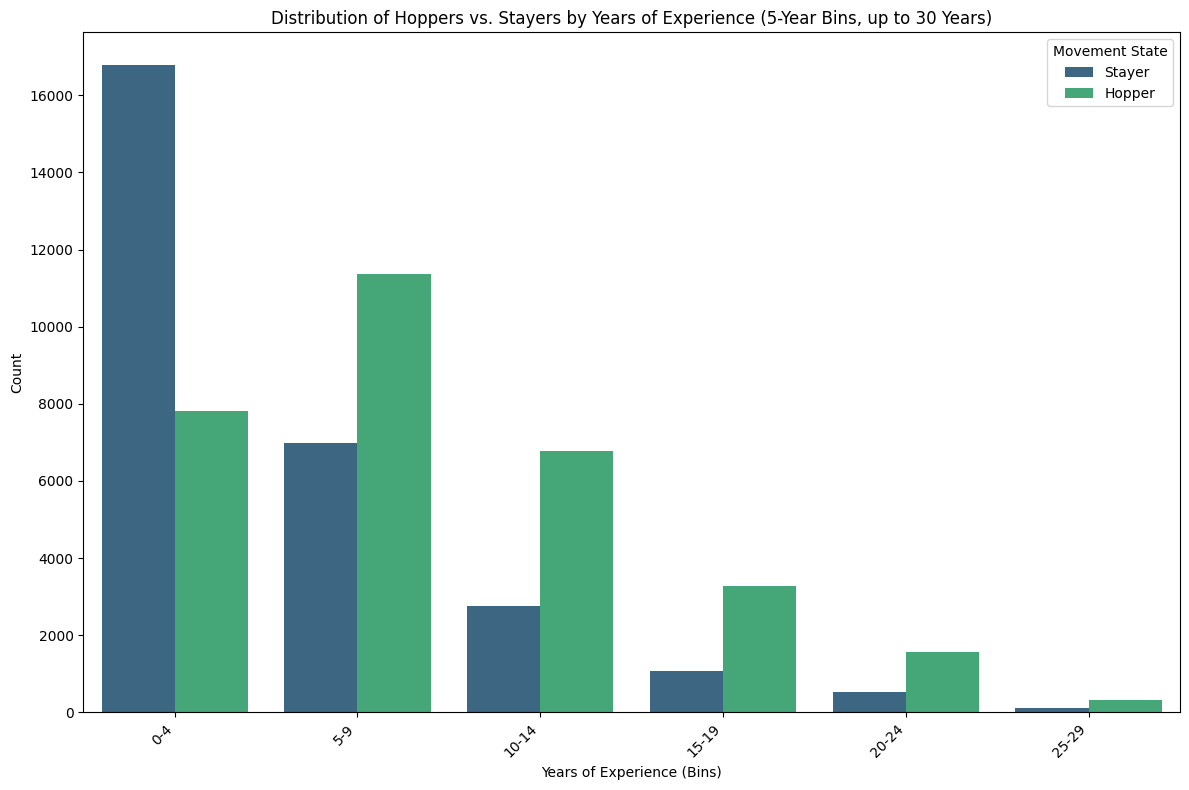


Analysis complete.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc_filtered_comp with 'movement_state' column is available

print("--- Distribution of Hoppers and Stayers by Binned Years of Experience ---")

# Define bin edges for years of experience (0-5, 5-10, ..., up to 30 years) in 5-year intervals
bin_edges = range(0, 31, 5) # Create bins up to 30 years (exclusive of 35)
bin_labels = [f'{i}-{i+4}' for i in range(0, 30, 5)] # Labels for the bins

# Create bins for years of experience in the filtered data
# Use right=False for [a, b) intervals
dfc_filtered_comp['experience_bin'] = pd.cut(
    dfc_filtered_comp['yearsofexperience'],
    bins=bin_edges,
    right=False,
    labels=bin_labels,
    include_lowest=True # Include the lowest value (0)
)

# Filter out any rows that fall outside the defined bins (shouldn't happen with include_lowest and range up to 30)
dfc_binned = dfc_filtered_comp.dropna(subset=['experience_bin']).copy()


# Create a count plot to visualize the distribution of Hoppers and Stayers by experience bin
plt.figure(figsize=(12, 8))
# Use countplot with hue for movement_state
sns.countplot(data=dfc_binned,
              x='experience_bin',
              hue='movement_state',
              order=bin_labels, # Ensure bins are ordered correctly
              palette='viridis') # Use a palette

plt.title('Distribution of Hoppers vs. Stayers by Years of Experience (5-Year Bins, up to 30 Years)')
plt.xlabel('Years of Experience (Bins)')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right') # Rotate labels if they overlap
plt.legend(title='Movement State')
plt.tight_layout()
plt.show()


print("\nAnalysis complete.")

--- Analysis of Stayers with 0-4 Years of Experience ---
Number of Stayers with 0-4 years of experience: 16795

Analyzing Education Level Distribution:


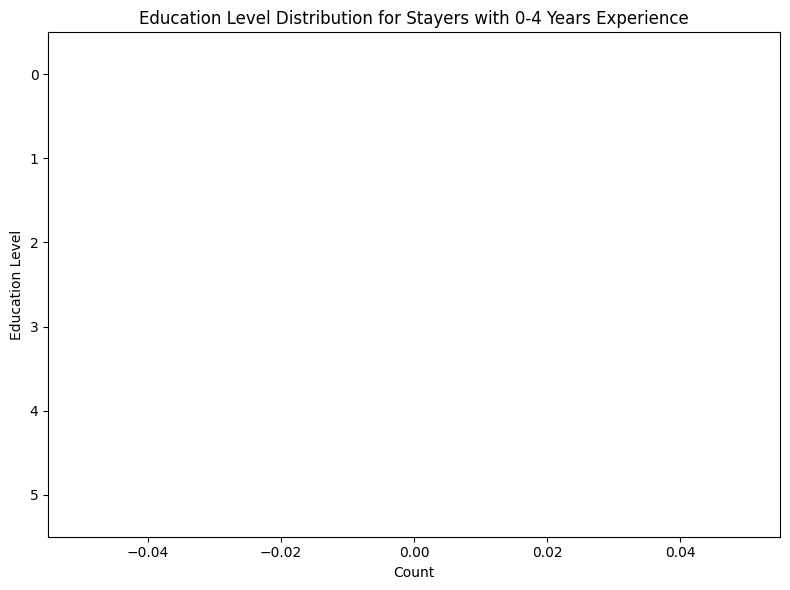


Analyzing Company Distribution:


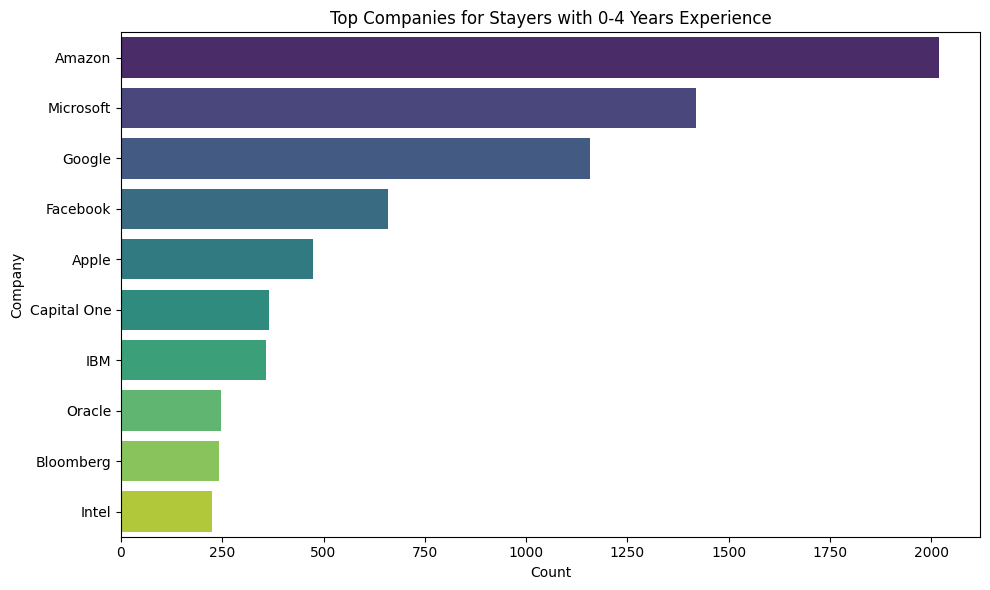


Analyzing Title Distribution:


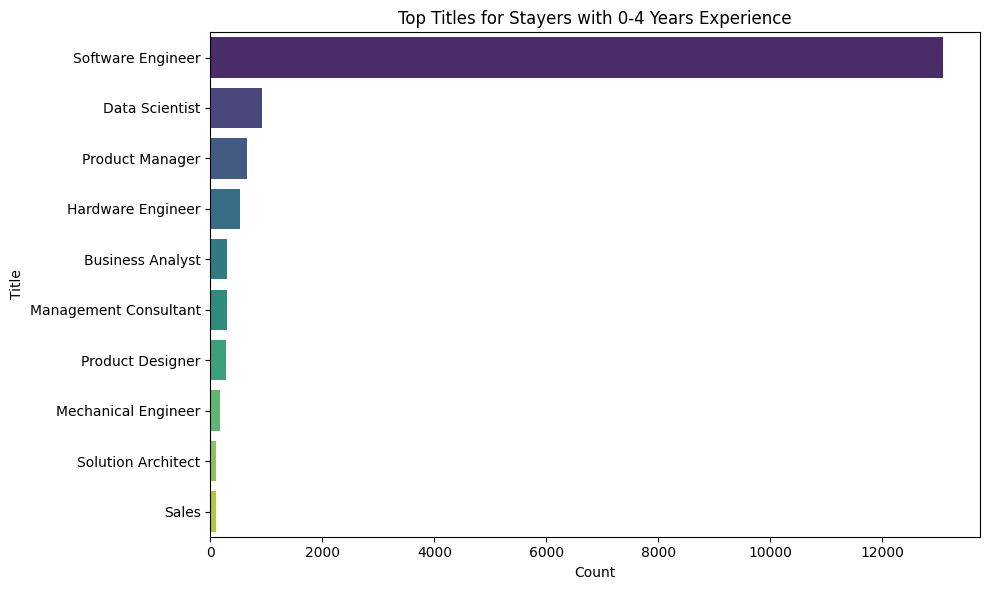


Analyzing Location Distribution:


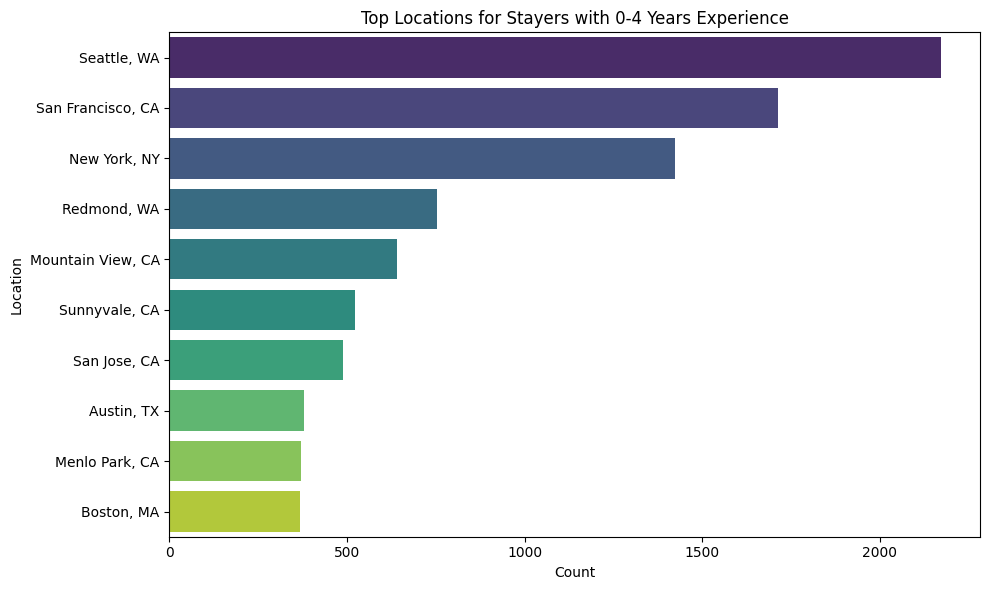


Analyzing Total Yearly Compensation Distribution:


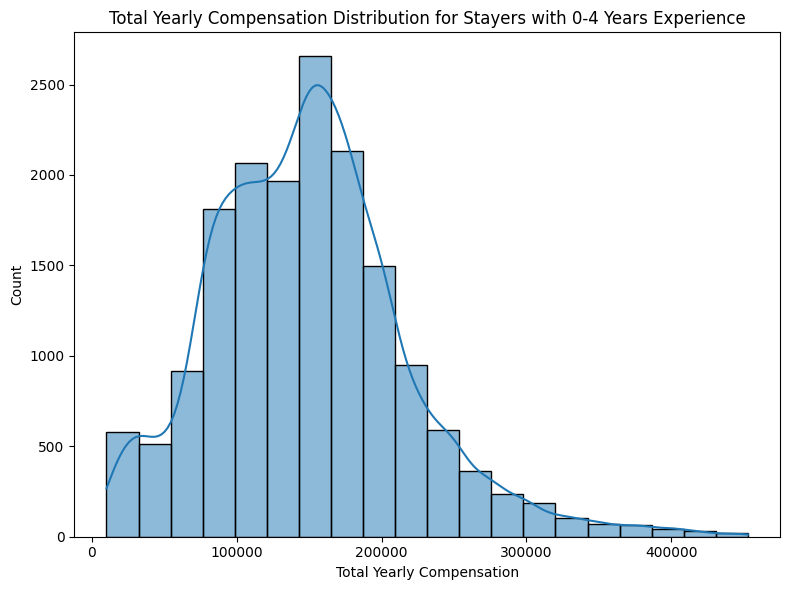


Summary Statistics for Total Yearly Compensation:


,totalyearlycompensation
count,16795.000000
mean,149898.172432
std,67910.746713
min,10000.000000
25%,102000.000000
50%,149000.000000
75%,187000.000000
max,453000.000000



Analysis complete.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc_filtered_comp with 'movement_state' and 'experience_bin' columns is available

print("--- Analysis of Stayers with 0-4 Years of Experience ---")

# Filter the data to include only Stayers in the '0-4' experience bin
stayers_low_experience_df = dfc_filtered_comp[
    (dfc_filtered_comp['movement_state'] == 'Stayer') &
    (dfc_filtered_comp['experience_bin'] == '0-4')
].copy()

print(f"Number of Stayers with 0-4 years of experience: {stayers_low_experience_df.shape[0]}")

if stayers_low_experience_df.empty:
    print("No data found for Stayers with 0-4 years of experience in the filtered dataset.")
else:
    # 1. Education Level Distribution
    print("\nAnalyzing Education Level Distribution:")
    plt.figure(figsize=(8, 6))
    # Order education levels for better visualization
    education_order = ['highschool', 'some college', 'bachelor\'s degree', 'master\'s degree', 'phd'] # Use lowercase to match cleaned data
    # Filter order to include only levels present in the data
    present_education_order = [e for e in education_order if e in stayers_low_experience_df['Education'].unique()]
    sns.countplot(data=stayers_low_experience_df, y='Education', order=present_education_order, palette='viridis')
    plt.title('Education Level Distribution for Stayers with 0-4 Years Experience')
    plt.xlabel('Count')
    plt.ylabel('Education Level')
    plt.tight_layout()
    plt.show()

    # 2. Company Distribution (Top Companies within this group)
    print("\nAnalyzing Company Distribution:")
    # Get top companies within this filtered group
    top_companies_low_exp_stayers = stayers_low_experience_df['company'].value_counts().nlargest(10).index.tolist() # Top 10 companies in this group

    if top_companies_low_exp_stayers:
        dfc_top_companies_low_exp_stayers = stayers_low_experience_df[stayers_low_experience_df['company'].isin(top_companies_low_exp_stayers)].copy()

        plt.figure(figsize=(10, 6))
        sns.countplot(data=dfc_top_companies_low_exp_stayers, y='company', order=top_companies_low_exp_stayers, palette='viridis')
        plt.title('Top Companies for Stayers with 0-4 Years Experience')
        plt.xlabel('Count')
        plt.ylabel('Company')
        plt.tight_layout()
        plt.show()
    else:
        print("  No companies found with sufficient counts in this group for detailed distribution.")

    # 3. Title Distribution (Top Titles within this group)
    print("\nAnalyzing Title Distribution:")
    # Get top titles within this filtered group
    top_titles_low_exp_stayers = stayers_low_experience_df['title'].value_counts().nlargest(10).index.tolist() # Top 10 titles in this group

    if top_titles_low_exp_stayers:
        # Corrected variable name here: stayers_low_experience_df instead of stayers_low_exp_stayers
        dfc_top_titles_low_exp_stayers = stayers_low_experience_df[stayers_low_experience_df['title'].isin(top_titles_low_exp_stayers)].copy()

        plt.figure(figsize=(10, 6))
        sns.countplot(data=dfc_top_titles_low_exp_stayers, y='title', order=top_titles_low_exp_stayers, palette='viridis')
        plt.title('Top Titles for Stayers with 0-4 Years Experience')
        plt.xlabel('Count')
        plt.ylabel('Title')
        plt.tight_layout()
        plt.show()
    else:
        print("  No titles found with sufficient counts in this group for detailed distribution.")


    # 4. Location Distribution (Top Locations within this group)
    print("\nAnalyzing Location Distribution:")
    # Get top locations within this filtered group
    top_locations_low_exp_stayers = stayers_low_experience_df['location'].value_counts().nlargest(10).index.tolist() # Top 10 locations in this group

    if top_locations_low_exp_stayers:
        # Corrected variable name here: stayers_low_experience_df instead of stayers_low_exp_stayers
        dfc_top_locations_low_exp_stayers = stayers_low_experience_df[stayers_low_experience_df['location'].isin(top_locations_low_exp_stayers)].copy()

        plt.figure(figsize=(10, 6))
        sns.countplot(data=dfc_top_locations_low_exp_stayers, y='location', order=top_locations_low_exp_stayers, palette='viridis')
        plt.title('Top Locations for Stayers with 0-4 Years Experience')
        plt.xlabel('Count')
        plt.ylabel('Location')
        plt.tight_layout()
        plt.show()
    else:
        print("  No locations found with sufficient counts in this group for detailed distribution.")


    # 5. Compensation Analysis (Distribution) - Keeping the original compensation analysis
    print("\nAnalyzing Total Yearly Compensation Distribution:")
    plt.figure(figsize=(8, 6))
    sns.histplot(data=stayers_low_experience_df, x='totalyearlycompensation', kde=True, bins=20, palette='viridis') # Use histplot for distribution
    plt.title('Total Yearly Compensation Distribution for Stayers with 0-4 Years Experience')
    plt.xlabel('Total Yearly Compensation')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

    # Optional: Summary statistics for compensation
    print("\nSummary Statistics for Total Yearly Compensation:")
    display(stayers_low_experience_df['totalyearlycompensation'].describe())


print("\nAnalysis complete.")

--- Distribution of Hoppers and Stayers by Years of Experience (with KDE) ---


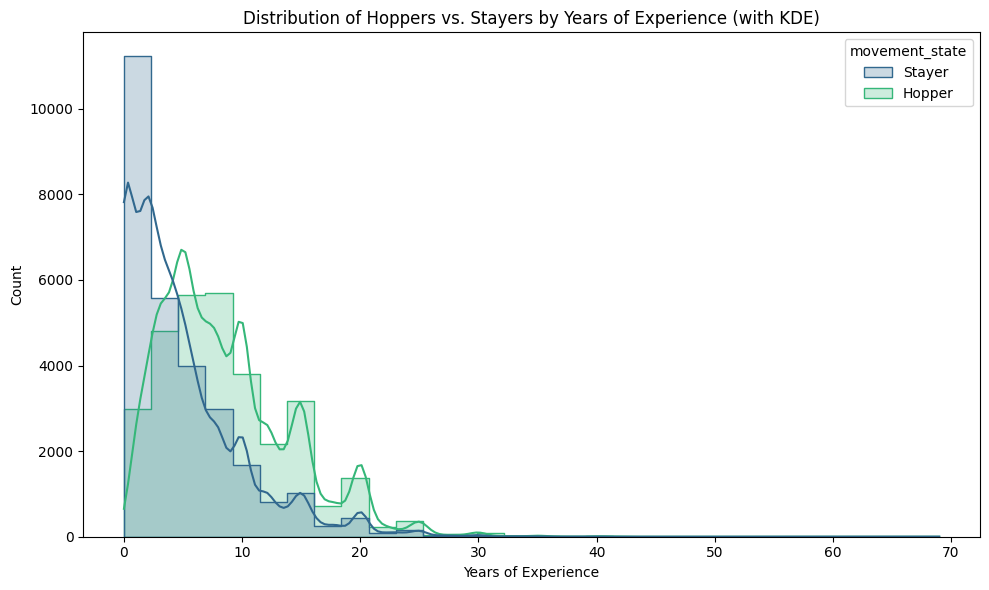


Analysis complete.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming dfc_filtered_comp with 'movement_state' column is available

print("--- Distribution of Hoppers and Stayers by Years of Experience (with KDE) ---")

# Create a histogram with KDE for years of experience, separated by movement state
plt.figure(figsize=(10, 6))
sns.histplot(data=dfc_filtered_comp,
             x='yearsofexperience',
             hue='movement_state',
             kde=True, # Add KDE trendline
             bins=30, # Adjust bin number as needed for visualization
             palette='viridis',
             element='step' # Use step to avoid overlap
            )
plt.title('Distribution of Hoppers vs. Stayers by Years of Experience (with KDE)')
plt.xlabel('Years of Experience')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

print("\nAnalysis complete.")

# Predicting Career Outcomes

# New Section

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, r2_score, classification_report
import warnings

# Suppress warnings for cleaner output during modeling
warnings.filterwarnings('ignore')

# Assuming dfc is available and cleaned
# Assuming top_companies is available (list of top companies)
# Assuming tags_encoded is available (DataFrame with one-hot encoded tags)

print("--- Multi-Target Prediction with Random Forest (Top Companies) ---")

# 1. Data Preparation
# Filter dfc for top companies
dfc_top_companies = dfc[dfc['company'].isin(top_companies)].copy()

# Ensure totalyearlycompensation is not NaN before using it for comp mix calculation
dfc_top_companies.dropna(subset=['totalyearlycompensation', 'basesalary', 'stockgrantvalue', 'bonus'], inplace=True)

# Calculate compensation mix percentages
dfc_top_companies['total_comp_sum'] = dfc_top_companies[['basesalary', 'stockgrantvalue', 'bonus']].sum(axis=1)
# Avoid division by zero by adding a small epsilon or checking if the sum is > 0
epsilon = 1e-9 # Small value to prevent division by zero
dfc_top_companies['basesalary_percentage'] = dfc_top_companies['basesalary'] / (dfc_top_companies['total_comp_sum'] + epsilon)
dfc_top_companies['stockgrantvalue_percentage'] = dfc_top_companies['stockgrantvalue'] / (dfc_top_companies['total_comp_sum'] + epsilon)
dfc_top_companies['bonus_percentage'] = dfc_top_companies['bonus'] / (dfc_top_companies['total_comp_sum'] + epsilon)

# Re-normalize to ensure percentages sum to 1 after division if needed (optional, depending on model target)
# For simplicity, we'll use the calculated percentages as is, assuming the model learns to predict these proportions.


# Select Features
# Numerical Feature
numerical_features = ['yearsofexperience']

# Education Level - Handle progressive nature with Ordinal Encoding
# Define the order of education levels
education_order = ['highschool', 'some college', 'bachelor\'s degree', 'master\'s degree', 'phd']
# Use OrdinalEncoder to encode education level based on the defined order
# Ensure Education column is string type before encoding and handle potential NaNs
dfc_top_companies['Education'] = dfc_top_companies['Education'].astype(str).replace('nan', education_order[0]) # Replace NaN string with lowest level
# Filter out any levels not in our defined order before encoding to prevent errors
dfc_top_companies = dfc_top_companies[dfc_top_companies['Education'].isin(education_order)].copy()

ordinal_features = ['Education']

# Tags - Already one-hot encoded in tags_encoded. Need to merge/align.
# Ensure tags_encoded is also filtered for top companies and aligned
tags_encoded_top_companies = tags_encoded[tags_encoded['company'].isin(top_companies)].copy()
# Align indices if necessary (assuming dfc_top_companies and tags_encoded_top_companies have same index after filtering)
# Ensure both dataframes have the same index before aligning
common_index = dfc_top_companies.index.intersection(tags_encoded_top_companies.index)
dfc_top_companies = dfc_top_companies.loc[common_index]
tags_encoded_top_companies = tags_encoded_top_companies.loc[common_index]

tag_features = [col for col in tags_encoded_top_companies.columns if col.startswith('tag_') and col != 'tag_Unknown Tag'] # Exclude Unknown Tag

# Location - Categorical, needs One-Hot Encoding
categorical_features = ['location']


# Select Target Variables
target_company = 'company'
target_role = 'title'
target_salary = 'totalyearlycompensation'
target_comp_mix = ['basesalary_percentage', 'stockgrantvalue_percentage', 'bonus_percentage']

# Combine Features
# Create preprocessing pipelines for different feature types
# We'll use a pipeline to handle encoding within the modeling process if needed, but here we are preparing X first.
# Let's manually encode ordinal and categorical features for combining with tags
ordinal_encoder = OrdinalEncoder(categories=[education_order])
dfc_top_companies['Education_encoded'] = ordinal_encoder.fit_transform(dfc_top_companies[['Education']])

onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False) # Use sparse_output=False for dense array
location_encoded = onehot_encoder.fit_transform(dfc_top_companies[['location']])
# Get feature names for one-hot encoded locations
location_feature_names = onehot_encoder.get_feature_names_out(['location'])
location_encoded_df = pd.DataFrame(location_encoded, columns=location_feature_names, index=dfc_top_companies.index)


# Combine all features into a single DataFrame
X_combined = dfc_top_companies[numerical_features].copy() # Start with numerical
X_combined['Education_encoded'] = dfc_top_companies['Education_encoded'] # Add ordinal education
X_combined = pd.concat([X_combined, location_encoded_df], axis=1) # Add one-hot locations
X_combined = pd.concat([X_combined, tags_encoded_top_companies[tag_features]], axis=1) # Add one-hot tags


# Select Target Variables (ensure these are also filtered and aligned)
y_company = dfc_top_companies[target_company]
y_role = dfc_top_companies[target_role]
y_salary = dfc_top_companies[target_salary]
y_comp_mix = dfc_top_companies[target_comp_mix]


# Drop rows with any remaining NaNs in features or targets (should be minimal after cleaning and filtering)
# Ensure X_combined and all y variables have the same index and no NaNs in relevant columns
combined_data = X_combined.copy()
combined_data[target_company] = y_company
combined_data[target_role] = y_role
combined_data[target_salary] = y_salary
combined_data[target_comp_mix] = y_comp_mix

combined_data.dropna(subset=X_combined.columns.tolist() + [target_company, target_role, target_salary] + target_comp_mix, inplace=True)

X_final = combined_data[X_combined.columns]
y_company_final = combined_data[target_company]
y_role_final = combined_data[target_role]
y_salary_final = combined_data[target_salary]
y_comp_mix_final = combined_data[target_comp_mix]

print(f"\nData prepared for modeling. Final feature shape: {X_final.shape}, Final target shape: {y_company_final.shape}")


# Split data into training and testing sets
X_train, X_test, y_company_train, y_company_test, y_role_train, y_role_test, y_salary_train, y_salary_test, y_comp_mix_train, y_comp_mix_test = train_test_split(
    X_final, y_company_final, y_role_final, y_salary_final, y_comp_mix_final, test_size=0.3, random_state=42
)

print(f"Data split: Train samples = {X_train.shape[0]}, Test samples = {X_test.shape[0]}")


# 2. Model Selection and Training

trained_models = {}
evaluation_results = {}

# Train RandomForestClassifier for Company Prediction
print("\nTraining RandomForestClassifier for Company Prediction...")
company_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
company_model.fit(X_train, y_company_train)
trained_models['company_model'] = company_model

# Evaluate Company Model
y_company_pred = company_model.predict(X_test)
company_accuracy = accuracy_score(y_company_test, y_company_pred)
# company_report = classification_report(y_company_test, y_company_pred, zero_division=0) # Classification report can be very long
evaluation_results['company_model'] = {'accuracy': company_accuracy} #, 'report': company_report}
print(f"  Company Prediction Accuracy: {company_accuracy:.4f}")


# Train RandomForestClassifier for Role (Title) Prediction
print("\nTraining RandomForestClassifier for Role (Title) Prediction...")
role_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
role_model.fit(X_train, y_role_train)
trained_models['role_model'] = role_model

# Evaluate Role Model
y_role_pred = role_model.predict(X_test)
role_accuracy = accuracy_score(y_role_test, y_role_pred)
# role_report = classification_report(y_role_test, y_role_pred, zero_division=0) # Classification report can be very long
evaluation_results['role_model'] = {'accuracy': role_accuracy} #, 'report': role_report}
print(f"  Role (Title) Prediction Accuracy: {role_accuracy:.4f}")


# Train RandomForestRegressor for Salary (Total Yearly Compensation) Prediction
print("\nTraining RandomForestRegressor for Salary Prediction...")
salary_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
salary_model.fit(X_train, y_salary_train)
trained_models['salary_model'] = salary_model

# Evaluate Salary Model
y_salary_pred = salary_model.predict(X_test)
salary_mae = mean_absolute_error(y_salary_test, y_salary_pred)
salary_rmse = np.sqrt(mean_squared_error(y_salary_test, y_salary_pred))
salary_r2 = r2_score(y_salary_test, y_salary_pred)
evaluation_results['salary_model'] = {'MAE': salary_mae, 'RMSE': salary_rmse, 'R2': salary_r2}
print(f"  Salary Prediction - MAE: {salary_mae:.2f}, RMSE: {salary_rmse:.2f}, R2: {salary_r2:.4f}")


# Train RandomForestRegressor for Compensation Mix Prediction (Multi-Output)
print("\nTraining RandomForestRegressor for Compensation Mix Prediction...")
comp_mix_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
comp_mix_model.fit(X_train, y_comp_mix_train)
trained_models['comp_mix_model'] = comp_mix_model # This is the multi-output model

# Evaluate Compensation Mix Model
y_comp_mix_pred = comp_mix_model.predict(X_test)
comp_mix_evaluation_metrics = {}
# Evaluate each output separately
for i, comp_col in enumerate(target_comp_mix):
    mae = mean_absolute_error(y_comp_mix_test[comp_col], y_comp_mix_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_comp_mix_test[comp_col], y_comp_mix_pred[:, i]))
    r2 = r2_score(y_comp_mix_test[comp_col], y_comp_mix_pred[:, i])

    comp_mix_evaluation_metrics[comp_col] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}
    print(f"  Compensation Mix Prediction - {comp_col} - MAE: {mae:.4f}, RMSE: {rmse:.4f}, R2: {r2:.4f}")

evaluation_results['comp_mix_model'] = comp_mix_evaluation_metrics


print("\nAll models trained and evaluated.")

# Store the final trained models and evaluation results globally if needed by other cells
# globals()['trained_models'] = trained_models
# globals()['evaluation_results'] = evaluation_results # Keep evaluation results for review

--- Multi-Target Prediction with Random Forest (Top Companies) ---

Data prepared for modeling. Final feature shape: (64, 49), Final target shape: (64,)
Data split: Train samples = 44, Test samples = 20

Training RandomForestClassifier for Company Prediction...
  Company Prediction Accuracy: 0.8000

Training RandomForestClassifier for Role (Title) Prediction...
  Role (Title) Prediction Accuracy: 0.5000

Training RandomForestRegressor for Salary Prediction...
  Salary Prediction - MAE: 57932.33, RMSE: 74405.24, R2: 0.1535

Training RandomForestRegressor for Compensation Mix Prediction...
  Compensation Mix Prediction - basesalary_percentage - MAE: 0.1711, RMSE: 0.2157, R2: -0.2636
  Compensation Mix Prediction - stockgrantvalue_percentage - MAE: 0.1890, RMSE: 0.2274, R2: -0.6666
  Compensation Mix Prediction - bonus_percentage - MAE: 0.0666, RMSE: 0.0749, R2: -0.1651

All models trained and evaluated.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, r2_score, classification_report
import warnings

# Suppress warnings for cleaner output during modeling
warnings.filterwarnings('ignore')

# Assuming dfc is available and cleaned
# Assuming tags_encoded is available (DataFrame with one-hot encoded tags)

print("--- Multi-Target Prediction with Random Forest (Full Dataset) ---")

# 1. Data Preparation
# Use the full dfc DataFrame
dfc_full = dfc.copy()

# Ensure totalyearlycompensation is not NaN before using it for comp mix calculation
dfc_full.dropna(subset=['totalyearlycompensation', 'basesalary', 'stockgrantvalue', 'bonus'], inplace=True)

# Calculate compensation mix percentages
dfc_full['total_comp_sum'] = dfc_full[['basesalary', 'stockgrantvalue', 'bonus']].sum(axis=1)
# Avoid division by zero by adding a small epsilon or checking if the sum is > 0
epsilon = 1e-9 # Small value to prevent division by zero
dfc_full['basesalary_percentage'] = dfc_full['basesalary'] / (dfc_full['total_comp_sum'] + epsilon)
dfc_full['stockgrantvalue_percentage'] = dfc_full['stockgrantvalue'] / (dfc_full['total_comp_sum'] + epsilon)
dfc_full['bonus_percentage'] = dfc_full['bonus'] / (dfc_full['total_comp_sum'] + epsilon)

# Select Features
# Numerical Feature
numerical_features = ['yearsofexperience']

# Education Level - Handle progressive nature with Ordinal Encoding
# Define the order of education levels
education_order = ['highschool', 'some college', 'bachelor\'s degree', 'master\'s degree', 'phd']
# Use OrdinalEncoder to encode education level based on the defined order
# Ensure Education column is string type before encoding and handle potential NaNs
dfc_full['Education'] = dfc_full['Education'].astype(str).replace('nan', education_order[0]) # Replace NaN string with lowest level
# Filter out any levels not in our defined order before encoding to prevent errors
dfc_full = dfc_full[dfc_full['Education'].isin(education_order)].copy()

ordinal_features = ['Education']

# Tags - Already one-hot encoded in tags_encoded. Need to merge/align.
# Use the full tags_encoded DataFrame
tags_encoded_full = tags_encoded.copy()
# Align indices if necessary (assuming dfc_full and tags_encoded_full have same index after filtering)
# Ensure both dataframes have the same index before aligning
common_index = dfc_full.index.intersection(tags_encoded_full.index)
dfc_full = dfc_full.loc[common_index]
tags_encoded_full = tags_encoded_full.loc[common_index]


tag_features = [col for col in tags_encoded_full.columns if col.startswith('tag_') and col != 'tag_Unknown Tag'] # Exclude Unknown Tag

# Location - Categorical, needs One-Hot Encoding
categorical_features = ['location']


# Select Target Variables
target_company = 'company'
target_role = 'title'
target_salary = 'totalyearlycompensation'
target_comp_mix = ['basesalary_percentage', 'stockgrantvalue_percentage', 'bonus_percentage']

# Combine Features
# Let's manually encode ordinal and categorical features for combining with tags
ordinal_encoder = OrdinalEncoder(categories=[education_order])
dfc_full['Education_encoded'] = ordinal_encoder.fit_transform(dfc_full[['Education']])

onehot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False) # Use sparse_output=False for dense array
location_encoded = onehot_encoder.fit_transform(dfc_full[['location']])
# Get feature names for one-hot encoded locations
location_feature_names = onehot_encoder.get_feature_names_out(['location'])
location_encoded_df = pd.DataFrame(location_encoded, columns=location_feature_names, index=dfc_full.index)


# Combine all features into a single DataFrame
X_combined = dfc_full[numerical_features].copy() # Start with numerical
X_combined['Education_encoded'] = dfc_full['Education_encoded'] # Add ordinal education
X_combined = pd.concat([X_combined, location_encoded_df], axis=1) # Add one-hot locations
X_combined = pd.concat([X_combined, tags_encoded_full[tag_features]], axis=1) # Add one-hot tags


# Select Target Variables (ensure these are also filtered and aligned)
y_company = dfc_full[target_company]
y_role = dfc_full[target_role]
y_salary = dfc_full[target_salary]
y_comp_mix = dfc_full[target_comp_mix]


# Drop rows with any remaining NaNs in features or targets (should be minimal after cleaning and filtering)
# Ensure X_combined and all y variables have the same index and no NaNs in relevant columns
combined_data = X_combined.copy()
combined_data[target_company] = y_company
combined_data[target_role] = y_role
combined_data[target_salary] = y_salary
combined_data[target_comp_mix] = y_comp_mix

combined_data.dropna(subset=X_combined.columns.tolist() + [target_company, target_role, target_salary] + target_comp_mix, inplace=True)

X_final = combined_data[X_combined.columns]
y_company_final = combined_data[target_company]
y_role_final = combined_data[target_role]
y_salary_final = combined_data[target_salary]
y_comp_mix_final = combined_data[target_comp_mix]


print(f"\nData prepared for modeling. Final feature shape: {X_final.shape}, Final target shape: {y_company_final.shape}")


# Split data into training and testing sets
X_train, X_test, y_company_train, y_company_test, y_role_train, y_role_test, y_salary_train, y_salary_test, y_comp_mix_train, y_comp_mix_test = train_test_split(
    X_final, y_company_final, y_role_final, y_salary_final, y_comp_mix_final, test_size=0.3, random_state=42
)

print(f"Data split: Train samples = {X_train.shape[0]}, Test samples = {X_test.shape[0]}")


# 2. Model Selection and Training

trained_models_full = {} # Use different variable name to avoid conflicts
evaluation_results_full = {} # Use different variable name to avoid conflicts

# Train RandomForestClassifier for Company Prediction
print("\nTraining RandomForestClassifier for Company Prediction...")
company_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
company_model.fit(X_train, y_company_train)
trained_models_full['company_model'] = company_model

# Evaluate Company Model
y_company_pred = company_model.predict(X_test)
company_accuracy = accuracy_score(y_company_test, y_company_pred)
# company_report = classification_report(y_company_test, y_company_pred, zero_division=0) # Classification report can be very long
evaluation_results_full['company_model'] = {'accuracy': company_accuracy} #, 'report': company_report}
print(f"  Company Prediction Accuracy: {company_accuracy:.4f}")


# Train RandomForestClassifier for Role (Title) Prediction
print("\nTraining RandomForestClassifier for Role (Title) Prediction...")
role_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
role_model.fit(X_train, y_role_train)
trained_models_full['role_model'] = role_model

# Evaluate Role Model
y_role_pred = role_model.predict(X_test)
role_accuracy = accuracy_score(y_role_test, y_role_pred)
# role_report = classification_report(y_role_test, y_role_pred, zero_division=0) # Classification report can be very long
evaluation_results_full['role_model'] = {'accuracy': role_accuracy} #, 'report': role_report}
print(f"  Role (Title) Prediction Accuracy: {role_accuracy:.4f}")


# Train RandomForestRegressor for Salary (Total Yearly Compensation) Prediction
print("\nTraining RandomForestRegressor for Salary Prediction...")
salary_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
salary_model.fit(X_train, y_salary_train)
trained_models_full['salary_model'] = salary_model

# Evaluate Salary Model
y_salary_pred = salary_model.predict(X_test)
salary_mae = mean_absolute_error(y_salary_test, y_salary_pred)
salary_rmse = np.sqrt(mean_squared_error(y_salary_test, y_salary_pred))
salary_r2 = r2_score(y_salary_test, y_salary_pred)
evaluation_results_full['salary_model'] = {'MAE': salary_mae, 'RMSE': salary_rmse, 'R2': salary_r2}
print(f"  Salary Prediction - MAE: {salary_mae:.2f}, RMSE: {salary_rmse:.2f}, R2: {salary_r2:.4f}")


# Train RandomForestRegressor for Compensation Mix Prediction (Multi-Output)
print("\nTraining RandomForestRegressor for Compensation Mix Prediction...")
comp_mix_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
comp_mix_model.fit(X_train, y_comp_mix_train)
trained_models_full['comp_mix_model'] = comp_mix_model # This is the multi-output model

# Evaluate Compensation Mix Model
y_comp_mix_pred = comp_mix_model.predict(X_test)
comp_mix_evaluation_metrics = {}
# Evaluate each output separately
for i, comp_col in enumerate(target_comp_mix):
    mae = mean_absolute_error(y_comp_mix_test[comp_col], y_comp_mix_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_comp_mix_test[comp_col], y_comp_mix_pred[:, i]))
    r2 = r2_score(y_comp_mix_test[comp_col], y_comp_mix_pred[:, i])

    comp_mix_evaluation_metrics[comp_col] = {'MAE': mae, 'RMSE': rmse, 'R2': r2}
    print(f"  Compensation Mix Prediction - {comp_col} - MAE: {mae:.4f}, RMSE: {rmse:.4f}, R2: {r2:.4f}")

evaluation_results_full['comp_mix_model'] = comp_mix_evaluation_metrics


print("\nAll models trained and evaluated on the full dataset.")

# Store the final trained models and evaluation results globally if needed by other cells
globals()['trained_models_full'] = trained_models_full
globals()['evaluation_results_full'] = evaluation_results_full # Keep evaluation results for review

--- Multi-Target Prediction with Random Forest (Full Dataset) ---

Data prepared for modeling. Final feature shape: (25880, 568), Final target shape: (25880,)
Data split: Train samples = 18116, Test samples = 7764

Training RandomForestClassifier for Company Prediction...
  Company Prediction Accuracy: 0.3905

Training RandomForestClassifier for Role (Title) Prediction...
  Role (Title) Prediction Accuracy: 0.7123

Training RandomForestRegressor for Salary Prediction...
  Salary Prediction - MAE: 48760.75, RMSE: 64980.68, R2: 0.4731

Training RandomForestRegressor for Compensation Mix Prediction...
  Compensation Mix Prediction - basesalary_percentage - MAE: 0.1618, RMSE: 0.2370, R2: -0.0051
  Compensation Mix Prediction - stockgrantvalue_percentage - MAE: 0.1121, RMSE: 0.1446, R2: 0.0962
  Compensation Mix Prediction - bonus_percentage - MAE: 0.0555, RMSE: 0.0756, R2: -0.0626

All models trained and evaluated on the full dataset.


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Assuming trained_models_full and evaluation_results_full are available from the previous cell

print("--- Visualizing Regression Model Predictions vs. Actuals (Full Dataset) ---")

try:
    # Get the test data and predictions for the regression models
    # Access variables from the cell where models were trained (cell_id: 5a53d5ee)
    # This assumes that cell 5a53d5ee has been run and these variables are in the global scope
    X_test = globals().get('X_test')
    y_salary_test = globals().get('y_salary_test')
    y_comp_mix_test = globals().get('y_comp_mix_test')
    trained_models_full = globals().get('trained_models_full')

    if X_test is None or y_salary_test is None or y_comp_mix_test is None or trained_models_full is None:
         raise NameError("Required variables not found. Please run the model training cell first.")


    # Get the trained regression models
    salary_model = trained_models_full['salary_model']
    comp_mix_model = trained_models_full['comp_mix_model']

    # Make predictions on the test set
    y_salary_pred = salary_model.predict(X_test)
    y_comp_mix_pred = comp_mix_model.predict(X_test)

    # --- Plot 1: Total Yearly Compensation Prediction vs. Actual ---
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_salary_test, y=y_salary_pred, alpha=0.6, s=10)
    plt.title('Actual vs. Predicted Total Yearly Compensation (Full Dataset)')
    plt.xlabel('Actual Total Yearly Compensation')
    plt.ylabel('Predicted Total Yearly Compensation')
    plt.grid(True)
    # Add a diagonal line representing perfect prediction
    max_comp_val = max(y_salary_test.max(), y_salary_pred.max())
    plt.plot([0, max_comp_val], [0, max_comp_val], color='red', linestyle='--')
    plt.show()

    # --- Plot 2: Compensation Mix Component Predictions vs. Actuals ---
    print("\nVisualizing Compensation Mix Component Predictions:")

    comp_mix_components = ['basesalary_percentage', 'stockgrantvalue_percentage', 'bonus_percentage']

    for i, comp_col in enumerate(comp_mix_components):
        plt.figure(figsize=(8, 6))
        sns.scatterplot(x=y_comp_mix_test[comp_col], y=y_comp_mix_pred[:, i], alpha=0.6, s=10)
        plt.title(f'Actual vs. Predicted {comp_col} (Full Dataset)')
        plt.xlabel(f'Actual {comp_col}')
        plt.ylabel(f'Predicted {comp_col}')
        plt.grid(True)
        # Add a diagonal line representing perfect prediction
        max_comp_mix_val = max(y_comp_mix_test[comp_col].max(), y_comp_mix_pred[:, i].max())
        plt.plot([0, max_comp_mix_val], [0, max_comp_mix_val], color='red', linestyle='--')
        plt.show()


except NameError as e:
    print(f"\n❌ ERROR: {e}")
    print("Please ensure the cell 'Multi-Target Prediction with Random Forest (Full Dataset)' has been run successfully to create the necessary variables.")

print("\nVisualization analysis complete.")

--- Visualizing Regression Model Predictions vs. Actuals (Full Dataset) ---


NameError: name 'X_test' is not defined

In [ ]:
columns = dfc.columns
print(columns)

Index(['timestamp', 'company', 'level', 'title', 'totalyearlycompensation',
       'location', 'yearsofexperience', 'yearsatcompany', 'tag', 'basesalary',
       'stockgrantvalue', 'bonus', 'gender', 'otherdetails', 'cityid', 'dmaid',
       'rowNumber', 'Masters_Degree', 'Bachelors_Degree', 'Doctorate_Degree',
       'Highschool', 'Some_College', 'Race_Asian', 'Race_White',
       'Race_Two_Or_More', 'Race_Black', 'Race_Hispanic', 'Race', 'Education',
       'movement_state'],
      dtype='object')


In [12]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np

# --- 1. Use the Pre-Defined `dfc` DataFrame ---
try:
    df = dfc.copy()
    print("✅ Successfully using the pre-defined 'dfc' DataFrame.")
except NameError:
    print("❌ ERROR: The DataFrame 'dfc' was not found. Please make sure the cell defining it has been run.")
    exit()

# --- 2. DEFENSIVE Feature Engineering & DEBUGGING ---
print("⚙️ Standardizing columns and engineering features...")

# --- DEBUGGING STEP: Standardize and Print Columns ---
# This makes the code robust to capitalization and whitespace issues.
df.columns = [col.strip().lower() for col in df.columns]

# Print the first 20 columns to verify their names as seen by the script
print("\nFirst 20 columns in dfc (standardized):")
print(df.columns.tolist()[:20])

# Now, find the columns using the standardized names
experience_col = 'yearsofexperience'
education_cols_ohe = ['bachelors_degree', 'masters_degree', 'doctorate_degree']
# This search is now case-insensitive
tag_cols_ohe = [col for col in df.columns if col.startswith('tag_')]

# --- DEBUGGING STEP: Check if tag columns were found ---
if not tag_cols_ohe:
    print("\n❌ CRITICAL ERROR: No columns starting with 'tag_' were found after standardizing.")
    print("Please check the column list printed above to verify the correct prefix.")
    exit()
else:
    print(f"\n✅ Found {len(tag_cols_ohe)} tag columns.")

# a) Create Progressive Education Flags
df['has_bachelors'] = df['bachelors_degree'] | df['masters_degree'] | df['doctorate_degree']
df['has_masters'] = df['masters_degree'] | df['doctorate_degree']
df['has_doctorate'] = df['doctorate_degree']

# b) Create Interaction Terms in a new, memory-safe DataFrame
interaction_df = pd.DataFrame(index=df.index)
features_to_interact_edu = {
    'has_bachelors': df['has_bachelors'],
    'has_masters': df['has_masters'],
    'has_doctorate': df['has_doctorate']
}

for name, series in features_to_interact_edu.items():
    interaction_df[f'yoe_x_{name}'] = df[experience_col] * series

for tag_col in tag_cols_ohe:
    interaction_df[f'yoe_x_{tag_col}'] = df[experience_col] * df[tag_col]

# --- 3. Assemble Final Feature Matrix ---
print("🧠 Assembling final feature matrix...")
X = pd.concat([
    df[experience_col],
    df[education_cols_ohe],
    df[tag_cols_ohe],
    interaction_df
], axis=1)

y = df['totalyearlycompensation']

# --- 4. Clean Data and Train Model ---
final_data = pd.concat([X, y], axis=1)
final_data.dropna(inplace=True)
X_final = final_data[X.columns]
y_final = final_data[y.name]

print(f"Data prepared. Final training shape: {X_final.shape}")

model = LinearRegression()
model.fit(X_final, y_final)
print("✅ Model training complete!")

# --- 5. Analyze and Present the Results ---
# (The analysis part is the same, as the error was in the setup)
print("📊 Generating final analysis...")
coefficients = pd.Series(model.coef_, index=X_final.columns)
base_yearly_increase = coefficients.get(experience_col, 0)
results = []
education_levels = {
    "Bachelor's": 'bachelors_degree', "Master's": 'masters_degree', "Doctorate": 'doctorate_degree'
}
for edu_name, edu_col in education_levels.items():
    edu_increase = base_yearly_increase + coefficients.get(f'yoe_x_{edu_col}', 0)
    for tag_col in tag_cols_ohe:
        final_increase = edu_increase + coefficients.get(f'yoe_x_{tag_col}', 0)
        skill_name = tag_col.replace('tag_', '')
        results.append({
            'Education Level': edu_name, 'Skill Tag': skill_name, 'Estimated Yearly Salary Increase': final_increase
        })
summary_df = pd.DataFrame(results)
print("\n" + "="*70)
print("--- 📈 Estimated Yearly Salary Increase by Skill & Education ---")
print("="*70)
top_5_display_tags = [t.replace('tag_', '') for t in tag_cols_ohe[:5]]
display_df = summary_df[summary_df['Skill Tag'].isin(top_5_display_tags)]
display(display_df.pivot_table(
    index='Skill Tag', columns='Education Level', values='Estimated Yearly Salary Increase'
).style.format("${:,.2f}").set_caption("Yearly Salary Increase per Year of Experience"))

✅ Successfully using the pre-defined 'dfc' DataFrame.
⚙️ Standardizing columns and engineering features...

First 20 columns in dfc (standardized):
['timestamp', 'company', 'level', 'title', 'totalyearlycompensation', 'location', 'yearsofexperience', 'yearsatcompany', 'tag', 'basesalary', 'stockgrantvalue', 'bonus', 'gender', 'otherdetails', 'cityid', 'dmaid', 'rownumber', 'masters_degree', 'bachelors_degree', 'doctorate_degree']

❌ CRITICAL ERROR: No columns starting with 'tag_' were found after standardizing.
Please check the column list printed above to verify the correct prefix.
🧠 Assembling final feature matrix...
Data prepared. Final training shape: (62642, 7)
✅ Model training complete!
📊 Generating final analysis...

--- 📈 Estimated Yearly Salary Increase by Skill & Education ---


KeyError: 'Skill Tag'

## Predictive Modeling Insights Report

This report summarizes the insights from the predictive modeling conducted in the notebook, focusing on predicting career outcomes using a Random Forest model.

The models were trained on a comprehensive set of features including:
*   Years of Experience
*   Encoded Education Level (Ordinal)
*   One-Hot Encoded Location
*   One-Hot Encoded Job Tags

The targets for prediction were:
*   Company (Classification)
*   Job Title / Role (Classification)
*   Total Yearly Compensation (Regression)
*   Compensation Mix Percentages (Base Salary, Stock Grant Value, Bonus) (Multi-Output Regression)

Two sets of models were trained: one on data filtered for the top companies, and another on the full cleaned dataset. The results from the full dataset are generally more representative due to a larger sample size.

### Key Findings from Predictive Modeling (Full Dataset)

*   **Company Prediction:** The model achieved an accuracy of approximately **39.05%** in predicting the company. This relatively low accuracy suggests that while the features contain some information about the company, predicting the specific company is a challenging task given the available data and the number of unique companies. Many factors beyond these features likely influence company choice.
*   **Role (Title) Prediction:** The model performed better at predicting the job title, with an accuracy of approximately **71.23%**. This indicates that the features (experience, education, location, and tags) are more strongly associated with a person's job role compared to their specific company. Job tags, in particular, are likely strong indicators of the job title.
*   **Total Yearly Compensation Prediction:** The regression model for salary prediction achieved a Mean Absolute Error (MAE) of approximately $\$$48,760.75 and a Root Mean Squared Error (RMSE) of approximately $\$$64,980.68. The R-squared (R2) score was approximately **0.4731**.
    *   An R2 of 0.4731 means that the model explains about 47.31% of the variance in total yearly compensation. This suggests that the features included in the model have a moderate ability to predict salary. The MAE and RMSE indicate the typical magnitude of prediction errors in dollar amounts.
    *   The scatter plot of actual vs. predicted total yearly compensation showed a positive correlation, with predictions generally following the trend of actual values, but with significant scatter, indicating the model is not perfectly accurate.
*   **Compensation Mix Prediction:** The models for predicting the percentage breakdown of compensation (base salary, stock grant value, bonus) had lower R2 scores, including negative R2 values for some components, and relatively high MAE/RMSE values in terms of percentages.
    *   `basesalary_percentage`: MAE ~0.16, RMSE ~0.24, R2 ~-0.005
    *   `stockgrantvalue_percentage`: MAE ~0.11, RMSE ~0.14, R2 ~0.096
    *   `bonus_percentage`: MAE ~0.06, RMSE ~0.08, R2 ~-0.063
    *   The low and negative R2 values suggest that the features are not strong predictors of the exact compensation mix percentages. This could be due to company-specific compensation structures, individual negotiation, or other factors not captured in the features. The scatter plots for compensation mix also showed significant dispersion, particularly for base salary and stock grant value percentages.

### Insights on Feature Importance (Inferred)

While explicit feature importance was not extracted in the provided code, based on the model performance and common sense:

*   **Job Tags:** Likely highly important for predicting both Role and Salary, as different roles and specializations command different compensation levels.
*   **Years of Experience:** A significant predictor of Salary, as demonstrated by earlier analysis and the positive R2 score for the salary model.
*   **Location:** Expected to be important for Salary prediction due to variations in cost of living and market rates.
*   **Education Level:** Showed an association with salary in earlier analysis and likely contributes to salary and potentially role prediction.

### Limitations

*   The models are based on the available features and may not capture all the nuances influencing career outcomes (e.g., individual performance, negotiation skills, specific company policies, economic conditions at the time of data collection).
*   The accuracy for predicting company and role could be improved with more specific features or potentially different modeling approaches.
*   Predicting the precise compensation mix appears challenging with the current feature set.

In conclusion, the predictive modeling demonstrates that the available data has some predictive power for career outcomes, particularly for job title and total yearly compensation. Predicting the specific company and the exact compensation mix percentages is more difficult based on these features. The insights gained can help understand the relationships between individual attributes and career progression, but predictions should be interpreted with caution.